# Reproduksi dan Analisis Awal *Semantic Role Labeling* Kejadian Krisis pada Tweet Berbahasa Indonesia

### Laporan Checkpoint 1 - Internship Intelligent Systems Lab FILKOM UB 2026

<p style="text-align: justify;">
<b>Judul Project / Research:</b> Reproduksi <i>Transformer-Based Semantic Role Labeling for Crisis Events Using Semi-Supervised Learning on Low-Resource Language Twitter Texts</i> (Ariyanto dkk., IEEE Access 2025) dan perencanaan novelty deteksi faktualitas kejadian (FALSE-EVENT)<br>
<b>Nama Mentee:</b> Khansa Firyal Adiila, Fatikha Ulinuha<br>
<b>Mentor:</b> <code>Kak Zahra</code><br>
<b>Tanggal Submission:</b> 30 Oktober 2026
</p>

## Daftar Isi

1. [Abstrak](#bab-1)
2. [Pendahuluan](#bab-2): 

    2.1 Latar Belakang  

    2.2 SRL untuk Ekstraksi Informasi Krisis 

    2.3 Faktualitas Kejadian dan FALSE-EVENT 

    2.4 Model Bahasa untuk Bahasa Indonesia 

    2.5 Self-training dan Pseudo-label 

    2.6 Analisis dan Percobaan pada Paper 

    2.7 Evaluasi dan Reproduksibilitas 

    2.8 Pertanyaan Penelitian dan Cakupan

3. [Penelitian Terkait dan Rancangan Alur Penelitian](#bab-3)
4. [Pengaturan Eksperimen](#bab-4)
5. [Data dan Exploratory Data Analysis](#bab-5)
6. [Preprocessing dan Feature Engineering](#bab-6)
7. [Baseline](#bab-7)
8. [Metode / Pendekatan yang Digunakan](#bab-8)
9. [Validasi dan Evaluasi](#bab-9): 

    9.1 Protokol dan Metrik 

    9.2 Perbaikan Protokol Pseudo-label
10. [Hasil Eksperimen dan Analisis](#bab-10)
11. [Interpretabilitas / Error Analysis](#bab-11)
12. [Biaya Komputasi](#bab-12)
13. [Model Final / Inferensi](#bab-13)
14. [Pembahasan](#bab-14): 
    
    14.1 Eksperimen Tambahan di Luar Paper 

    14.2 Temuan Lain dan Trade-off
15. [Keterbatasan](#bab-15)
16. [Kesimpulan dan Rencana Checkpoint 2](#bab-16) 
    16.1 Kesimpulan  

    16.2 Research Gap 

    16.3 Rencana Novelty
17. [Referensi](#bab-17)


<a id="bab-1"></a>
## 1. Abstrak

<p style="text-align: justify;">
Tweet yang ditulis saat bencana memuat informasi yang dibutuhkan tim tanggap darurat, seperti lokasi, waktu, korban, dan objek yang rusak, tetapi ditulis secara informal dan tidak terstruktur. Ariyanto dkk. [1] menangani masalah ini dengan Semantic Role Labeling (SRL) tanpa jangkar predikat, yaitu memberi setiap token tweet satu dari 15 label khusus krisis, lalu melatih model Transformer dengan self-training berbasis ambang keyakinan. Hasil terbaiknya adalah F1 0,863 oleh IndoBERT. Karena kode resmi paper tersebut tidak ditemukan, penelitian ini mereproduksi studi itu dari nol memakai dataset publik Mendeley yang berisi 4.150 tweet berlabel (99.206 token) Ariyanto dkk. [1]. Model yang dibandingkan adalah IndoBERT, IndoRoBERTa, GPT2-Indonesian, Komodo-7B, BiLSTM, CRF, dan baseline mayoritas. Evaluasi memakai metrik paper (precision, recall, F1, dan akurasi, yang tampaknya berbobot dan menyertakan label O) dan metrik yang lebih ketat, yaitu macro-F1 tanpa O, F1 tingkat span, dan F1 per label. Hasil reproduksi terbaik adalah [F1 reproduksi] pada [model], dibandingkan dengan 0,863 pada paper. Analisis data menunjukkan bahwa 69,30% token berlabel O dan bahwa label FALSE-EVENT (3.448 token) lebih banyak daripada gabungan keempat label kejadian nyata (2.566 token), sehingga kata kejadian yang sama dapat berlabel kejadian nyata atau FALSE-EVENT tergantung konteks tweet. Temuan ini mendasari rencana pengembangan berupa klasifikasi tingkat tweet yang dilatih bersama klasifikasi per token.

</p>

<a id="bab-2"></a>
## 2. Pendahuluan

### 2.1 Latar Belakang

<p style="text-align: justify;">
Pesan media sosial saat keadaan darurat sering membawa informasi yang tepat waktu dan dapat ditindaklanjuti. Namun mengolahnya sulit karena pesannya singkat dan informal, jumlahnya sangat besar, dan jenis informasinya perlu diprioritaskan [3]. Informasi terstruktur seperti di mana, kapan, dan siapa korbannya membantu tim tanggap darurat menentukan prioritas penanganan. Rincian ini dapat diperoleh lewat SRL, yaitu tugas yang mengidentifikasi peran semantik yang diisi oleh bagian-bagian kalimat [5].
</p>

<p style="text-align: justify;">
Ariyanto dkk. [1] membangun SRL kejadian krisis untuk tweet berbahasa Indonesia pada empat jenis kejadian: banjir, gempa, kebakaran, dan kecelakaan. Dari 269.652 tweet mentah, 56.135 tweet tersisa setelah preprocessing dan 4.150 tweet dianotasi; datasetnya dirilis di Mendeley Data [4]. Karena anotasi mahal, paper memanfaatkan data tanpa label melalui self-training. Notebook ini mereproduksi pipeline tersebut dan menguji klaimnya pada data yang sama.
</p>

### 2.2 SRL untuk Ekstraksi Informasi Krisis

<p style="text-align: justify;">
SRL memberi peran semantik pada frasa sehingga struktur “siapa melakukan apa, kepada siapa, di mana, dan kapan” dapat diekstraksi otomatis [5]. Skema PropBank mengaitkan argumen generik ARG0–ARG5 dengan setiap predikat verba [6], dan BiLSTM mendalam mencapai hasil kuat pada skema ini [7]. Untuk tweet krisis, skema tersebut kurang langsung berguna karena satu tweet terpecah menjadi beberapa struktur predikat, label generik tidak menyebut korban atau objek terdampak, dan banyak tweet tidak memiliki predikat eksplisit [1].
</p>

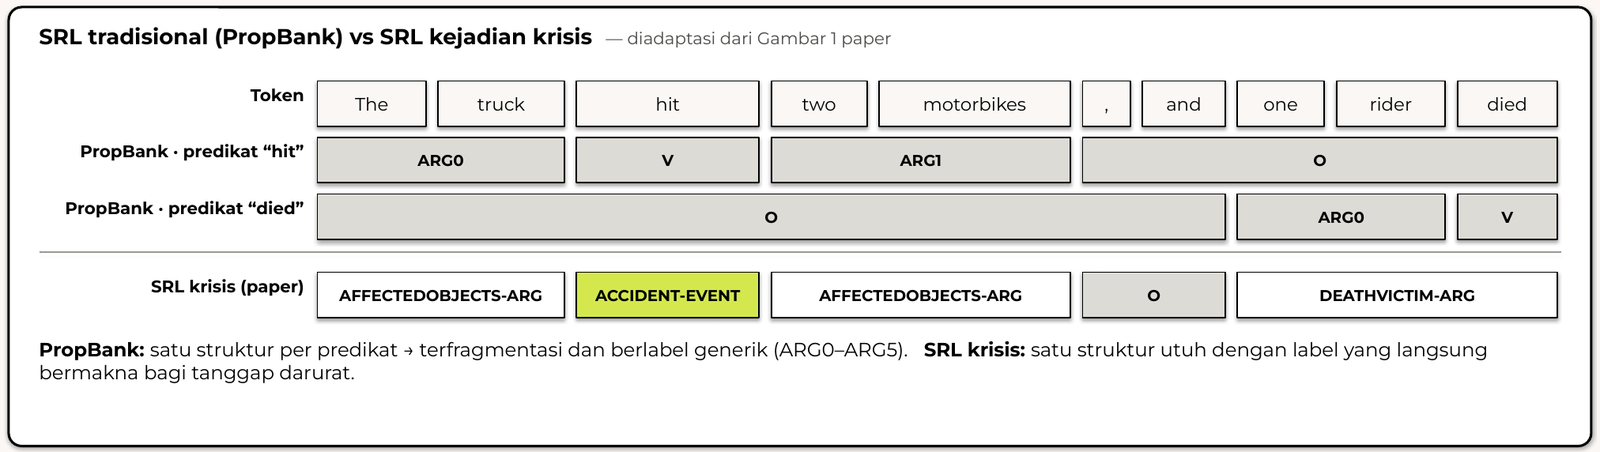

<p style="text-align: center;"><i>Gambar 2.1. Anotasi PropBank dan SRL kejadian krisis pada kalimat yang sama (diadaptasi dari Gambar 1 paper).</i></p>

<p style="text-align: justify;">
Paper karena itu merumuskan SRL tanpa jangkar predikat sebagai pelabelan token dengan 15 label: lima label kejadian (termasuk FALSE-EVENT), sembilan argumen khusus krisis, dan O [1]. Pada Gambar 2.1, “the truck” dan “two motorbikes” sama-sama menjadi AFFECTEDOBJECTS-ARG dalam satu struktur, sedangkan PropBank memecahnya ke dua predikat dengan label generik. Karena tugasnya berbentuk pelabelan urutan, notebook ini mengevaluasinya per token dan per span (Bab 9) serta memakai CRF sebagai baseline [8].
</p>

### 2.3 Faktualitas Kejadian dan Label FALSE-EVENT

<p style="text-align: justify;">
Kata bencana dalam teks tidak selalu menandakan kejadian yang benar-benar terjadi. FactBank menganotasi faktualitas kejadian menurut sumbernya, yaitu tingkat kepastian (pasti, mungkin) dan polaritas (terjadi atau tidak) dengan memperhatikan modalitas dan negasi [9]. Di media sosial, pilihan kata pengantar sumber juga menggeser penilaian faktualitas pembaca [10]. Paper mengemas aspek ini sebagai label FALSE-EVENT untuk tweet berisi peringatan, spekulasi, atau informasi yang belum terverifikasi [1].
</p>

<p style="text-align: justify;">
Ambiguitas ini tampak pada data “banjir” dan “gempa” lebih sering berlabel FALSE-EVENT daripada kejadian nyata (5.3), dan aturan kata kunci hanya mencakup 43,5% tweet FALSE-EVENT (5.4). Paper juga melaporkan kesalahan FLOOD-EVENT → FALSE-EVENT, misalnya pada frasa “mengantisipasi banjir” [1]. 
</p>

### 2.4 Model Bahasa untuk Bahasa Indonesia

<p style="text-align: justify;">
BERT melatih encoder dua arah dengan masked language modeling, sehingga setiap token memperoleh konteks kiri dan kanan [11]. IndoBERT menerapkan pretraining ini pada sekitar 220 juta kata bahasa Indonesia [12], dan IndoRoBERTa mengikuti resep RoBERTa [13]. GPT-2 bersifat autoregresif, sehingga setiap token hanya melihat konteks sebelumnya [14]. Komodo-7B adalah LLM 7 miliar parameter untuk bahasa Indonesia, Inggris, dan 11 bahasa daerah [15]. Paper membandingkan keempat model ini dengan BiLSTM memakai hyperparameter yang sama [1].
</p>

<p style="text-align: justify;">
Arah konteks relevan bagi FALSE-EVENT karena status kejadian sering ditentukan kata sesudahnya, misalnya “banjir … tidak ada korban jiwa”. Model kausal seperti GPT-2 karena itu diperkirakan lebih lemah pada label kejadian dan batas span, dugaan ini diuji melalui F1 span dan F1 per label (8.5, 10.1).
</p>

### 2.5 Self-training dan Pseudo-label

<p style="text-align: justify;">
Self-training melatih model pada data berlabel, memprediksi data tanpa label, lalu menambahkan prediksi yang memiliki keyakinan sesuai dengan treshold tertentu sebagai pseudo-label untuk pelatihan berikutnya [16][17]. Risiko utamanya adalah <i>confirmation bias</i>: pseudo-label yang salah ikut dipelajari dan diperkuat pada iterasi selanjutnya [18]. Skor softmax yang tinggi juga belum tentu benar karena jaringan neural modern cenderung terlalu yakin [19]. Seleksi pseudo-label yang memperhitungkan ketidakpastian terbukti mengurangi label keliru [20].
</p>

<p style="text-align: justify;">
Algorithm 1 paper menghitung rata-rata keyakinan seluruh token per tweet, menerima tweet dengan rata-rata ≥ θ (0,7/0,8/0,9), menggabungkannya dengan data berlabel, lalu membagi ulang 80/20 menjadi latih dan validasi pada setiap iterasi [1]. Notebook ini menguji dua konsekuensinya: (a) token O yang mencapai 69% dan biasanya sangat yakin dapat meloloskan tweet yang token pentingnya masih ragu (Bab 11); (b) pembagian ulang membuat validasi ikut berisi pseudo-label, sehingga protokolnya diperbaiki pada 9.2.
</p>

### 2.6 Analisis dan Percobaan pada Paper

<p style="text-align: justify;">
Tabel berikut memetakan setiap analisis dan percobaan paper ke bagian notebook yang mereproduksinya.
</p>

| No | Analisis / percobaan paper | Hasil yang dilaporkan paper | Status di notebook |
|---|---|---|---|
| 1 | Validasi anotasi: Cohen's Kappa dan IAA per label (Tabel 3) | Kappa 0,924; F1 antar-anotator WOUNDVICTIM-ARG 0,84 dan DEATHVICTIM-ARG 0,91 | Tidak diulang karena label tiap anotator tidak dirilis; label meragukan ditinjau di 5.3 |
| 2 | Statistik linguistik (Tabel 2), distribusi label (Tabel 5), kata tersering REASON-ARG (Gambar 4–5) | O 69,74% (latih) dan 67,85% (uji); FALSE-EVENT muncul di semua jenis kejadian | Direproduksi di Bab 5; total uji FALSE-EVENT dan STREET-ARG pada Tabel 5 tertukar |
| 3 | Self-training dengan filter ambang (Algorithm 1) pada lima model dengan hyperparameter sama (Tabel 6) | Ambang yang lebih tinggi menghasilkan pseudo-label yang lebih bersih | Direproduksi di Bab 8 dan ablasi 10.2 |
| 4 | Perbandingan model (Tabel 7) | F1 pada θ = 0,9: IndoBERT 0,863; Komodo 0,857; IndoRoBERTa 0,844; GPT2 0,824; BiLSTM 0,56–0,59 | Direproduksi di 10.1, ditambah baseline mayoritas, CRF, macro-F1 tanpa O, dan F1 span |
| 5 | Sensitivitas ambang | IndoBERT 0,721 (θ = 0,7), 0,818 (θ = 0,8), 0,863 (θ = 0,9) | Diuji ulang di 10.2 |
| 6 | F1 per label (Gambar 7–8) | WOUNDVICTIM-ARG terendah | Dibandingkan di 10.1 |
| 7 | Error analysis: matriks konfusi (Gambar 9) dan contoh prediksi (Tabel 8) | FLOOD-EVENT → FALSE-EVENT, WOUNDVICTIM-ARG ↔ DEATHVICTIM-ARG, PLACE-ARG → STREET-ARG (“Kuningan”) | Diulang di Bab 11 untuk CRF dan IndoBERT |
| 8 | Uji lintas domain pada 5 dokumen berita (1.055 token, Tabel 9) | F1 IndoBERT 0,863 → 0,899; WOUNDVICTIM-ARG 0,377 → 0,200 | Tidak diulang karena data berita tidak termasuk dataset |
| 9 | Perbandingan kualitatif dengan PropBank (Tabel 10) | Skema krisis menangkap tweet tanpa predikat eksplisit dan ambiguitas faktual | Dibahas secara konseptual di 2.2 |

<p style="text-align: justify;">
Paper tidak melaporkan baseline non-neural, metrik tanpa label O, F1 span, variasi seed, maupun validasi yang terpisah dari pseudo-label. Kekosongan ini menjadi tambahan analisis pada notebook.
</p>

### 2.7 Evaluasi dan Reproduksibilitas

<p style="text-align: justify;">
Pelabelan urutan seperti SRL lazim dinilai dengan F1 span: frasa dihitung benar hanya bila batas dan labelnya tepat [21]. Paper memakai F1 berbobot per token yang menyertakan O; metrik ini dapat tinggi walaupun label peran jarang dikenali, seperti ditunjukkan baseline mayoritas (Bab 7).
</p>

<p style="text-align: justify;">
Hasil reproduksi juga dipengaruhi pembagian data dan seed. Peringkat sistem dapat berubah bila pembagian latih–uji diganti [22], dan seed saja dapat menggeser F1 pelabelan urutan secara signifikan [23]. Pada semi-supervised learning, baseline terawasi yang kuat dan validasi yang realistis diperlukan agar manfaat data tanpa label tidak dilebih-lebihkan [24], sedangkan pemilihan model berdasarkan data evaluasi menimbulkan bias seleksi [25]. Karena anggota data uji paper tidak dirilis, selisih skor dengan paper dibaca sebagai indikasi, bukan bukti.
</p>

### 2.8 Pertanyaan Penelitian dan Cakupan

<ul style="text-align: justify;">
<li><b>RQ1.</b> Sejauh mana hasil paper dapat direproduksi dengan dataset publik dan informasi yang tersedia?</li>
<li><b>RQ2.</b> Seberapa besar kontribusi self-training dan ambang keyakinan dibandingkan model awal yang hanya memakai data berlabel?</li>
<li><b>RQ3.</b> Bagaimana kinerja model bila dinilai dengan macro-F1 tanpa O, F1 span, dan F1 per label, dan di label mana kesalahannya terkonsentrasi?</li>
</ul>

<p style="text-align: justify;">
Checkpoint 1 berfokus pada reproduksi dan analisis. Temuannya dirumuskan menjadi tiga research gap dan dua novelty (16.2–16.3) yang diuji pada Checkpoint 2 dengan protokol validasi 9.2.
</p>

<a id="bab-3"></a>
## 3. Penelitian Terkait dan Rancangan Alur Penelitian

### 3.1 Penelitian Terkait

| Referensi | Metode | Temuan penting | Hubungan dengan project |
|---|---|---|---|
| Ariyanto dkk., 2025 [1] | SRL tanpa predikat dengan 15 label krisis; self-training dengan filter ambang; IndoBERT, IndoRoBERTa, GPT-2, Komodo, BiLSTM | IndoBERT terbaik (F1 0,863, θ = 0,9); kesalahan utama FLOOD→FALSE dan WOUND↔DEATH | Paper yang direproduksi |
| Palmer dkk., 2005 [6]; He dkk., 2017 [7] | SRL berpusat predikat (ARG0–ARG5); BiLSTM mendalam | Skema dan model standar SRL | Pembanding konseptual skema krisis (2.2) |
| Saurí & Pustejovsky, 2009 [9]; Soni dkk., 2014 [10] | Anotasi dan pemodelan faktualitas kejadian | Faktualitas ditentukan modalitas, negasi, dan kata pengantar sumber | Dasar analisis FALSE-EVENT |
| Koto dkk., 2020 [12] | IndoBERT | Model dasar yang kuat untuk bahasa Indonesia | Model utama |
| Lafferty dkk., 2001 [8] | CRF | Pelabelan urutan dengan fitur eksplisit | Baseline konvensional |
| Lee, 2013 [17]; Arazo dkk., 2020 [18]; Rizve dkk., 2021 [20] | Pseudo-label dan seleksinya | Pseudo-label salah dapat diperkuat; seleksi berbasis ketidakpastian mengurangi derau | Dasar analisis self-training dan Novelty 2 |
| Chen dkk., 2019 [26] | BERT untuk klasifikasi intent (kalimat) dan slot filling (token) secara bersama | Pelatihan bersama meningkatkan kedua tugas | Dasar Novelty 1: status kejadian tingkat tweet dan label token |
| Seeberger & Riedhammer, 2022 [27] | Multi-task learning dan entity-masked LM untuk klasifikasi tweet krisis | Tugas tambahan membantu klasifikasi tweet krisis | Pembanding desain multi-task pada domain krisis |
| Luo dkk., 2020 [28] | Representasi token NER diperkaya representasi kalimat | Konteks kalimat membantu label token yang ambigu | Alternatif arsitektur Novelty 1 |

### 3.2 Rancangan Alur Penelitian

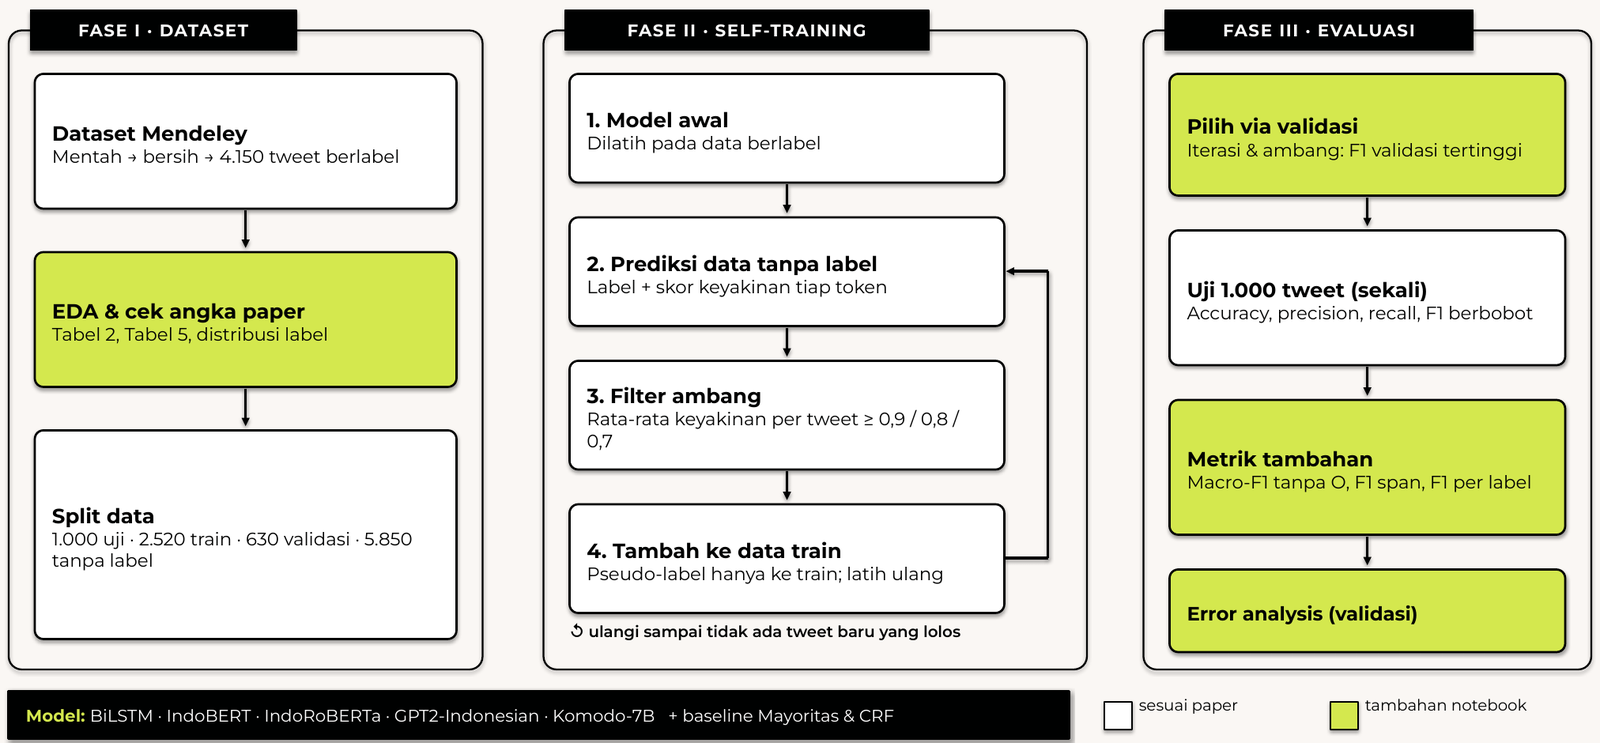

<p style="text-align: center;"><i>Gambar 3.1. Pipeline penelitian. Kotak putih mengikuti paper; kotak hijau adalah tambahan notebook.</i></p>

### 3.3 Penjelasan Alur

<ul style="text-align: justify;">
<li><b>Fase I — Dataset.</b> Data Mendeley (mentah → preprocessing → 4.150 tweet berlabel) diperiksa terhadap Tabel 2 dan Tabel 5 paper (Bab 5), lalu dibagi menjadi 1.000 tweet uji (250 per kejadian), 2.520 latih, 630 validasi, dan 5.850 tweet tanpa label (5.1, 6.2).</li>
<li><b>Fase II — Self-training.</b> Model awal dilatih pada data berlabel, memprediksi data tanpa label beserta skor keyakinan per token, lalu tweet dengan rata-rata keyakinan ≥ θ ditambahkan dan model dilatih ulang sampai tidak ada tweet baru yang lolos (Bab 8). Setiap ambang dimulai dari checkpoint awal yang sama.</li>
<li><b>Fase III — Evaluasi.</b> Metrik paper dilengkapi macro-F1 tanpa O, F1 span, dan F1 per label (Bab 9–10), kemudian error analysis (Bab 11).</li>
<li><b>Protokol.</b> Gambar 3.1 menampilkan protokol perbaikan. Run utama Bab 8–10 masih mengikuti paper: pseudo-label digabung lalu dibagi ulang, dan model dipilih dengan F1 uji. Perbedaan dan hasil awal protokol perbaikan dibahas di 9.2.</li>
</ul>


<a id="bab-4"></a>
## 4. Pengaturan Eksperimen

<p style="text-align: justify;">
Reproduksi memakai seed 42, 1.000 tweet uji, 3.150 tweet latih berlabel, dan 5.850 tweet tanpa label. Parameter utama mengikuti paper; rincian yang tidak tersedia ditetapkan dalam implementasi. Daftar sampel asli tidak tersedia, sehingga reproduksi tidak identik pada setiap tahap.
</p>


In [18]:
import importlib, importlib.util, importlib.metadata, subprocess, sys

if importlib.util.find_spec("torch") is None:
    raise ImportError("PyTorch belum terpasang. Untuk GPU RTX seri 50 gunakan build CUDA 12.8: "
                      "pip install torch --index-url https://download.pytorch.org/whl/cu128")

PUSTAKA = {
    "transformers": "transformers", "accelerate": "accelerate", "sklearn": "scikit-learn",
    "sklearn_crfsuite": "sklearn-crfsuite", "pandas": "pandas", "numpy": "numpy", "matplotlib": "matplotlib",
}
PUSTAKA_KOMODO = {"peft": "peft", "bitsandbytes": "bitsandbytes"}

kurang = [pip for mod, pip in PUSTAKA.items() if importlib.util.find_spec(mod) is None]
if kurang:
    print("Memasang pustaka yang belum tersedia:", ", ".join(kurang))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *kurang])
for mod, pip_name in PUSTAKA_KOMODO.items():
    if importlib.util.find_spec(mod) is None:
        r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", pip_name])
        if r.returncode != 0:
            print(f"Peringatan: {pip_name} gagal dipasang; hanya berpengaruh bila RUN_KOMODO = True.")
importlib.invalidate_caches()

print(f"{'pustaka':18s} versi")
for pip_name in ["torch"] + list(PUSTAKA.values()) + list(PUSTAKA_KOMODO.values()):
    try:
        print(f"{pip_name:18s} {importlib.metadata.version(pip_name)}")
    except importlib.metadata.PackageNotFoundError:
        print(f"{pip_name:18s} belum terpasang")

pustaka            versi
torch              2.7.0+cu128
transformers       5.20.2
accelerate         1.15.0
scikit-learn       1.9.1
sklearn-crfsuite   0.5.0
pandas             3.0.5
numpy              2.5.4
matplotlib         3.11.2
peft               0.21.2
bitsandbytes       0.50.2


In [19]:
pip install -U scikit-learn


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [20]:
import os, re, json, time, glob, random, pickle, platform, collections
from contextlib import nullcontext

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import sklearn
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
from IPython.display import display, Markdown

pd.set_option("display.max_colwidth", 200)
pd.set_option("display.width", 200)

RUN_TRANSFORMERS = True
RUN_KOMODO = False
REQUIRE_GPU = True
RESUME = True
USE_BF16 = False
DATA_NAME = "Semantic-Role-Labeling-Datasets-for-Crisis-Event"
OUT_DIR = "outputs"

SEED = 42
LEARNING_RATE = 2e-5
BATCH_SIZE = 16
EPOCHS = 10
WEIGHT_DECAY = 0.01
THRESHOLDS = [0.9, 0.8, 0.7]
TEST_PER_EVENT = 250
N_UNLABELED = 5850
VAL_RATIO = 0.2

MAX_LEN = 256
PATIENCE = 3
MAX_GRAD_NORM = 1.0
MAX_ITER = None

TRANSFORMER_MODELS = {
    "IndoBERT": "indolem/indobert-base-uncased",
    "IndoRoBERTa": "w11wo/indo-roberta-small",
    "GPT2-Indonesian": "cahya/gpt2-small-indonesian-522M",
}
KOMODO_MODEL = "Yellow-AI-NLP/komodo-7b-base"


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed()
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
AMP_DTYPE = torch.bfloat16 if (USE_BF16 and DEVICE == "cuda" and torch.cuda.is_bf16_supported()) else None
for sub in ["results", "models", "figures"]:
    os.makedirs(os.path.join(OUT_DIR, sub), exist_ok=True)


def cari_folder_data(nama=DATA_NAME, maks_kedalaman=5):
    langsung = os.path.join("data", nama)
    if os.path.isfile(os.path.join(langsung, "3-Labeled Data", "all-labeled-data.csv")):
        return langsung
    temuan = []
    for root, dirs, files in os.walk("."):
        if root.count(os.sep) >= maks_kedalaman:
            dirs[:] = []
            continue
        dirs[:] = [d for d in dirs if not d.startswith(".") and d not in ("outputs", "__pycache__")]
        if os.path.basename(root) == "3-Labeled Data" and "all-labeled-data.csv" in files:
            temuan.append(os.path.normpath(os.path.dirname(root)))
    if not temuan:
        raise FileNotFoundError(f"Folder dataset tidak ditemukan di bawah {os.path.abspath('.')}. "
                                f"Struktur yang dibaca: data/{nama}/3-Labeled Data/all-labeled-data.csv")
    temuan.sort(key=lambda p: (os.path.basename(p) != nama, len(p)))
    return temuan[0]


DATA_DIR = cari_folder_data()

print("Python  :", platform.python_version())
print("Data    :", DATA_DIR)
print("Device  :", DEVICE)
print("Presisi :", "bf16" if AMP_DTYPE else "fp32")
print("RUN_TRANSFORMERS =", RUN_TRANSFORMERS, "| RUN_KOMODO =", RUN_KOMODO, "| RESUME =", RESUME)

Python  : 3.12.10
Data    : data\Semantic-Role-Labeling-Datasets-for-Crisis-Event
Device  : cuda
Presisi : fp32
RUN_TRANSFORMERS = True | RUN_KOMODO = False | RESUME = True


In [21]:
if DEVICE == "cuda":
    prop = torch.cuda.get_device_properties(0)
    print(f"GPU             : {prop.name} | memori {prop.total_memory / 1e9:.1f} GB | compute capability {prop.major}.{prop.minor}")
    print(f"CUDA (PyTorch)  : {torch.version.cuda} | cuDNN {torch.backends.cudnn.version()}")
    print(f"Arsitektur build: {', '.join(torch.cuda.get_arch_list())}")
    try:
        _x = torch.randn(512, 512, device="cuda")
        _ = (_x @ _x).sum().item()
        print("Uji operasi GPU : berhasil; BiLSTM dan transformer dilatih di GPU")
    except RuntimeError as e:
        raise RuntimeError(f"GPU terdeteksi tetapi operasi CUDA gagal ({e}). Build PyTorch kemungkinan tidak mendukung "
                           f"compute capability {prop.major}.{prop.minor}; RTX seri 50 membutuhkan build CUDA 12.8 (cu128).")
elif (RUN_TRANSFORMERS or RUN_KOMODO) and REQUIRE_GPU:
    if torch.version.cuda is None:
        sebab = ("PyTorch yang terpasang adalah build CPU tanpa CUDA; build GPU untuk RTX seri 50: "
                 "pip install torch --index-url https://download.pytorch.org/whl/cu128")
    else:
        sebab = (f"PyTorch build CUDA {torch.version.cuda} terpasang, tetapi GPU tidak terdeteksi; "
                 "driver NVIDIA perlu diperiksa dengan perintah nvidia-smi")
    raise RuntimeError(f"CUDA tidak tersedia (torch {torch.__version__}). {sebab}. "
                       "Training transformer dihentikan agar tidak berjalan di CPU.")
else:
    print("GPU tidak tersedia pada sesi ini. Bagian transformer tidak dijalankan; CRF dan BiLSTM dijalankan di CPU.")

GPU             : NVIDIA GeForce RTX 5050 Laptop GPU | memori 8.5 GB | compute capability 12.0
CUDA (PyTorch)  : 12.8 | cuDNN 90701
Arsitektur build: sm_50, sm_60, sm_61, sm_70, sm_75, sm_80, sm_86, sm_90, sm_100, sm_120
Uji operasi GPU : berhasil; BiLSTM dan transformer dilatih di GPU


<p style="text-align: justify;">
Fungsi pendukung menyeragamkan status kejadian, pembentukan span, perhitungan metrik, dan penyimpanan hasil.
</p>


In [22]:
REAL_EVENTS = {"FLOOD-EVENT", "FIRE-EVENT", "EARTHQUAKE-EVENT", "ACCIDENT-EVENT"}
EVENT_CODES = {"BAN": "banjir", "GEM": "gempa", "KEB": "kebakaran", "KEC": "kecelakaan"}

EVENT_SERIES = {"banjir": "#2a9d91", "gempa": "#baa44d", "kebakaran": "#c36953", "kecelakaan": "#8a4976"}
EVENT_LABEL_COLORS = {"FLOOD-EVENT": EVENT_SERIES["banjir"], "EARTHQUAKE-EVENT": EVENT_SERIES["gempa"],
                      "FIRE-EVENT": EVENT_SERIES["kebakaran"], "ACCIDENT-EVENT": EVENT_SERIES["kecelakaan"]}
C_REAL, C_FALSE, C_MIX, C_NONE = "#b0505a", "#266ea4", "#9a78c6", "#b9b7b0"
C_ARG, C_O, C_INK, C_GRID = "#b0b4b9", "#e1e2e3", "#2b2f36", "#eceeef"
C_SLATE, C_SLATE_L, C_SAND, C_SAND_L = "#4f6272", "#b7c3cd", "#a8845c", "#dccbb3"
STATUS_COLORS = {"nyata": C_REAL, "tidak nyata": C_FALSE, "campuran": C_MIX, "tanpa kejadian": C_NONE}
STATUS_NAMES = {"nyata": "hanya label kejadian nyata", "tidak nyata": "hanya FALSE-EVENT",
                "campuran": "keduanya", "tanpa kejadian": "tanpa label kejadian"}
MODEL_COLORS = {"BiLSTM": "#c16d45", "IndoBERT": "#2b6cab", "IndoRoBERTa": "#34a08e",
                "GPT2-Indonesian": "#987aca", "Komodo-7B": "#c3b351", "CRF": "#4b4f55",
                "BiLSTM (Adam lr 1e-3)": "#dba585"}
SEQ_CMAP = mpl.colors.LinearSegmentedColormap.from_list("seq_hijau_toska", ["#f4f7f5", "#cfe0da", "#8fbcb1", "#4f8f84", "#24564f"])


def tint(hex_color, f):
    r, g, b = mpl.colors.to_rgb(hex_color)
    return mpl.colors.to_hex((r + (1 - r) * f, g + (1 - g) * f, b + (1 - b) * f))


def ink_on(color):
    r, g, b = mpl.colors.to_rgb(color)
    return "white" if 0.2126 * r + 0.7152 * g + 0.0722 * b < 0.5 else C_INK


def label_color(lab):
    if lab in EVENT_LABEL_COLORS:
        return EVENT_LABEL_COLORS[lab]
    if lab == "FALSE-EVENT":
        return C_FALSE
    if lab == "O":
        return C_O
    return C_ARG


mpl.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#a3a8ad", "axes.labelcolor": C_INK, "xtick.color": "#5b6470", "ytick.color": "#5b6470",
    "axes.grid": True, "grid.color": C_GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlesize": 11, "font.size": 9.5, "legend.frameon": False,
})


def amp_ctx(enabled=True):
    if enabled and AMP_DTYPE is not None:
        return torch.autocast("cuda", dtype=AMP_DTYPE)
    return nullcontext()


def tweet_status(labels):
    s = set(labels)
    real, false = bool(s & REAL_EVENTS), "FALSE-EVENT" in s
    if real and false:
        return "campuran"
    if real:
        return "nyata"
    if false:
        return "tidak nyata"
    return "tanpa kejadian"


def spans(labels):
    out, start, cur = [], None, None
    for i, lab in enumerate(list(labels) + ["O"]):
        if lab != cur:
            if cur not in (None, "O"):
                out.append((start, i, cur))
            start, cur = i, lab
    return out


def evaluate(gold, pred):
    g, p = sum(gold, []), sum(pred, [])
    non_o = [l for l in LABELS if l != "O"]
    acc = accuracy_score(g, p)
    P, R, F, _ = precision_recall_fscore_support(g, p, labels=LABELS, average="weighted", zero_division=0)
    F_wn = precision_recall_fscore_support(g, p, labels=non_o, average="weighted", zero_division=0)[2]
    F_mn = precision_recall_fscore_support(g, p, labels=non_o, average="macro", zero_division=0)[2]
    f_lab = precision_recall_fscore_support(g, p, labels=LABELS, average=None, zero_division=0)[2]
    per_label = {l: float(v) for l, v in zip(LABELS, f_lab)}
    gs = {(i,) + s for i, seq in enumerate(gold) for s in spans(seq)}
    ps = {(i,) + s for i, seq in enumerate(pred) for s in spans(seq)}
    tp = len(gs & ps)
    sp = tp / len(ps) if ps else 0.0
    sr = tp / len(gs) if gs else 0.0
    sf = 2 * sp * sr / (sp + sr) if sp + sr else 0.0
    return {"accuracy": acc, "precision_w": P, "recall_w": R, "f1_w": F,
            "f1_w_noO": F_wn, "f1_macro_noO": F_mn, "f1_span": sf,
            "f1_FALSE": per_label["FALSE-EVENT"], "f1_FLOOD": per_label["FLOOD-EVENT"], "f1_per_label": per_label}


def slug(s):
    return re.sub(r"[^A-Za-z0-9]+", "_", s).strip("_")


def res_path(key):
    return os.path.join(OUT_DIR, "results", slug(key) + ".json")


def save_json(path, obj):
    with open(path, "w") as f:
        json.dump(obj, f)


def load_json(path):
    with open(path) as f:
        return json.load(f)


def fmt(x, d=3):
    return f"{x:.{d}f}".replace(".", ",")


def fth(t):
    return str(t).replace(".", ",")


def fpct(x, d=1):
    return f"{100 * x:.{d}f}".replace(".", ",") + "%"

<p style="text-align: justify;">
Evaluasi mencakup metrik berbobot, macro-F1 tanpa O, F1 per label, dan F1 span. Macro-F1 menyeimbangkan kontribusi label, sedangkan span dianggap benar hanya jika label dan kedua batasnya tepat.
</p>


<a id="bab-5"></a>
## 5. Data dan Exploratory Data Analysis

### 5.1 Deskripsi Dataset

<p style="text-align: justify;">
Dataset Mendeley Data v2 (CC BY 4.0) [4] memuat tweet mentah, hasil preprocessing, dan anotasi token.
</p>

| Folder | Isi | Kolom penting |
|---|---|---|
| `1-Raw Data` | Tweet mentah hasil crawling tahun 2018-2023 per jenis kejadian | `created_at`, `id_str`, `full_text` |
| `2-Preprocessed Data` | Tweet setelah case folding, penghapusan URL/mention/hashtag, normalisasi, penghapusan duplikat, dan penyaringan lokasi Indonesia | `created_at`, `full_text` |
| `3-Labeled Data` | Satu baris per token dari 4.150 tweet berlabel | `text_id`, `id` (token_id), `token`, `entity` (label NER format BIO), `argument` (**label SRL, target**) |

<p style="text-align: justify;">
Target <code>argument</code> berisi 15 label: lima kejadian, sembilan argumen, dan O. Kolom NER <code>entity</code> tidak dipakai sebagai fitur atau target.
</p>

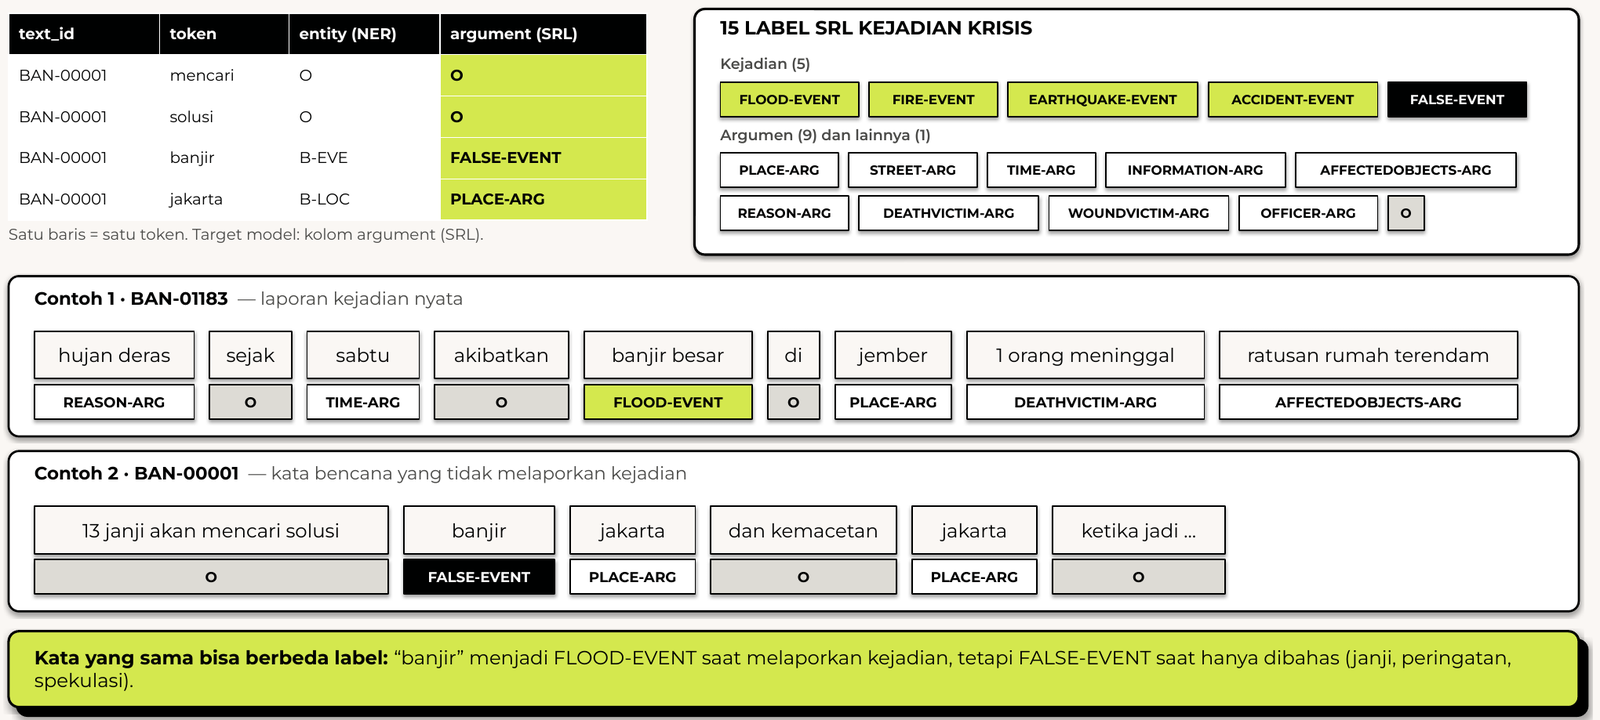

<p style="text-align: center;"><i>Gambar 5.1. Format data per token dan contoh anotasi SRL.</i></p>

<p style="text-align: justify;">
Satu baris mewakili satu token. Pada BAN-01183, penyebab, waktu, kejadian, lokasi, korban, dan objek terdampak masing-masing mendapat label; pada BAN-00001, “banjir” berlabel FALSE-EVENT karena tweet hanya membahas janji penanganan, bukan melaporkan kejadian. Kata yang sama dapat berbeda label menurut konteks, sehingga model perlu membaca kalimat secara utuh.
</p>

<p style="text-align: justify;">
Pembagian tingkat tweet menghasilkan 1.000 data uji dan 3.150 latih berlabel. Data latih neural dibagi 80/20; 5.850 tweet tanpa label disiapkan untuk self-training.
</p>

,kejadian,raw (data),raw (paper),preprocessed (data),preprocessed (paper),berlabel (data)
0,banjir,43028,43028,7321,7321,1250
1,gempa,38286,38286,7408,7408,906
2,kebakaran,149308,149308,33251,33251,1128
3,kecelakaan,39030,39030,8155,8155,866
4,TOTAL,269652,269652,56135,56135,4150


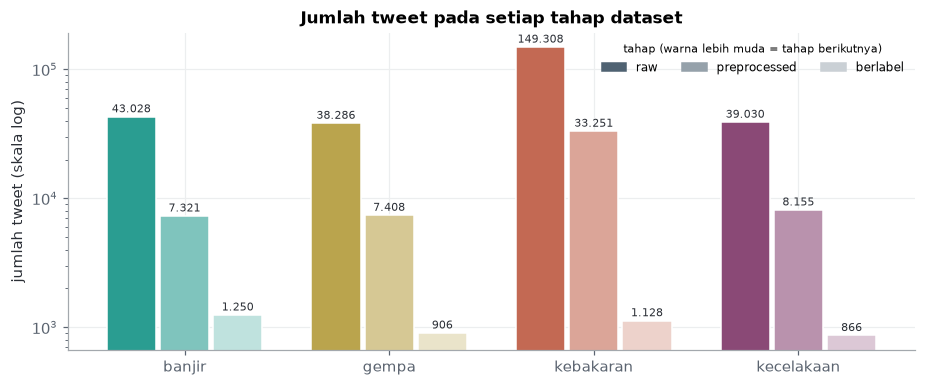

In [23]:
RAW_DIR = os.path.join(DATA_DIR, "1-Raw Data")
PRE_DIR = os.path.join(DATA_DIR, "2-Preprocessed Data")
LAB_CSV = os.path.join(DATA_DIR, "3-Labeled Data", "all-labeled-data.csv")
EV_EN = {"BAN": "flood", "GEM": "earthquake", "KEB": "fire", "KEC": "accident"}

paper_raw = {"flood": 43028, "earthquake": 38286, "fire": 149308, "accident": 39030}
paper_pre = {"flood": 7321, "earthquake": 7408, "fire": 33251, "accident": 8155}
raw_df = {ev: pd.read_csv(os.path.join(RAW_DIR, f"{ev}.csv"), keep_default_na=False) for ev in paper_raw}
pre_df = {ev: pd.read_csv(os.path.join(PRE_DIR, f"{ev}-preprocessed.csv"), keep_default_na=False) for ev in paper_raw}

df_raw = pd.read_csv(LAB_CSV, keep_default_na=False)
lab_tweets_per_ev = df_raw.drop_duplicates("text_id")["text_id"].str[:3].value_counts()

rows = []
for code_, ev in EV_EN.items():
    rows.append({"kejadian": EVENT_CODES[code_], "raw (data)": len(raw_df[ev]), "raw (paper)": paper_raw[ev],
                 "preprocessed (data)": len(pre_df[ev]), "preprocessed (paper)": paper_pre[ev],
                 "berlabel (data)": int(lab_tweets_per_ev[code_])})
stage = pd.DataFrame(rows)
stage.loc[len(stage)] = ["TOTAL"] + stage.iloc[:, 1:].sum().tolist()
display(stage)

fig, ax = plt.subplots(figsize=(8.5, 3.6))
x = np.arange(4)
w = 0.26
ev_cols = [EVENT_SERIES[e] for e in stage["kejadian"].iloc[:4]]
stage_tint = {"raw (data)": 0.0, "preprocessed (data)": 0.4, "berlabel (data)": 0.7}
for k, (col, f) in enumerate(stage_tint.items()):
    vals = stage[col].iloc[:4].values
    ax.bar(x + (k - 1) * w, vals, width=w - 0.02, color=[tint(c, f) for c in ev_cols], edgecolor="white", linewidth=1)
    for xi, v in zip(x + (k - 1) * w, vals):
        ax.text(xi, v * 1.08, f"{v:,}".replace(",", "."), ha="center", fontsize=7.5, color=C_INK)
ax.set_yscale("log")
ax.set_xticks(x)
ax.set_xticklabels(stage["kejadian"].iloc[:4])
ax.set_ylabel("jumlah tweet (skala log)")
ax.set_title("Jumlah tweet pada setiap tahap dataset")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=tint(C_SLATE, f), label=c.replace(" (data)", "")) for c, f in stage_tint.items()],
          ncol=3, loc="upper right", fontsize=8, title="tahap (warna lebih muda = tahap berikutnya)", title_fontsize=7.5)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "figures", "tahap_dataset.png"), dpi=150)
plt.show()

<p style="text-align: justify;">
Jumlah data sesuai paper: 269.652 tweet mentah, 56.135 hasil preprocessing, dan 4.150 berlabel. Kecilnya porsi anotasi mendukung pengujian self-training, tetapi komposisi data berlabel berbeda dari korpus awal.
</p>


created_at,2018,2019,2020,2021,2022,2023
banjir,1226,1183,1381,1315,1056,1160
gempa,1630,943,738,1336,1302,1459
kebakaran,7469,7521,2814,7922,7525,0
kecelakaan,2912,2862,2381,0,0,0


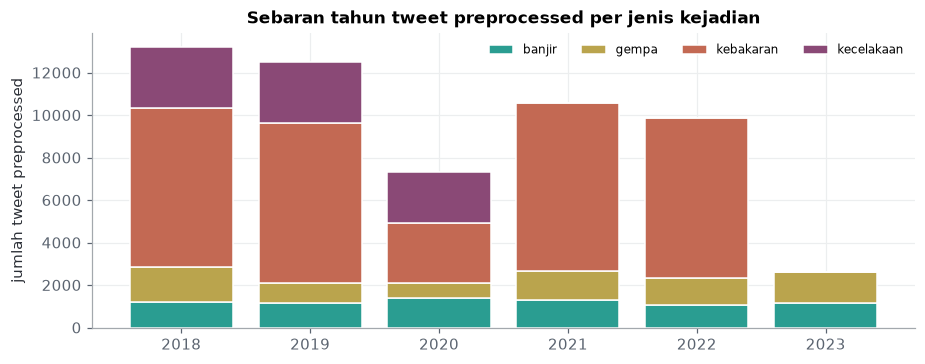

In [24]:
yr = pd.DataFrame({EVENT_CODES[c]: pd.to_datetime(pre_df[ev]["created_at"], errors="coerce", utc=True).dt.year.value_counts()
                   for c, ev in EV_EN.items()}).fillna(0).astype(int).sort_index()
display(yr.T)

fig, ax = plt.subplots(figsize=(8.5, 3.4))
bottom = np.zeros(len(yr))
for ev in yr.columns:
    ax.bar(yr.index.astype(str), yr[ev].values, bottom=bottom, color=EVENT_SERIES[ev], label=ev,
           edgecolor="white", linewidth=1)
    bottom += yr[ev].values
ax.set_ylabel("jumlah tweet preprocessed")
ax.set_title("Sebaran tahun tweet preprocessed per jenis kejadian")
ax.legend(ncol=4, fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "figures", "sebaran_tahun.png"), dpi=150)
plt.show()

<p style="text-align: justify;">
Cakupan tahun berbeda antarkejadian: banjir dan gempa tersedia pada 2018–2023, kebakaran tidak mencakup 2023, dan kecelakaan hanya 2018–2020. Pembagian acak belum menguji generalisasi lintas waktu.
</p>


In [25]:
print("Ukuran file berlabel:", df_raw.shape, "(satu baris = satu token)")
print("Tipe data:\n" + df_raw.dtypes.to_string())
display(df_raw.head(12))

empty_tok = df_raw["token"].astype(str).str.strip() == ""
df = df_raw[~empty_tok].copy()
tweets = []
for tid, g in df.groupby("text_id", sort=False):
    tweets.append({"text_id": tid, "event": tid[:3], "tokens": g["token"].astype(str).tolist(),
                   "labels": g["argument"].tolist(), "entity": g["entity"].tolist()})

LABELS = ["O"] + sorted(l for l in df["argument"].unique() if l != "O")
label2id = {l: i for i, l in enumerate(LABELS)}
id2label = {i: l for l, i in label2id.items()}
n_tok = len(df_raw)

print(f"Jumlah tweet berlabel : {len(tweets):,} (paper: 3.150 latih + 1.000 test = 4.150)")
print(f"Jumlah baris token    : {n_tok:,} (paper: 76.298 latih + 22.908 test = 99.206)")
print(f"Token kosong          : {int(empty_tok.sum())}")
print("Jumlah label          :", len(LABELS))

Ukuran file berlabel: (99206, 5) (satu baris = satu token)
Tipe data:
text_id     str
id          str
token       str
entity      str
argument    str


,text_id,id,token,entity,argument
0,BAN-00001,BAN-00001.001,13,O,O
1,BAN-00001,BAN-00001.002,janji,O,O
2,BAN-00001,BAN-00001.003,akan,O,O
3,BAN-00001,BAN-00001.004,mencari,O,O
4,BAN-00001,BAN-00001.005,solusi,O,O
5,BAN-00001,BAN-00001.006,banjir,B-EVE,FALSE-EVENT
6,BAN-00001,BAN-00001.007,jakarta,B-LOC,PLACE-ARG
7,BAN-00001,BAN-00001.008,dan,O,O
8,BAN-00001,BAN-00001.009,kemacetan,O,O
9,BAN-00001,BAN-00001.010,jakarta,B-LOC,PLACE-ARG


Jumlah tweet berlabel : 4,150 (paper: 3.150 latih + 1.000 test = 4.150)
Jumlah baris token    : 99,206 (paper: 76.298 latih + 22.908 test = 99.206)
Token kosong          : 4
Jumlah label          : 15


<p style="text-align: justify;">
Dataset memuat 4.150 tweet, 99.206 token, dan 15 label SRL; setelah empat token kosong dihapus, tersisa 99.202 token. Target model adalah kolom <code>argument</code>. Contoh kata “banjir” berlabel FALSE-EVENT menegaskan pentingnya konteks.
</p>


In [26]:
rng = random.Random(SEED)
test, train_labeled = [], []
for ev in sorted(EVENT_CODES):
    group = [t for t in tweets if t["event"] == ev]
    rng.shuffle(group)
    test += group[:TEST_PER_EVENT]
    train_labeled += group[TEST_PER_EVENT:]

split_tbl = pd.DataFrame({
    "latih berlabel (reproduksi)": collections.Counter(EVENT_CODES[t["event"]] for t in train_labeled),
    "latih berlabel (paper)": {"banjir": 1000, "gempa": 656, "kebakaran": 878, "kecelakaan": 616},
    "uji (reproduksi)": collections.Counter(EVENT_CODES[t["event"]] for t in test),
    "uji (paper)": {"banjir": 250, "gempa": 250, "kebakaran": 250, "kecelakaan": 250},
})
split_tbl.loc["TOTAL"] = split_tbl.sum()
display(split_tbl)
print("Jumlah token latih:", sum(len(t["tokens"]) for t in train_labeled), "| jumlah token uji:", sum(len(t["tokens"]) for t in test))

ex = next(t for t in tweets if t["text_id"] == "BAN-01183")
display(pd.DataFrame({"token": ex["tokens"], "argument (target)": ex["labels"], "entity": ex["entity"]}).T)

,latih berlabel (reproduksi),latih berlabel (paper),uji (reproduksi),uji (paper)
banjir,1000,1000,250,250
gempa,656,656,250,250
kebakaran,878,878,250,250
kecelakaan,616,616,250,250
TOTAL,3150,3150,1000,1000


Jumlah token latih: 74993 | jumlah token uji: 24209


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
token,hujan,deras,sejak,sabtu,akibatkan,banjir,besar,di,jember,1,orang,meninggal,ratusan,rumah,terendam
argument (target),REASON-ARG,REASON-ARG,O,TIME-ARG,O,FLOOD-EVENT,FLOOD-EVENT,O,PLACE-ARG,DEATHVICTIM-ARG,DEATHVICTIM-ARG,DEATHVICTIM-ARG,AFFECTEDOBJECTS-ARG,AFFECTEDOBJECTS-ARG,AFFECTEDOBJECTS-ARG
entity,B-ARG,I-ARG,O,B-ARG,O,B-EVE,I-EVE,O,B-LOC,B-ARG,I-ARG,I-ARG,B-ARG,I-ARG,I-ARG


<p style="text-align: justify;">
Pembagian menghasilkan 3.150 tweet latih (74.993 token) dan 1.000 tweet uji (24.209 token). Jumlah tweet sesuai paper, tetapi jumlah token uji berbeda (paper 22.908), sehingga anggota data uji dan skor reproduksi tidak identik.
</p>

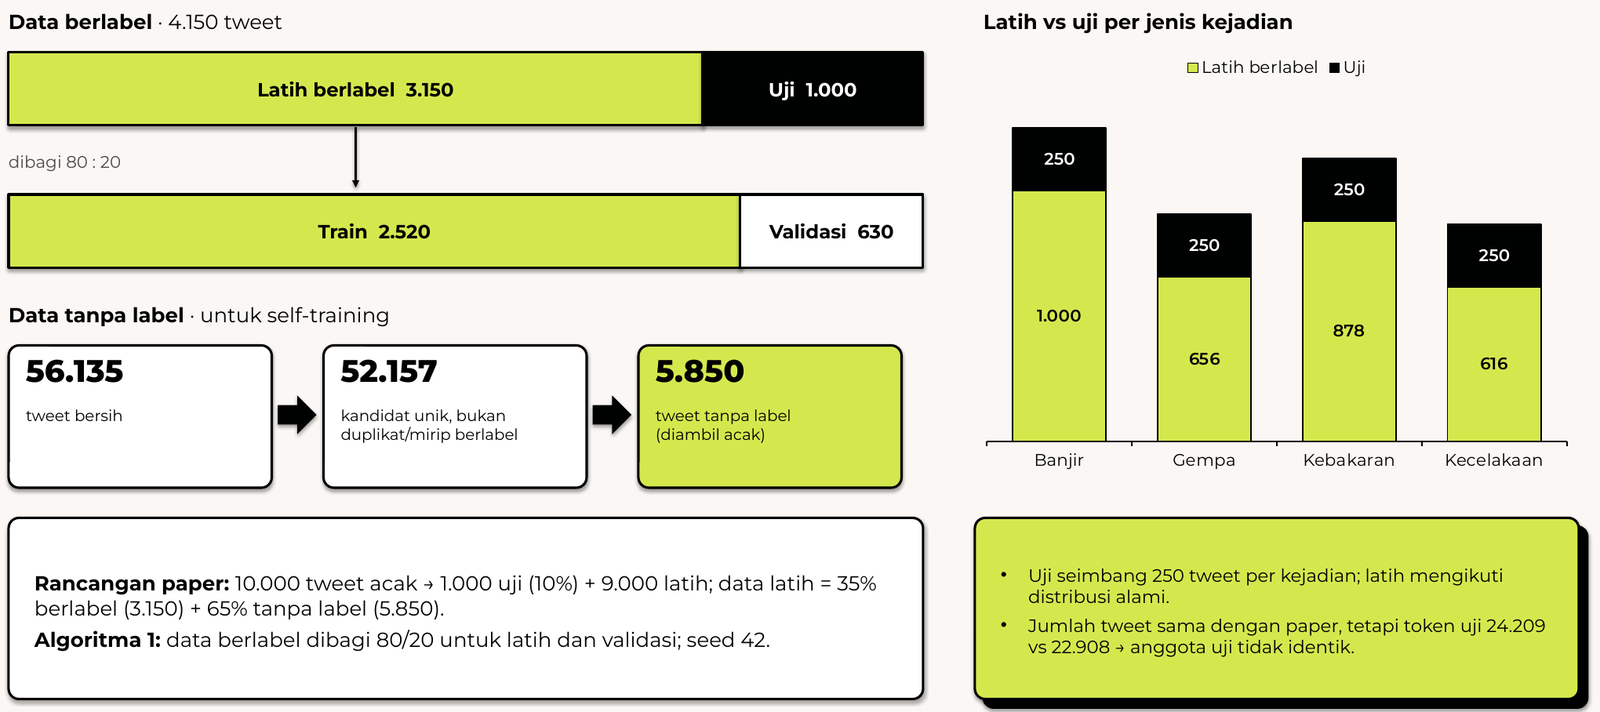

<p style="text-align: center;"><i>Gambar 5.2. Pembagian data berlabel dan penyusunan data tanpa label.</i></p>

<p style="text-align: justify;">
Data uji seimbang 250 tweet per kejadian, sedangkan data latih mengikuti distribusi alami (banjir 1.000 tweet, kecelakaan 616 tweet). Untuk model neural, 3.150 tweet latih dibagi 80/20 menjadi 2.520 latih dan 630 validasi dengan seed 42. Sebanyak 5.850 tweet tanpa label diambil dari 52.157 kandidat yang bukan duplikat atau mirip data berlabel (6.2).
</p>

<p style="text-align: justify;">
Ukuran korpus sesuai paper, tetapi pembagian sampel dan cakupan tahun membatasi perbandingan hasil. Analisis berikut menelaah distribusi label dan span.
</p>


### 5.2 Analisis Target dan Distribusi Data

<p style="text-align: justify;">
Analisis mencakup distribusi label, status kejadian, panjang span, panjang tweet, dan kosakata. Unit perhitungan dibedakan antara token, tweet, dan span.
</p>


In [27]:
TABLE5 = {
    "O": ([18302, 8030, 14952, 11925], [3743, 3060, 4335, 4406], 53209, 15544),
    "PLACE-ARG": ([2340, 894, 2934, 1697], [554, 342, 914, 554], 7865, 2364),
    "FALSE-EVENT": ([982, 221, 450, 1017], [143, 100, 101, 434], 2670, 949),
    "STREET-ARG": ([145, 991, 1062, 7], [60, 546, 334, 9], 2205, 778),
    "AFFECTEDOBJECTS-ARG": ([190, 592, 1279, 60], [70, 207, 360, 31], 2121, 668),
    "TIME-ARG": ([260, 230, 943, 392], [94, 101, 275, 129], 1825, 599),
    "OFFICER-ARG": ([415, 104, 705, 444], [112, 34, 192, 107], 1668, 445),
    "INFORMATION-ARG": ([335, 390, 153, 683], [50, 124, 30, 212], 1561, 416),
    "FIRE-EVENT": ([0, 1, 644, 0], [0, 0, 189, 0], 645, 189),
    "REASON-ARG": ([253, 128, 170, 46], [70, 39, 37, 16], 597, 162),
    "ACCIDENT-EVENT": ([0, 472, 0, 0], [0, 211, 0, 0], 472, 211),
    "DEATHVICTIM-ARG": ([76, 145, 192, 27], [17, 109, 43, 23], 440, 192),
    "EARTHQUAKE-EVENT": ([2, 0, 0, 438], [1, 0, 0, 138], 440, 139),
    "FLOOD-EVENT": ([300, 0, 3, 0], [167, 0, 0, 0], 303, 167),
    "WOUNDVICTIM-ARG": ([86, 119, 68, 4], [13, 40, 23, 9], 277, 85),
}
cnt = df_raw["argument"].value_counts()
rows = []
for lab, (tr, te, tr_tot, te_tot) in TABLE5.items():
    rows.append({"label": lab, "jumlah di data": int(cnt.get(lab, 0)), "% di data": 100 * cnt.get(lab, 0) / n_tok,
                 "total paper (tertulis)": tr_tot + te_tot, "total paper (jumlah per kejadian)": sum(tr) + sum(te),
                 "uji paper: tertulis": te_tot, "uji paper: jumlah per kejadian": sum(te)})
t5 = pd.DataFrame(rows).sort_values("jumlah di data", ascending=False).reset_index(drop=True)
display(t5.style.format({"% di data": "{:.2f}"}))
bad = t5[t5["uji paper: tertulis"] != t5["uji paper: jumlah per kejadian"]]
print("Baris Tabel 5 dengan total tertulis yang berbeda dari jumlah per kejadian:")
display(bad[["label", "uji paper: tertulis", "uji paper: jumlah per kejadian", "jumlah di data"]])

,label,jumlah di data,% di data,total paper (tertulis),total paper (jumlah per kejadian),uji paper: tertulis,uji paper: jumlah per kejadian
0,O,68753,69.30,68753,68753,15544,15544
1,PLACE-ARG,10229,10.31,10229,10229,2364,2364
2,FALSE-EVENT,3448,3.48,3619,3448,949,778
3,STREET-ARG,3154,3.18,2983,3154,778,949
4,AFFECTEDOBJECTS-ARG,2789,2.81,2789,2789,668,668
5,TIME-ARG,2424,2.44,2424,2424,599,599
6,OFFICER-ARG,2113,2.13,2113,2113,445,445
7,INFORMATION-ARG,1977,1.99,1977,1977,416,416
8,FIRE-EVENT,834,0.84,834,834,189,189
9,REASON-ARG,759,0.77,759,759,162,162


Baris Tabel 5 dengan total tertulis yang berbeda dari jumlah per kejadian:


,label,uji paper: tertulis,uji paper: jumlah per kejadian,jumlah di data
2,FALSE-EVENT,949,778,3448
3,STREET-ARG,778,949,3154


<p style="text-align: justify;">
Frekuensi label sesuai komponen Tabel 5 paper, tetapi total uji FALSE-EVENT dan STREET-ARG tampaknya tertukar (949 dan 778). Analisis memakai jumlah komponen yang konsisten dengan data.
</p>


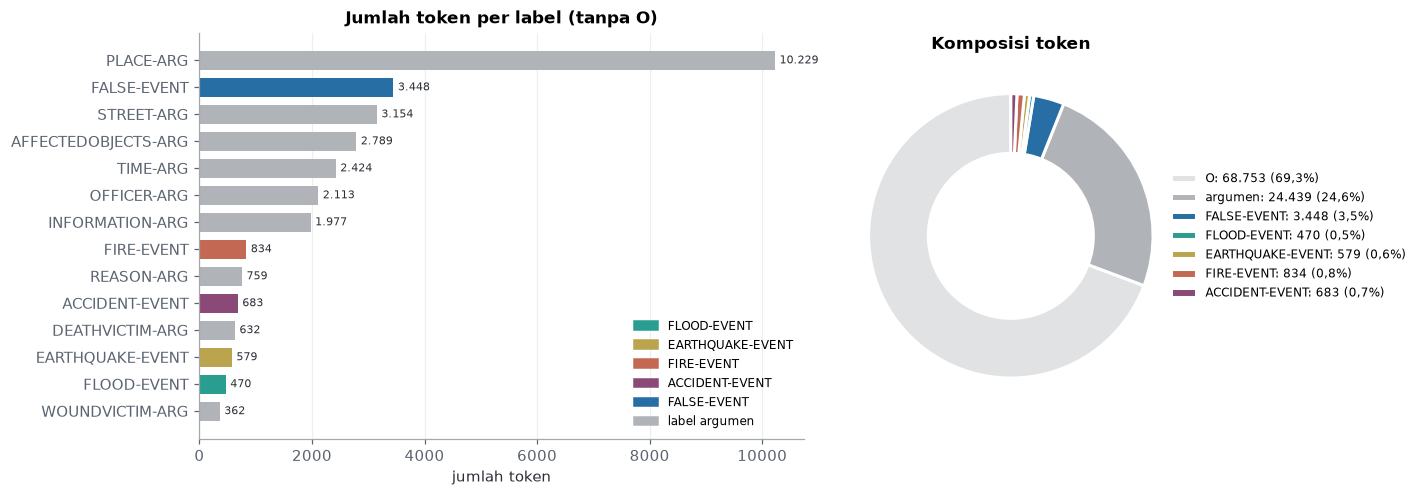

In [28]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.7, 1]})
c_noO = cnt.drop("O").sort_values()
ax[0].barh(c_noO.index, c_noO.values, color=[label_color(l) for l in c_noO.index], height=0.7)
for y, v in enumerate(c_noO.values):
    ax[0].text(v + 80, y, f"{v:,}".replace(",", "."), va="center", fontsize=7.5, color=C_INK)
ax[0].set_title("Jumlah token per label (tanpa O)")
ax[0].set_xlabel("jumlah token")
ax[0].grid(axis="y", visible=False)
from matplotlib.patches import Patch
EV_LABEL_ORDER = ["FLOOD-EVENT", "EARTHQUAKE-EVENT", "FIRE-EVENT", "ACCIDENT-EVENT"]
ax[0].legend(handles=[Patch(color=label_color(l), label=l) for l in EV_LABEL_ORDER + ["FALSE-EVENT"]]
             + [Patch(color=C_ARG, label="label argumen")], loc="lower right", fontsize=8)
groups = pd.Series({"O": cnt["O"], "argumen": cnt[[l for l in cnt.index if l.endswith("-ARG")]].sum(),
                    "FALSE-EVENT": cnt["FALSE-EVENT"], **{l: cnt[l] for l in EV_LABEL_ORDER}})
wedges, _ = ax[1].pie(groups.values, colors=[C_O, C_ARG, C_FALSE] + [label_color(l) for l in EV_LABEL_ORDER], startangle=90,
                      wedgeprops={"width": 0.42, "edgecolor": "white", "linewidth": 2})
ax[1].legend(wedges, [f"{k}: {v:,}".replace(",", ".") + f" ({fpct(v / n_tok)})" for k, v in groups.items()],
             loc="center left", bbox_to_anchor=(0.92, 0.5), fontsize=8)
ax[1].set_title("Komposisi token")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "figures", "distribusi_label.png"), dpi=150)
plt.show()

<p style="text-align: justify;">
Label O mendominasi 69,3% token; PLACE-ARG sekitar 28 kali lebih banyak daripada WOUNDVICTIM-ARG. Karena F1 berbobot mudah dipengaruhi kelas dominan, evaluasi juga memakai macro-F1 tanpa O, F1 per label, dan F1 span.
</p>


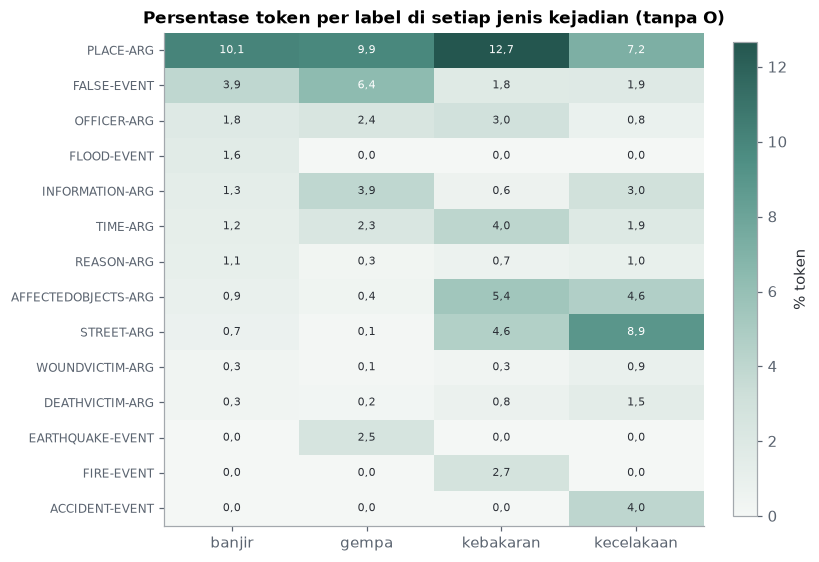

In [29]:
per_ev = pd.crosstab(df_raw["argument"], df_raw["text_id"].str[:3], normalize="columns") * 100
per_ev = per_ev.rename(columns=EVENT_CODES).drop("O").sort_values("banjir", ascending=False)
fig, ax = plt.subplots(figsize=(7.5, 5.2))
im = ax.imshow(per_ev.values, cmap=SEQ_CMAP, aspect="auto")
ax.set_xticks(range(per_ev.shape[1]))
ax.set_xticklabels(per_ev.columns)
ax.set_yticks(range(per_ev.shape[0]))
ax.set_yticklabels(per_ev.index, fontsize=8)
ax.grid(False)
for i in range(per_ev.shape[0]):
    for j in range(per_ev.shape[1]):
        v = per_ev.values[i, j]
        ax.text(j, i, f"{v:.1f}".replace(".", ","), ha="center", va="center", fontsize=7.5, color="white" if v > 6 else C_INK)
ax.set_title("Persentase token per label di setiap jenis kejadian (tanpa O)")
plt.colorbar(im, fraction=0.04, label="% token")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "figures", "label_per_kejadian.png"), dpi=150)
plt.show()

<p style="text-align: justify;">
Komposisi label berbeda antarkejadian: STREET-ARG menonjol pada kecelakaan, AFFECTEDOBJECTS-ARG pada kebakaran, dan FALSE-EVENT pada gempa serta banjir. Skor gabungan perlu dilengkapi evaluasi per kejadian.
</p>


kejadian,banjir,gempa,kebakaran,kecelakaan,TOTAL
label kejadian dalam tweet,,,,,
hanya FALSE-EVENT,875,657,460,276,2268
hanya label kejadian nyata,367,240,644,582,1833
keduanya,2,2,9,0,13
tanpa label kejadian,6,7,15,8,36
TOTAL,1250,906,1128,866,4150


Tweet yang hanya memuat satu jenis label kejadian (kejadian nyata saja atau FALSE-EVENT saja): 98,8%


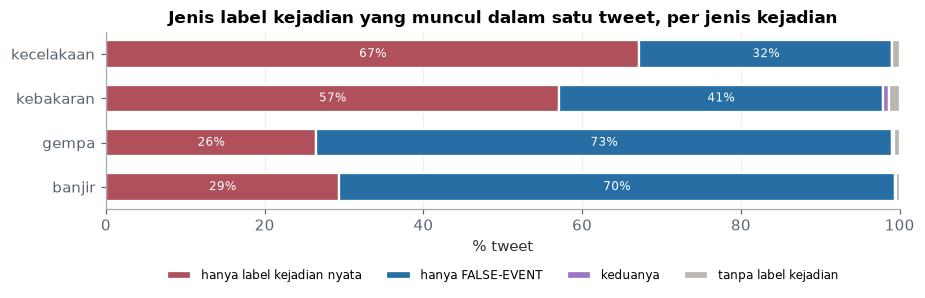

In [30]:
status = pd.Series([tweet_status(t["labels"]) for t in tweets], name="label kejadian dalam tweet")
evs = pd.Series([EVENT_CODES[t["event"]] for t in tweets], name="kejadian")
tab = pd.crosstab(status, evs)
display(pd.crosstab(status.map(STATUS_NAMES), evs, margins=True, margins_name="TOTAL"))
print(f"Tweet yang hanya memuat satu jenis label kejadian (kejadian nyata saja atau FALSE-EVENT saja): "
      f"{fpct(status.isin(['nyata', 'tidak nyata']).mean())}")

order = ["nyata", "tidak nyata", "campuran", "tanpa kejadian"]
share = tab.reindex(order).fillna(0) / tab.sum() * 100
fig, ax = plt.subplots(figsize=(8.5, 3.0))
left = np.zeros(share.shape[1])
for s in order:
    ax.barh(share.columns, share.loc[s].values, left=left, color=STATUS_COLORS[s], label=STATUS_NAMES[s],
            edgecolor="white", linewidth=1.5, height=0.62)
    for y, (l, v) in enumerate(zip(left, share.loc[s].values)):
        if v >= 6:
            ax.text(l + v / 2, y, f"{v:.0f}%", ha="center", va="center", color=ink_on(STATUS_COLORS[s]), fontsize=8)
    left += share.loc[s].values
ax.set_xlim(0, 100)
ax.set_xlabel("% tweet")
ax.set_title("Jenis label kejadian yang muncul dalam satu tweet, per jenis kejadian")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.28), fontsize=8)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "figures", "status_tweet.png"), dpi=150)
plt.show()

<p style="text-align: justify;">
Sebanyak 2.268 tweet hanya memuat FALSE-EVENT dan 1.833 hanya memuat kejadian nyata (98,8% keseluruhan). Ada 13 tweet campuran dan 36 tanpa label kejadian, sehingga klasifikasi tingkat tweet memerlukan penanganan khusus untuk keduanya.
</p>


,jumlah span,rata-rata token per span,span terpanjang
FIRE-EVENT,803,1.04,4
ACCIDENT-EVENT,618,1.11,3
FLOOD-EVENT,412,1.14,2
FALSE-EVENT,2588,1.33,4
OFFICER-ARG,1303,1.62,9
PLACE-ARG,5537,1.85,13
EARTHQUAKE-EVENT,306,1.89,3
TIME-ARG,1246,1.95,10
AFFECTEDOBJECTS-ARG,1385,2.01,13
DEATHVICTIM-ARG,232,2.72,12


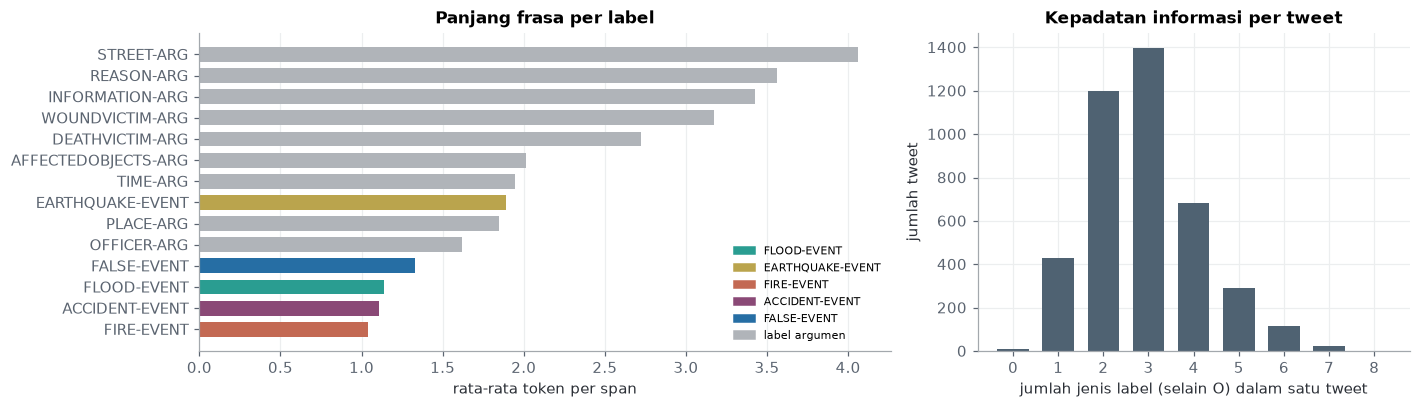

Rata-rata jenis label per tweet: 2.91 | median: 3


In [31]:
span_len = collections.defaultdict(list)
n_types = []
for t in tweets:
    sp = spans(t["labels"])
    for a, b, lab in sp:
        span_len[lab].append(b - a)
    n_types.append(len({lab for _, _, lab in sp}))
sl = pd.DataFrame({"jumlah span": {k: len(v) for k, v in span_len.items()},
                   "rata-rata token per span": {k: np.mean(v) for k, v in span_len.items()},
                   "span terpanjang": {k: max(v) for k, v in span_len.items()}}).sort_values("rata-rata token per span")
display(sl.round(2))

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1.6, 1]})
ax[0].barh(sl.index, sl["rata-rata token per span"], color=[label_color(l) for l in sl.index], height=0.7)
ax[0].set_xlabel("rata-rata token per span")
ax[0].set_title("Panjang frasa per label")
ax[0].grid(axis="y", visible=False)
ax[0].legend(handles=[Patch(color=label_color(l), label=l) for l in EV_LABEL_ORDER + ["FALSE-EVENT"]]
             + [Patch(color=C_ARG, label="label argumen")], loc="lower right", fontsize=7)
vc = pd.Series(n_types).value_counts().sort_index()
ax[1].bar(vc.index.astype(str), vc.values, color=C_SLATE, width=0.7)
ax[1].set_xlabel("jumlah jenis label (selain O) dalam satu tweet")
ax[1].set_ylabel("jumlah tweet")
ax[1].set_title("Kepadatan informasi per tweet")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "figures", "struktur_span.png"), dpi=150)
plt.show()
print(f"Rata-rata jenis label per tweet: {np.mean(n_types):.2f} | median: {np.median(n_types):.0f}")

<p style="text-align: justify;">
Span kejadian umumnya sekitar satu token, sedangkan argumen seperti STREET-ARG rata-rata 4,06 token. Kesalahan batas pada argumen panjang dapat menurunkan F1 span meskipun sebagian token sudah benar.
</p>


,kejadian,n tweet,rata2 token,min,max,TTR,paper: rata2,paper: min,paper: max,paper: TTR
0,banjir,1000,23.080,4,56,0.249,23.69,4,56,0.248
1,gempa,656,24.732,4,51,0.227,25.52,4,51,0.222
2,kebakaran,878,26.822,4,126,0.215,26.83,5,126,0.215
3,kecelakaan,616,19.706,4,54,0.262,19.99,4,54,0.266


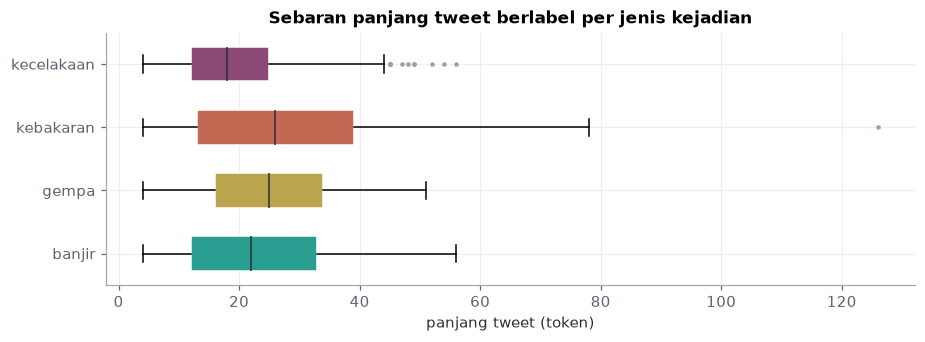

In [32]:
paper_t2 = {"BAN": (1000, 23.69, 4, 56, 0.248), "GEM": (656, 25.52, 4, 51, 0.222),
            "KEB": (878, 26.83, 5, 126, 0.215), "KEC": (616, 19.99, 4, 54, 0.266)}
rows = []
for ev in sorted(EVENT_CODES):
    ts = [t for t in train_labeled if t["event"] == ev]
    lens = [len(t["tokens"]) for t in ts]
    words = [w for t in ts for w in t["tokens"]]
    p = paper_t2[ev]
    rows.append({"kejadian": EVENT_CODES[ev], "n tweet": len(ts), "rata2 token": np.mean(lens), "min": min(lens),
                 "max": max(lens), "TTR": len(set(words)) / len(words), "paper: rata2": p[1], "paper: min": p[2],
                 "paper: max": p[3], "paper: TTR": p[4]})
display(pd.DataFrame(rows).round(3))

fig, ax = plt.subplots(figsize=(8.5, 3.2))
data = [[len(t["tokens"]) for t in tweets if t["event"] == ev] for ev in sorted(EVENT_CODES)]
arah = {"orientation": "horizontal"} if tuple(int(v) for v in mpl.__version__.split(".")[:2]) >= (3, 10) else {"vert": False}
bp = ax.boxplot(data, **arah, patch_artist=True, widths=0.55, showfliers=True,
                flierprops={"marker": "o", "markersize": 3, "markerfacecolor": "#9aa3ad", "markeredgecolor": "none"},
                medianprops={"color": C_INK})
for patch, ev in zip(bp["boxes"], sorted(EVENT_CODES)):
    patch.set_facecolor(EVENT_SERIES[EVENT_CODES[ev]])
    patch.set_edgecolor("white")
ax.set_yticks(range(1, 5))
ax.set_yticklabels([EVENT_CODES[e] for e in sorted(EVENT_CODES)])
ax.set_xlabel("panjang tweet (token)")
ax.set_title("Sebaran panjang tweet berlabel per jenis kejadian")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "figures", "panjang_tweet.png"), dpi=150)
plt.show()

<p style="text-align: justify;">
Rata-rata panjang tweet latih 19,7–26,8 token, dengan maksimum 126 token. Statistiknya mendekati paper, tetapi batas 256 subtoken tetap perlu diperiksa setelah tokenisasi.
</p>


<p style="text-align: justify;">
Dominasi O dan variasi panjang argumen memerlukan evaluasi non-O serta span. Proporsi O pada data adalah sekitar 69%, berbeda dari klaim lebih dari 90% dalam uraian BiLSTM paper.
</p>


### 5.3 Missing Value, Outlier, dan Kualitas Data

<p style="text-align: justify;">
Pemeriksaan kualitas mencakup token kosong, duplikat, hubungan label NER–SRL, dan anotasi kata kejadian. Dugaan kesalahan label ditinjau berdasarkan konteks.
</p>


In [33]:
print("Token kosong:")
display(df_raw[empty_tok][["text_id", "id", "token", "argument"]])


def norm_text(s):
    return re.sub(r"[\W_]+", "", str(s).lower())


keys = [norm_text(" ".join(t["tokens"])) for t in tweets]
dup_groups = [ids for ids in pd.Series(range(len(tweets))).groupby(keys).apply(list) if len(ids) > 1]
print(f"Kelompok tweet berlabel dengan teks identik: {len(dup_groups)}")

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.preprocessing import normalize
texts = [" ".join(t["tokens"]) for t in tweets]
vec_l = CountVectorizer(token_pattern=r"\S+").fit(texts)
X = normalize(vec_l.transform(texts))
S = (X @ X.T).tocoo()
near = [(i, j, v) for i, j, v in zip(S.row, S.col, S.data) if i < j and v >= 0.8]
print(f"Pasangan tweet berlabel dengan cosine similarity >= 0,8: {len(near)}")
i, j, v = max(near, key=lambda x: x[2] if x[2] < 0.999 else 0)
print(f"Contoh pasangan mirip (cosine {v:.2f}):\n  {tweets[i]['text_id']}: {texts[i][:150]}\n  {tweets[j]['text_id']}: {texts[j][:150]}")

Token kosong:


,text_id,id,token,argument
19876,BAN-01841,BAN-01841.044,,O
32070,GEM-01339,GEM-01339.018,,O
46747,KEB-00243,KEB-00243.003,,PLACE-ARG
47364,KEB-00266,KEB-00266.013,,PLACE-ARG


Kelompok tweet berlabel dengan teks identik: 0
Pasangan tweet berlabel dengan cosine similarity >= 0,8: 229
Contoh pasangan mirip (cosine 0.96):
  BAN-00062: apa ceritamu kala itu ? -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- - kilas balik banjir besar di kudus tahun 2014
  BAN-01891: banjir di konawe sultra membuat biawak2 cina ini keluar dari persembunyian eanaknya di apai ya -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -- -


<p style="text-align: justify;">
Empat token kosong dihapus. Tidak ditemukan duplikat persis setelah normalisasi, tetapi ada 229 pasangan dengan cosine ≥ 0,8. Kemiripan tinggi belum tentu berarti kejadian yang sama.
</p>


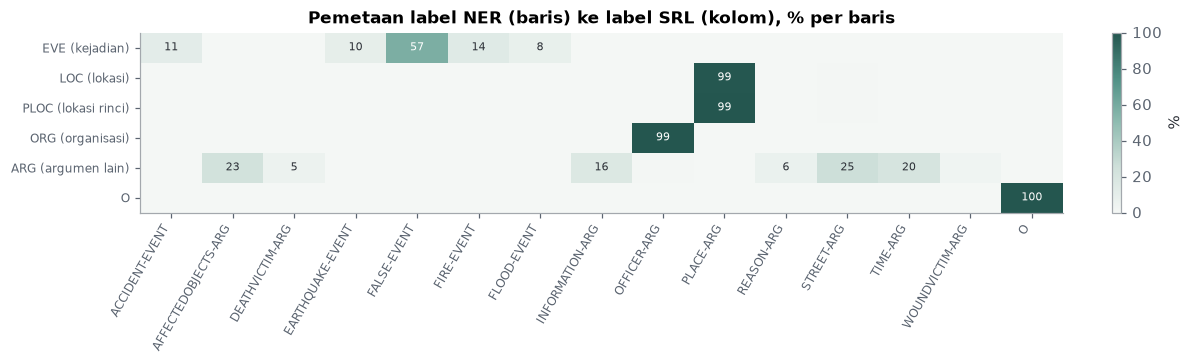

In [34]:
ent = df_raw["entity"].str.replace(r"^[BI]-", "", regex=True)
ct = pd.crosstab(ent, df_raw["argument"], normalize="index") * 100
ct = ct.loc[["EVE", "LOC", "PLOC", "ORG", "ARG", "O"], [c for c in ct.columns if c != "O"] + ["O"]]
fig, ax = plt.subplots(figsize=(11, 3.4))
im = ax.imshow(ct.values, cmap=SEQ_CMAP, aspect="auto", vmin=0, vmax=100)
ax.set_xticks(range(ct.shape[1]))
ax.set_xticklabels(ct.columns, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(ct.shape[0]))
ax.set_yticklabels(["EVE (kejadian)", "LOC (lokasi)", "PLOC (lokasi rinci)", "ORG (organisasi)", "ARG (argumen lain)", "O"], fontsize=8)
ax.grid(False)
for a in range(ct.shape[0]):
    for b in range(ct.shape[1]):
        val = ct.values[a, b]
        if val >= 5:
            ax.text(b, a, f"{val:.0f}", ha="center", va="center", fontsize=7, color="white" if val > 55 else C_INK)
ax.set_title("Pemetaan label NER (baris) ke label SRL (kolom), % per baris")
plt.colorbar(im, fraction=0.025, label="%")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "figures", "ner_vs_srl.png"), dpi=150)
plt.show()

<p style="text-align: justify;">
Sebagian kategori NER berpadanan langsung dengan label SRL, tetapi EVE terbagi menjadi kejadian nyata dan FALSE-EVENT. Skema SRL menambahkan status kejadian dan rincian peran argumen.
</p>


argument,ACCIDENT-EVENT,DEATHVICTIM-ARG,EARTHQUAKE-EVENT,FALSE-EVENT,FIRE-EVENT,FLOOD-EVENT,INFORMATION-ARG,O,OFFICER-ARG,PLACE-ARG,REASON-ARG,WOUNDVICTIM-ARG
token,,,,,,,,,,,,
banjir,0,0,0,1005,0,411,3,37,0,2,0,0
gempa,0,0,296,728,0,0,10,95,1,2,0,0
kebakaran,0,0,0,497,702,0,0,41,47,0,0,1
terbakar,0,0,0,6,74,0,0,0,0,0,1,0
kecelakaan,598,1,0,289,0,0,0,18,0,0,0,0


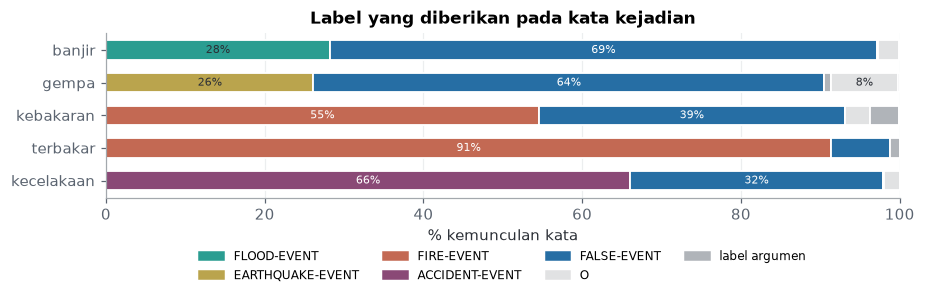

Tweet tanpa label kejadian: 36
   BAN-01299 | rumah/AFFECTEDOBJECTS-ARG terbawa arus banjir di gowa/PLACE-ARG
   BAN-01428 | kopo/INFORMATION-ARG depan/INFORMATION-ARG rskia/INFORMATION-ARG macet/INFORMATION-ARG akibat banjir di citarip/PLACE-ARG
   BAN-01807 | [ garage sale ] halo sahabat tahukah kamu kondisi lingkungan hidup di jakarta/PLACE-ARG ? mulai dari banjir/PLACE-ARG polusi udara penurunan muka tanah sungai bahkan telu
   BAN-01832 | korban kebakaran banjir/PLACE-ARG di jakarta/PLACE-ARG enggak pernah gubernurnya datang
   GEM-00080 | gempa bumi sedang trending di google baca berita terkini di sini :
   GEM-01193 | bacaan yasin dan tahlil di masjid as-salam kedutaan besar malaysia bersama2 pelajar dari untuk saudara2 kita yang telah menjadi mangsa gempa bumi dan tsunami di semoga ro


In [35]:
EVENT_WORDS = ["banjir", "gempa", "kebakaran", "terbakar", "kecelakaan"]
ew = df_raw[df_raw["token"].str.lower().isin(EVENT_WORDS)]
xt = pd.crosstab(ew["token"].str.lower(), ew["argument"]).reindex(EVENT_WORDS)
display(xt)

cols = [c for c in ["FLOOD-EVENT", "FIRE-EVENT", "EARTHQUAKE-EVENT", "ACCIDENT-EVENT", "FALSE-EVENT"] if c in xt] + \
       [c for c in xt.columns if c not in REAL_EVENTS and c != "FALSE-EVENT"]
pct = xt[cols].div(xt.sum(axis=1), axis=0) * 100
fig, ax = plt.subplots(figsize=(8.5, 3.0))
left = np.zeros(len(pct))
for c in cols:
    color = label_color(c)
    ax.barh(pct.index, pct[c].values, left=left, color=color, edgecolor="white", linewidth=1.2, height=0.6)
    for y, (l, v) in enumerate(zip(left, pct[c].values)):
        if v >= 8:
            ax.text(l + v / 2, y, f"{v:.0f}%", ha="center", va="center", fontsize=7.5, color=ink_on(color))
    left += pct[c].values
ax.set_xlim(0, 100)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("% kemunculan kata")
ax.set_title("Label yang diberikan pada kata kejadian")
present = [c for c in EV_LABEL_ORDER + ["FALSE-EVENT"] if c in cols]
ax.legend(handles=[Patch(color=label_color(c), label=c) for c in present]
          + [Patch(color=C_O, label="O"), Patch(color=C_ARG, label="label argumen")],
          ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.25), fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "figures", "label_kata_kejadian.png"), dpi=150)
plt.show()

no_event = [t for t in tweets if tweet_status(t["labels"]) == "tanpa kejadian"]
print(f"Tweet tanpa label kejadian: {len(no_event)}")
for t in no_event[:6]:
    print("  ", t["text_id"], "|", " ".join(f"{w}/{l}" if l != "O" else w for w, l in zip(t["tokens"], t["labels"]))[:170])

<p style="text-align: justify;">
“Banjir” dan “gempa” lebih sering berlabel FALSE-EVENT daripada kejadian nyata. “Kebakaran” juga dapat menjadi OFFICER-ARG dalam “pemadam kebakaran”. Identitas kata saja tidak cukup; label meragukan perlu ditinjau dalam konteks.
</p>


<p style="text-align: justify;">
Empat token kosong dikeluarkan; anotasi lainnya dipertahankan. Tweet mirip dan label meragukan dicatat untuk analisis lanjutan.
</p>


### 5.4 Analisis Hubungan Fitur

<p style="text-align: justify;">
Analisis kata dan konteks digunakan untuk memahami ambiguitas FALSE-EVENT. Hubungan frekuensi bersifat eksploratif dan belum membuktikan pengaruh fitur pada model.
</p>


In [36]:
top = {}
for lab in [l for l in LABELS if l != "O"]:
    words = collections.Counter(w.lower() for t in tweets for w, l in zip(t["tokens"], t["labels"]) if l == lab)
    top[lab] = ", ".join(w for w, _ in words.most_common(8))
display(pd.DataFrame.from_dict(top, orient="index", columns=["kata paling sering"]))

,kata paling sering
ACCIDENT-EVENT,"kecelakaan, tunggal, maut, lalu, lintas, beruntun, menabrak, tabrakan"
AFFECTEDOBJECTS-ARG,"rumah, mobil, truk, lahan, hutan, bus, kendaraan, motor"
DEATHVICTIM-ARG,"orang, tewas, korban, meninggal, jiwa, satu, ada, 1"
EARTHQUAKE-EVENT,"gempa, bumi, guncang, mengguncang, tektonik, susulan, guncangan, diguncang"
FALSE-EVENT,"banjir, gempa, bumi, kebakaran, kecelakaan, bandang, karhutla, rob"
FIRE-EVENT,"kebakaran, terbakar, merah, karhutla, si, jago, dilalap, sijago"
FLOOD-EVENT,"banjir, bandang, rob, besar, lahar, lumpur, kilat, banjir/genangan"
INFORMATION-ARG,"sr, 5, 4, skala, penanganan, magnitudo, richter, 3"
OFFICER-ARG,"damkar, petugas, unit, bmkg, pemadam, polri, bpbd, pmi"
PLACE-ARG,"jakarta, kabupaten, desa, kecamatan, barat, indonesia, ., kota"


<p style="text-align: justify;">
Label argumen memiliki petunjuk seperti “wib” untuk waktu dan “damkar” untuk petugas. Namun kata bencana juga dominan pada FALSE-EVENT, sehingga status kejadian membutuhkan konteks.
</p>


,kelompok isyarat,% tweet berlabel FALSE-EVENT,% tweet berlabel kejadian nyata,rasio,tweet berlabel kejadian nyata yang mengandung
0,peringatan/antisipasi,7.41,3.36,2.21,62
1,negasi,18.43,10.13,1.82,187
2,bantuan/pasca-kejadian,15.17,3.47,4.37,64
3,penanda Malaysia,3.44,1.08,3.17,20
4,pernyataan umum/tips,3.84,3.63,1.06,67


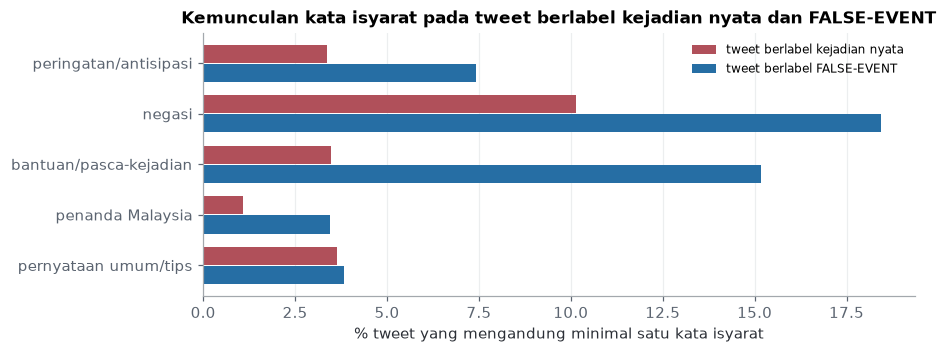

In [37]:
CUES = {
    "peringatan/antisipasi": ["waspada", "siaga", "antisipasi", "mengantisipasi", "potensi", "berpotensi", "hati-hati",
                              "peringatan", "rawan", "cegah", "mencegah", "pencegahan", "imbau", "imbauan", "mitigasi",
                              "simulasi", "prediksi", "ancaman", "mengancam"],
    "negasi": ["tidak", "tak", "tiada", "bukan", "belum", "tanpa", "nggak", "gak", "enggak", "ga"],
    "bantuan/pasca-kejadian": ["bantuan", "donasi", "salurkan", "menyalurkan", "posko", "surut", "pasca", "pemulihan", "relawan"],
    "penanda Malaysia": ["mangsa", "kerana", "sahaja", "petang", "pejabat", "kilat", "rm", "malaysia", "johor", "kelantan",
                         "terengganu", "pahang", "sabah", "sarawak", "selangor", "kedah", "melaka", "ayuh"],
    "pernyataan umum/tips": ["penyebab", "menyebabkan", "tips", "cara", "edukasi", "faktor", "berikut"],
}
st_all = [tweet_status(t["labels"]) for t in tweets]
idx_false = [i for i, s in enumerate(st_all) if s == "tidak nyata"]
idx_real = [i for i, s in enumerate(st_all) if s in ("nyata", "campuran")]
tokset = [set(w.lower() for w in t["tokens"]) for t in tweets]
rows = []
for name, words in CUES.items():
    ws = set(words)
    f = np.mean([bool(tokset[i] & ws) for i in idx_false]) * 100
    r = np.mean([bool(tokset[i] & ws) for i in idx_real]) * 100
    rows.append({"kelompok isyarat": name, "% tweet berlabel FALSE-EVENT": f, "% tweet berlabel kejadian nyata": r,
                 "rasio": f / r if r else np.inf,
                 "tweet berlabel kejadian nyata yang mengandung": sum(bool(tokset[i] & ws) for i in idx_real)})
cue_tbl = pd.DataFrame(rows)
display(cue_tbl.round(2))

fig, ax = plt.subplots(figsize=(8.5, 3.3))
y = np.arange(len(cue_tbl))
ax.barh(y - 0.19, cue_tbl["% tweet berlabel kejadian nyata"], height=0.36, color=C_REAL, label="tweet berlabel kejadian nyata")
ax.barh(y + 0.19, cue_tbl["% tweet berlabel FALSE-EVENT"], height=0.36, color=C_FALSE, label="tweet berlabel FALSE-EVENT")
ax.set_yticks(y)
ax.set_yticklabels(cue_tbl["kelompok isyarat"])
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("% tweet yang mengandung minimal satu kata isyarat")
ax.set_title("Kemunculan kata isyarat pada tweet berlabel kejadian nyata dan FALSE-EVENT")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "figures", "kata_isyarat.png"), dpi=150)
plt.show()

<p style="text-align: justify;">
Isyarat bantuan, peringatan, dan negasi lebih sering muncul pada FALSE-EVENT, tetapi juga ditemukan pada kejadian nyata. Contohnya, “tidak ada korban jiwa” tidak menyangkal terjadinya bencana.
</p>


In [38]:
def false_type(i):
    for name in ["penanda Malaysia", "peringatan/antisipasi", "bantuan/pasca-kejadian", "pernyataan umum/tips", "negasi"]:
        if tokset[i] & set(CUES[name]):
            return name
    return "belum terkategori"


ft = pd.Series([false_type(i) for i in idx_false]).value_counts()
display(ft.rename("jumlah tweet berlabel FALSE-EVENT").to_frame())
for name in ft.index:
    i = idx_false[[false_type(k) for k in idx_false].index(name)]
    print(f"[{name}] {tweets[i]['text_id']}: " + " ".join(tweets[i]["tokens"])[:160])

,jumlah tweet berlabel FALSE-EVENT
belum terkategori,1281
negasi,352
bantuan/pasca-kejadian,325
peringatan/antisipasi,163
penanda Malaysia,78
pernyataan umum/tips,69


[belum terkategori] BAN-00002: ingin tenangkan diri di musim banjir ? -memancing -sukat air -bakar ikan -berehat di atas rumah rakit khas musim cuti rm20 seorang ( termasukhomestay ) p/s ikan
[negasi] BAN-00006: `` : video kenangan gub dki jaman old menegaskan masalah banjir bukan masalah jakarta itu kewenangan pemerintah pusat dia menegaskan jika terpilih sebagai presi
[bantuan/pasca-kejadian] BAN-00032: bantuan sumbangan banjir diserahkan kepada staf ump yang terlibat di dalam banjir di pekan
[peringatan/antisipasi] BAN-00022: dampak fenomena supermoon adalah adanya peningkatan pasang air laut maksimum yang dapat mengakibatkan terjadinya banjir rob ( genangan air laut di daratan ) mak
[penanda Malaysia] BAN-00004: ayuh kita bersama menjayakan misi bantuan mangsa banjir di mersing pada 3 jangan ( 9 pagi - 1 petang ) di ibu pejabat saj ranhill larkin
[pernyataan umum/tips] BAN-00001: 13 janji akan mencari solusi banjir jakarta dan kemacetan jakarta ketika jadi presiden bahkan statemen 

<p style="text-align: justify;">
Aturan kata kunci hanya mencakup 43,5% tweet FALSE-EVENT; 1.281 dari 2.268 tweet belum terkategori. Hasil bergantung pada urutan aturan dan mendukung penggunaan model kontekstual.
</p>


Span kejadian pada data latih: 1619 kejadian nyata, 1958 FALSE-EVENT; kata konteks unik dengan frekuensi ≥ 10: 285


,kata konteks,di sekitar FALSE-EVENT,di sekitar kejadian nyata,log-odds
0,padat,1,41,-3.27
1,gudang,0,16,-3.06
2,hanguskan,0,15,-3.00
3,wita,0,14,-2.93
4,hebat,1,28,-2.90
5,toko,0,13,-2.86
6,tangerang,0,12,-2.79
7,tunggal,0,12,-2.79
8,melibatkan,0,12,-2.79
9,sepeda,0,11,-2.71


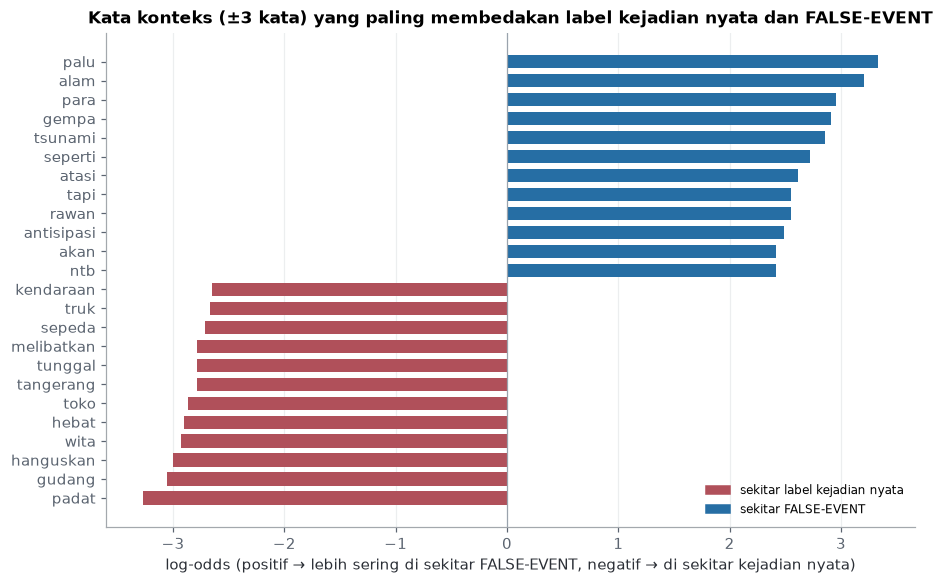

In [39]:
WIN = 3
ctx = {"nyata": collections.Counter(), "FALSE-EVENT": collections.Counter()}
n_span = collections.Counter()
for t in train_labeled:
    toks = [w.lower() for w in t["tokens"]]
    for a, b, lab in spans(t["labels"]):
        if lab in REAL_EVENTS or lab == "FALSE-EVENT":
            kelas = "FALSE-EVENT" if lab == "FALSE-EVENT" else "nyata"
            n_span[kelas] += 1
            ctx[kelas].update(toks[max(0, a - WIN):a] + toks[b:b + WIN])
vocab_ctx = set(ctx["nyata"]) | set(ctx["FALSE-EVENT"])
N_f, N_r, V = sum(ctx["FALSE-EVENT"].values()), sum(ctx["nyata"].values()), len(vocab_ctx)
rows = []
for w in vocab_ctx:
    cf, cr = ctx["FALSE-EVENT"][w], ctx["nyata"][w]
    if cf + cr >= 10:
        lor = np.log((cf + 1) / (N_f + V)) - np.log((cr + 1) / (N_r + V))
        rows.append({"kata konteks": w, "di sekitar FALSE-EVENT": cf, "di sekitar kejadian nyata": cr, "log-odds": lor})
CTX_LOR = pd.DataFrame(rows).sort_values("log-odds").reset_index(drop=True)
print(f"Span kejadian pada data latih: {n_span['nyata']} kejadian nyata, {n_span['FALSE-EVENT']} FALSE-EVENT; "
      f"kata konteks unik dengan frekuensi ≥ 10: {len(CTX_LOR)}")
display(pd.concat([CTX_LOR.head(10), CTX_LOR.tail(10)]).round(2))

sel = pd.concat([CTX_LOR.head(12), CTX_LOR.tail(12)])
fig, ax = plt.subplots(figsize=(8.5, 5.4))
ax.barh(sel["kata konteks"], sel["log-odds"], color=[C_FALSE if v > 0 else C_REAL for v in sel["log-odds"]], height=0.7)
ax.axvline(0, color="#9aa3ad", lw=0.8)
ax.grid(axis="y", visible=False)
ax.set_xlabel("log-odds (positif → lebih sering di sekitar FALSE-EVENT, negatif → di sekitar kejadian nyata)")
ax.set_title("Kata konteks (±3 kata) yang paling membedakan label kejadian nyata dan FALSE-EVENT")
ax.legend(handles=[Patch(color=C_REAL, label="sekitar label kejadian nyata"), Patch(color=C_FALSE, label="sekitar FALSE-EVENT")],
          loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "figures", "kata_konteks_kejadian.png"), dpi=150)
plt.show()

<p style="text-align: justify;">
Analisis jendela ±3 kata menemukan asosiasi konteks dengan status kejadian, termasuk nama lokasi dan topik tertentu. Asosiasi ini belum membuktikan pengaruh pada model dan perlu diuji melalui ablasi.
</p>


<p style="text-align: justify;">
Kejadian nyata dan FALSE-EVENT menggunakan kata bencana yang sama. Model perlu memahami konteks serta diuji pada contoh yang berbeda dari pola mayoritas.
</p>


### 5.5 Distribusi Data Latih dan Uji

<p style="text-align: justify;">
Distribusi label, status kejadian, dan kemiripan latih–uji diperiksa untuk menilai keseimbangan serta potensi tumpang tindih. Validasi neural dibentuk saat pelatihan.
</p>


,% latih (reproduksi),% latih (paper),% uji (reproduksi),% uji (paper)
O,69.38,69.74,69.07,67.85
PLACE-ARG,10.41,10.31,9.99,10.32
FALSE-EVENT,3.45,3.50,3.56,3.40
STREET-ARG,3.09,2.89,3.45,4.14
AFFECTEDOBJECTS-ARG,2.89,2.78,2.58,2.92
TIME-ARG,2.43,2.39,2.47,2.61
OFFICER-ARG,2.18,2.19,1.97,1.94
INFORMATION-ARG,1.86,2.05,2.40,1.82
FIRE-EVENT,0.88,0.85,0.73,0.83
REASON-ARG,0.73,0.78,0.87,0.71


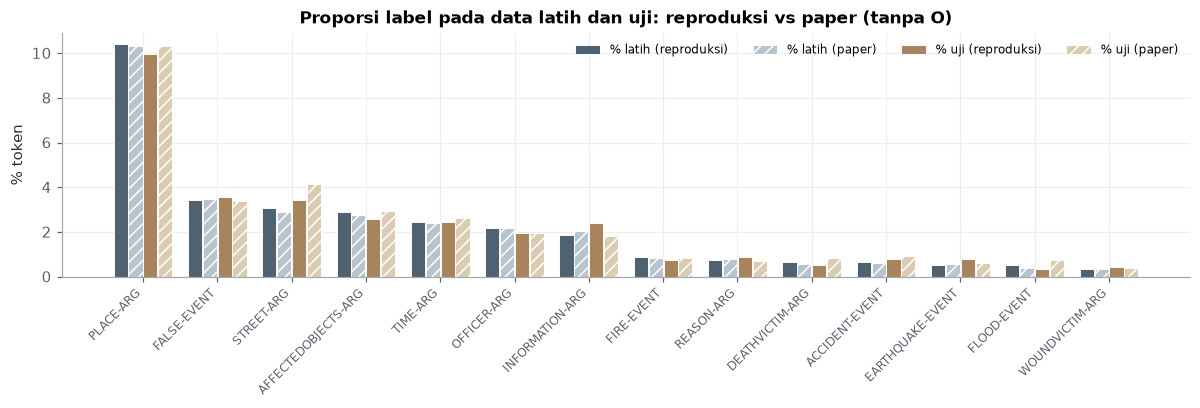

,% tweet latih,% tweet uji
label kejadian dalam tweet,,
hanya FALSE-EVENT,54.73,54.4
hanya label kejadian nyata,44.16,44.2
tanpa label kejadian,0.79,1.1
keduanya,0.32,0.3


Tweet uji dengan kemiripan >= 0,8 terhadap tweet latih : 36 dari 1000
Tweet uji dengan kemiripan >= 0,95 terhadap tweet latih: 1 dari 1000


In [40]:
def label_share(items):
    c = collections.Counter(l for t in items for l in t["labels"])
    n = sum(c.values())
    return {l: 100 * c[l] / n for l in LABELS}


paper_test = {lab: sum(v[1]) for lab, v in TABLE5.items()}
paper_train = {lab: sum(v[0]) for lab, v in TABLE5.items()}
n_pt, n_ptr = sum(paper_test.values()), sum(paper_train.values())
dist = pd.DataFrame({
    "% latih (reproduksi)": label_share(train_labeled),
    "% latih (paper)": {l: 100 * paper_train[l] / n_ptr for l in LABELS},
    "% uji (reproduksi)": label_share(test),
    "% uji (paper)": {l: 100 * paper_test[l] / n_pt for l in LABELS},
}).round(2).sort_values("% latih (reproduksi)", ascending=False)
display(dist)

d2 = dist.drop("O")
fig, ax = plt.subplots(figsize=(11, 3.8))
x = np.arange(len(d2))
for k, (col, c) in enumerate(zip(d2.columns, [C_SLATE, C_SLATE_L, C_SAND, C_SAND_L])):
    ax.bar(x + (k - 1.5) * 0.2, d2[col].values, width=0.19, color=c, label=col, hatch="///" if "paper" in col else None,
           edgecolor="white", linewidth=0.6)
ax.set_xticks(x)
ax.set_xticklabels(d2.index, rotation=45, ha="right", fontsize=8)
ax.set_ylabel("% token")
ax.set_title("Proporsi label pada data latih dan uji: reproduksi vs paper (tanpa O)")
ax.legend(ncol=4, fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "figures", "distribusi_split.png"), dpi=150)
plt.show()

stat_tbl = pd.DataFrame({
    "% tweet latih": pd.Series([STATUS_NAMES[tweet_status(t["labels"])] for t in train_labeled]).value_counts(normalize=True) * 100,
    "% tweet uji": pd.Series([STATUS_NAMES[tweet_status(t["labels"])] for t in test]).value_counts(normalize=True) * 100}).round(2)
stat_tbl.index.name = "label kejadian dalam tweet"
display(stat_tbl)

A = normalize(vec_l.transform([" ".join(t["tokens"]) for t in test]))
B = normalize(vec_l.transform([" ".join(t["tokens"]) for t in train_labeled]))
max_sim = (A @ B.T).max(axis=1).toarray().ravel()
print(f"Tweet uji dengan kemiripan >= 0,8 terhadap tweet latih : {(max_sim >= 0.8).sum()} dari {len(test)}")
print(f"Tweet uji dengan kemiripan >= 0,95 terhadap tweet latih: {(max_sim >= 0.95).sum()} dari {len(test)}")

<p style="text-align: justify;">
Proporsi O pada latih dan uji hampir sama (69,38% dan 69,07%), tetapi label langka berbeda dari paper. Sebanyak 36 tweet uji memiliki cosine ≥ 0,8 terhadap data latih; temuan ini menjadi keterbatasan pembagian acak.
</p>


<p style="text-align: justify;">
Distribusi agregat latih–uji serupa, tetapi perbedaan label langka dan kemiripan teks perlu diperhatikan saat membandingkan skor dengan paper.
</p>


### 5.6 EDA Pendukung Novelty

<p style="text-align: justify;">
EDA pada 5.2–5.5 memberi bukti awal untuk dua novelty Checkpoint 2 (16.3). Gambar 5.3 merangkumnya; panel kanan memakai prediksi model dari Bab 11.
</p>

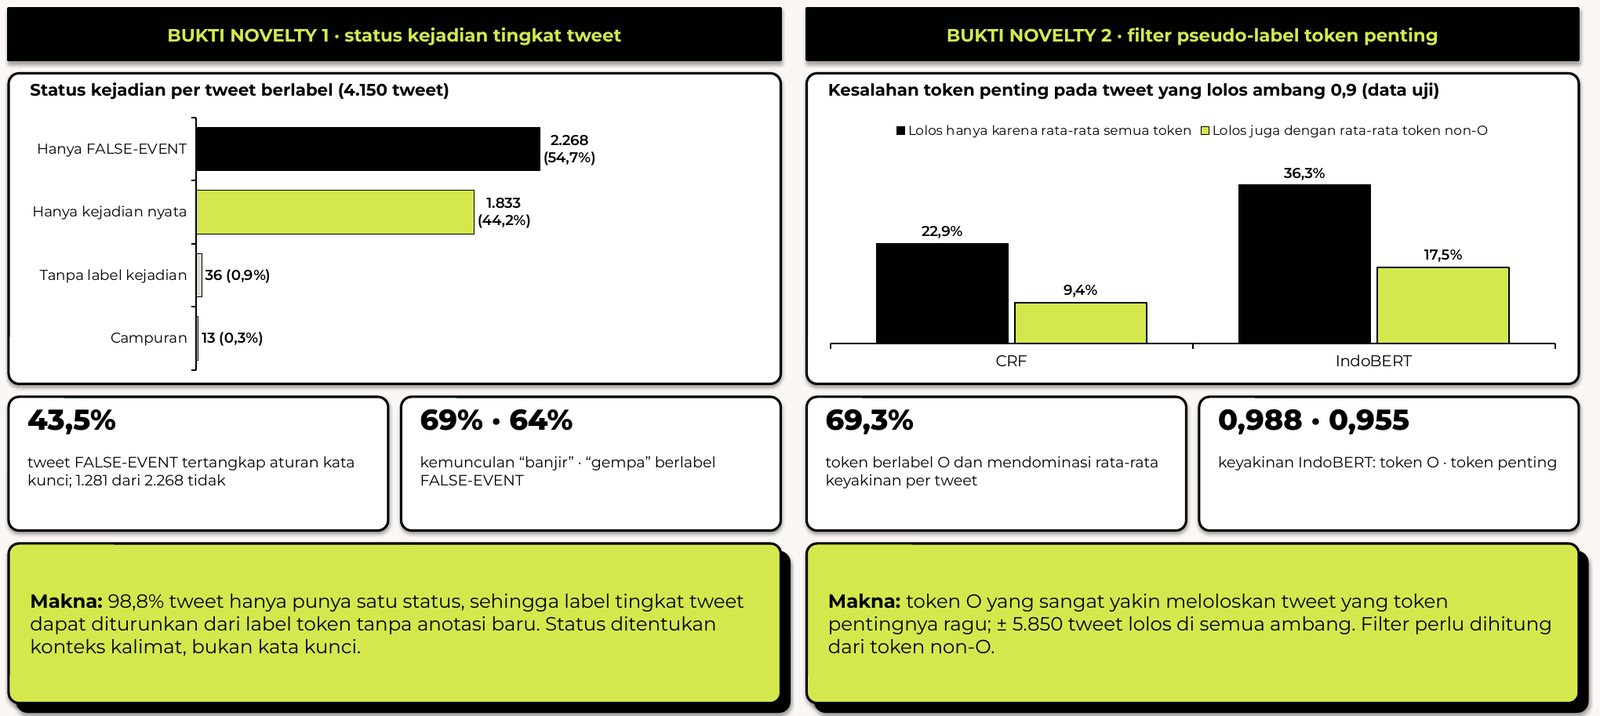

<p style="text-align: center;"><i>Gambar 5.3. Bukti EDA untuk Novelty 1 (kiri) dan Novelty 2 (kanan).</i></p>

| Bukti | Nilai | Bagian | Mendukung |
|---|---|---|---|
| Tweet dengan satu status kejadian | 98,8% (2.268 hanya FALSE-EVENT, 1.833 hanya kejadian nyata; 13 campuran, 36 tanpa label kejadian) | 5.2 | Novelty 1: label status tingkat tweet dapat diturunkan dari label token tanpa anotasi baru |
| Kata kejadian berlabel FALSE-EVENT | “banjir” 69%, “gempa” 64% | 5.3 | Novelty 1: status ditentukan konteks, bukan kata |
| Cakupan aturan kata kunci | 43,5% tweet FALSE-EVENT; 1.281 dari 2.268 tidak tertangkap | 5.4 | Novelty 1: perlu representasi kalimat, bukan aturan |
| Proporsi token O | 69,3% (latih 69,38%, uji 69,07%) | 5.2, 5.5 | Novelty 2: rata-rata keyakinan per tweet didominasi O |
| Keyakinan IndoBERT: token O vs token penting | 0,988 vs 0,955 | 11 | Novelty 2: token O menaikkan rata-rata keyakinan |
| Kesalahan token penting pada tweet yang lolos θ = 0,9 hanya karena rata-rata semua token | IndoBERT 36,3% vs 17,5%; CRF 22,9% vs 9,4% | 11 | Novelty 2: filter dihitung dari token non-O |


<a id="bab-6"></a>
## 6. Preprocessing dan Feature Engineering

### 6.1 Tahapan Preprocessing

<p style="text-align: justify;">
Teks preprocessing penulis dipakai agar normalisasi tetap konsisten. Pengolahan lokal mencakup token kosong, data tanpa label, serta representasi setiap model.
</p>

| Langkah | Pelaksana | Alasan |
|---|---|---|
| Case folding, penghapusan URL/mention/hashtag, normalisasi kata gaul | Penulis paper (tersedia di folder preprocessed) | Mengurangi variasi penulisan. Kamus normalisasi tidak dirilis, sehingga hasil penulis dipakai apa adanya |
| Tanpa lemmatisasi dan tanpa penghapusan stopword | Penulis paper | Nama tempat (misalnya "Jl Seturan") dan kata seperti "di" penting bagi konteks lokasi |
| Penghapusan duplikat (cosine ≥ 0,8) dan tweet di luar Indonesia | Penulis paper | Mencegah data berulang dan data di luar cakupan |
| Penghapusan 4 token kosong | Laporan ini | Menjaga kesesuaian antara teks masukan dan target label |
| Penyusunan 5.850 tweet tanpa label (6.2) | Laporan ini | Paper hanya menyebutkan jumlahnya |
| Tokenisasi subword dan penyelarasan label (6.3) | Laporan ini, mengikuti pola standar Hugging Face | Transformer memecah kata menjadi subword, sedangkan label diberikan per kata |
| Fitur CRF dan kosakata BiLSTM (6.4) | Laporan ini | CRF dan BiLSTM tidak memakai tokenizer pretrained |
| Balancing dan augmentasi | Tidak dilakukan | Mengikuti paper agar hasil sebanding |

<p style="text-align: justify;">
Empat token kosong dihapus dan anotasi lain dipertahankan. Penyaringan data mentah penulis tidak diulang sepenuhnya.
</p>



### 6.2 Data Tanpa Label untuk Self-training

<p style="text-align: justify;">
Sebanyak 5.850 tweet tanpa label dipilih acak dari data preprocessing setelah duplikat dan teks dengan cosine ≥ 0,8 terhadap tweet berlabel dikeluarkan. Kumpulan ini merupakan rekonstruksi karena daftar asli paper tidak tersedia.
</p>


Tweet berlabel yang ditemukan persis di data preprocessed : 3,210 dari 4,150
Kumpulan tweet tanpa label setelah pencocokan teks        : 52,867
Dikeluarkan karena mirip tweet berlabel (cosine >= 0,8)    : 710
Kumpulan akhir / tweet tanpa label yang digunakan          : 52,157 / 5,850


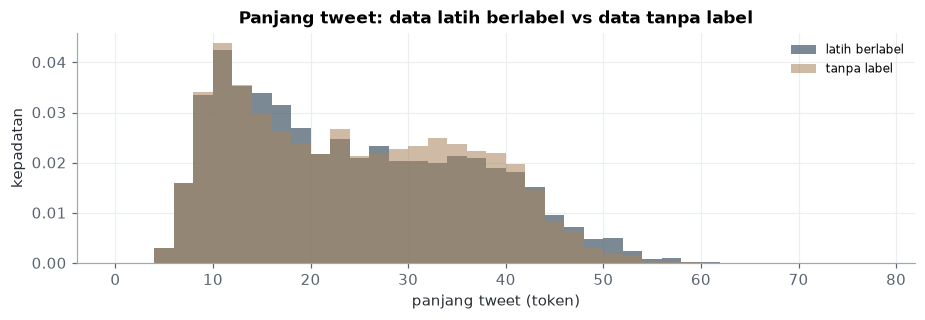

Rata-rata panjang: berlabel 23.8 token | tanpa label 23.8 token


In [41]:
def simple_tokenize(text):
    return re.findall(r"[()\[\]?!.,;:\"]|[^\s()\[\]?!.,;:\"]+", str(text).lower())


labeled_keys = {norm_text(" ".join(t["tokens"])) for t in tweets}
pool, matched = [], set()
for ev in EV_EN.values():
    for txt in pre_df[ev]["full_text"].astype(str):
        k = norm_text(txt)
        if k in labeled_keys:
            matched.add(k)
            continue
        toks = simple_tokenize(txt)
        if toks:
            pool.append({"tokens": toks, "key": k})

seen, uniq = set(), []
for u in pool:
    if u["key"] not in seen:
        seen.add(u["key"])
        uniq.append(u)

vec_all = CountVectorizer(token_pattern=r"\S+").fit(texts + [" ".join(u["tokens"]) for u in uniq])
L_mat = normalize(vec_all.transform(texts))
max_to_labeled = np.zeros(len(uniq))
for s0 in range(0, len(uniq), 2000):
    P = normalize(vec_all.transform([" ".join(u["tokens"]) for u in uniq[s0:s0 + 2000]]))
    max_to_labeled[s0:s0 + 2000] = (P @ L_mat.T).max(axis=1).toarray().ravel()
clean = [u for u, m in zip(uniq, max_to_labeled) if m < 0.8]
random.Random(SEED).shuffle(clean)
unlabeled = [{"tokens": u["tokens"]} for u in clean[:N_UNLABELED]]

print(f"Tweet berlabel yang ditemukan persis di data preprocessed : {len(matched):,} dari {len(labeled_keys):,}")
print(f"Kumpulan tweet tanpa label setelah pencocokan teks        : {len(uniq):,}")
print(f"Dikeluarkan karena mirip tweet berlabel (cosine >= 0,8)    : {len(uniq) - len(clean):,}")
print(f"Kumpulan akhir / tweet tanpa label yang digunakan          : {len(clean):,} / {len(unlabeled):,}")

fig, ax = plt.subplots(figsize=(8.5, 3.0))
bins = np.arange(0, 80, 2)
ax.hist([len(t["tokens"]) for t in train_labeled], bins=bins, density=True, alpha=0.75, color=C_SLATE, label="latih berlabel")
ax.hist([len(u["tokens"]) for u in unlabeled], bins=bins, density=True, alpha=0.55, color=C_SAND, label="tanpa label")
ax.set_xlabel("panjang tweet (token)")
ax.set_ylabel("kepadatan")
ax.set_title("Panjang tweet: data latih berlabel vs data tanpa label")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "figures", "panjang_berlabel_vs_tanpa_label.png"), dpi=150)
plt.show()
print(f"Rata-rata panjang: berlabel {np.mean([len(t['tokens']) for t in train_labeled]):.1f} token | "
      f"tanpa label {np.mean([len(u['tokens']) for u in unlabeled]):.1f} token")

<p style="text-align: justify;">
Penyaringan menghasilkan 52.157 kandidat untuk memilih 5.850 tweet tanpa label, dengan rata-rata panjang 23,8 token. Penyaringan kemiripan merupakan penyesuaian reproduksi; kesamaan panjang belum menjamin kesamaan topik.
</p>


### 6.3 Tokenisasi Subword dan Penyelarasan Label

<p style="text-align: justify;">
Label hanya diberikan pada subword pertama setiap kata; subword lanjutan, token khusus, dan padding diberi -100 agar diabaikan dalam loss. Input dibatasi hingga 256 subtoken atau kapasitas model, sehingga potensi pemotongan perlu diperiksa.
</p>


In [42]:
if RUN_TRANSFORMERS or RUN_KOMODO:
    from transformers import AutoTokenizer, AutoConfig, AutoModelForTokenClassification

TOKENIZERS = {}


def get_tokenizer(name):
    if name not in TOKENIZERS:
        cfg = AutoConfig.from_pretrained(name)
        kw = {"add_prefix_space": True} if cfg.model_type in ("gpt2", "roberta") else {}
        tok = AutoTokenizer.from_pretrained(name, **kw)
        if tok.pad_token is None:
            tok.pad_token = tok.eos_token
        TOKENIZERS[name] = tok
    return TOKENIZERS[name]


def max_len_for(name):
    cfg = AutoConfig.from_pretrained(name)
    limit = getattr(cfg, "n_positions", None) or getattr(cfg, "max_position_embeddings", None) or MAX_LEN
    if cfg.model_type == "roberta":
        limit -= 2
    return min(MAX_LEN, limit)


def make_collate_tf(tok, max_len=MAX_LEN):
    def collate(batch):
        enc = tok([b["tokens"] for b in batch], is_split_into_words=True, truncation=True,
                  max_length=max_len, padding=True, return_tensors="pt")
        L = enc["input_ids"].shape[1]
        labels = torch.full((len(batch), L), -100, dtype=torch.long)
        first_idx = torch.full((len(batch), L), -1, dtype=torch.long)
        for i, b in enumerate(batch):
            prev = None
            for j, w in enumerate(enc.word_ids(batch_index=i)):
                if w is not None and w != prev:
                    first_idx[i, j] = w
                    if b.get("labels") is not None:
                        labels[i, j] = label2id[b["labels"][w]]
                prev = w
        return {"inputs": {"input_ids": enc["input_ids"], "attention_mask": enc["attention_mask"]},
                "labels": labels, "first_idx": first_idx, "n_words": [len(b["tokens"]) for b in batch]}
    return collate


if RUN_TRANSFORMERS:
    tok_demo = get_tokenizer(TRANSFORMER_MODELS["IndoBERT"])
    b = make_collate_tf(tok_demo)([ex])
    demo = pd.DataFrame({"subword": tok_demo.convert_ids_to_tokens(b["inputs"]["input_ids"][0]),
                         "indeks kata": b["first_idx"][0].tolist(),
                         "label (−100 = diabaikan)": [id2label[x] if x >= 0 else -100 for x in b["labels"][0].tolist()]})
    display(demo.T)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17
subword,[CLS],hujan,deras,sejak,sabtu,akibat,##kan,banjir,besar,di,jember,1,orang,meninggal,ratusan,rumah,terendam,[SEP]
indeks kata,-1,0,1,2,3,4,-1,5,6,7,8,9,10,11,12,13,14,-1
label (−100 = diabaikan),-100,REASON-ARG,REASON-ARG,O,TIME-ARG,O,-100,FLOOD-EVENT,FLOOD-EVENT,O,PLACE-ARG,DEATHVICTIM-ARG,DEATHVICTIM-ARG,DEATHVICTIM-ARG,AFFECTEDOBJECTS-ARG,AFFECTEDOBJECTS-ARG,AFFECTEDOBJECTS-ARG,-100


<p style="text-align: justify;">
“Akibatkan” dipecah menjadi <code>akibat</code> dan <code>##kan</code>. Hanya subword pertama menerima target; subword lain tetap membentuk konteks tetapi diabaikan dalam loss.
</p>


### 6.4 Fitur CRF dan Kosakata BiLSTM

<p style="text-align: justify;">
CRF memakai fitur kata, prefiks, sufiks, angka, tanda baca, posisi, dan konteks ±2 kata. BiLSTM memakai embedding 128 dimensi dari kosakata data latih dan tanpa label; kata berfrekuensi kurang dari dua menjadi <code>&lt;unk&gt;</code>.
</p>


In [43]:
def word2features(toks, i):
    w = toks[i]
    f = {"bias": 1.0, "w": w, "w[-3:]": w[-3:], "w[-2:]": w[-2:], "w[:3]": w[:3],
         "isdigit": w.isdigit(), "hasdigit": any(c.isdigit() for c in w),
         "ispunct": not any(c.isalnum() for c in w), "len": min(len(w), 12) / 12}
    for off in (-2, -1, 1, 2):
        j = i + off
        if 0 <= j < len(toks):
            f[f"{off}:w"] = toks[j]
            f[f"{off}:w[-3:]"] = toks[j][-3:]
        else:
            f[f"{off}:pad"] = True
    if i == 0:
        f["BOS"] = True
    if i == len(toks) - 1:
        f["EOS"] = True
    return f


def tweet2features(toks):
    return [word2features(toks, i) for i in range(len(toks))]


counter = collections.Counter(w for t in train_labeled for w in t["tokens"])
counter.update(w for u in unlabeled for w in u["tokens"])
vocab = {"<pad>": 0, "<unk>": 1}
for w, c in counter.most_common():
    if c >= 2:
        vocab[w] = len(vocab)
j = ex["tokens"].index("jember")
print("Contoh fitur CRF untuk kata 'jember':", {k: v for k, v in word2features(ex["tokens"], j).items() if k in ("w", "-1:w", "1:w", "w[-3:]")})
print("Ukuran kosakata BiLSTM:", len(vocab))

Contoh fitur CRF untuk kata 'jember': {'w': 'jember', 'w[-3:]': 'ber', '-1:w': 'di', '1:w': '1'}
Ukuran kosakata BiLSTM: 10495


<p style="text-align: justify;">
Fitur lokal CRF membantu mengenali peran seperti lokasi. Kosakata BiLSTM berisi 10.495 kata, termasuk <code>&lt;pad&gt;</code> dan <code>&lt;unk&gt;</code>.
</p>


<a id="bab-7"></a>
## 7. Baseline

<p style="text-align: justify;">
Paper tidak memakai baseline non-neural, sehingga belum jelas seberapa besar skor yang berasal dari label O dan seberapa besar keunggulan Transformer dibanding metode konvensional. Dua baseline ditambahkan untuk menjawabnya.
</p>

| Baseline | Mengapa dicoba | Konfigurasi |
|---|---|---|
| Mayoritas: semua O | Mengukur skor yang diperoleh tanpa mengekstrak satu pun label peran; menjadi batas bawah F1 berbobot | Seluruh token diprediksi O |
| CRF [8] | Standar pelabelan urutan berbasis fitur eksplisit; menguji apakah Transformer dan self-training sepadan dengan biaya komputasinya | L-BFGS, c1 = 0,1, c2 = 0,1, maksimal 100 iterasi, fitur Bagian 6.4, dilatih pada 3.150 tweet latih |

<p style="text-align: justify;">
Keduanya memakai data uji dan metrik yang sama dengan model neural.
</p>

In [44]:
PAPER_T7 = {
    "IndoBERT": {0.7: (0.764, 0.779, 0.764, 0.721), 0.8: (0.832, 0.831, 0.832, 0.818), 0.9: (0.868, 0.865, 0.868, 0.863)},
    "IndoRoBERTa": {0.7: (0.789, 0.794, 0.789, 0.755), 0.8: (0.802, 0.800, 0.802, 0.777), 0.9: (0.855, 0.847, 0.855, 0.844)},
    "GPT2-Indonesian": {0.7: (0.788, 0.788, 0.788, 0.755), 0.8: (0.823, 0.817, 0.823, 0.805), 0.9: (0.839, 0.832, 0.839, 0.824)},
    "Komodo-7B": {0.7: (0.778, 0.780, 0.778, 0.738), 0.8: (0.863, 0.856, 0.863, 0.855), 0.9: (0.865, 0.859, 0.865, 0.857)},
    "BiLSTM": {0.7: (0.950, 0.760, 0.500, 0.560), 0.8: (0.950, 0.730, 0.550, 0.590), 0.9: (0.950, 0.750, 0.530, 0.590)},
}


def peak_gb():
    return round(torch.cuda.max_memory_allocated() / 1e9, 2) if DEVICE == "cuda" else None


def reset_peak():
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()


def record(key, family, model, predict_fn, hist, t_train, extra=None, save_fn=None):
    test_in = [{"tokens": t["tokens"]} for t in test]
    t0 = time.time()
    pred, conf = predict_fn(model, test_in)
    t_inf = time.time() - t0
    m = evaluate([t["labels"] for t in test], pred)
    out = {"key": key, "family": family, "metrics": m, "pred": pred, "conf": conf, "hist": hist,
           "train_time_s": t_train, "infer_s_per_1000": 1000 * t_inf / len(test), "peak_mem_gb": peak_gb(), "device": DEVICE}
    out.update(extra or {})
    save_json(res_path(key), out)
    best_file = os.path.join(OUT_DIR, "models", slug(family) + "_best.json")
    prev_info = load_json(best_file) if os.path.exists(best_file) else None
    prev = prev_info["f1_w"] if prev_info and prev_info.get("device") == DEVICE else -1
    if save_fn is not None and m["f1_w"] > prev:
        save_fn(model, os.path.join(OUT_DIR, "models", slug(family) + "_best"))
        save_json(best_file, {"key": key, "f1_w": m["f1_w"], "device": DEVICE})
    return out


def tersimpan(key):
    return RESUME and os.path.exists(res_path(key)) and load_json(res_path(key)).get("device") == DEVICE


def load_results():
    return {r["key"]: r for r in (load_json(p) for p in glob.glob(os.path.join(OUT_DIR, "results", "*.json")))}


def results_table(family):
    R = load_results()
    keys = [k for k in R if R[k]["family"] == family]
    keys.sort(key=lambda k: -(R[k].get("threshold") or 0))
    rows = []
    for k in keys:
        r, m, th = R[k], R[k]["metrics"], R[k].get("threshold")
        pp = PAPER_T7.get(family, {}).get(th) if th else None
        rows.append({"setting": "tanpa self-training" if not th else f"self-training θ={th}",
                     "accuracy": m["accuracy"], "precision": m["precision_w"], "recall": m["recall_w"],
                     "F1 berbobot": m["f1_w"], "F1 paper": pp[3] if pp else np.nan,
                     "selisih vs paper": m["f1_w"] - pp[3] if pp else np.nan,
                     "macro-F1 tanpa O": m["f1_macro_noO"], "F1 span": m["f1_span"],
                     "pseudo-label": sum(e["diterima"] for e in r.get("st_log", [])) if th else np.nan,
                     "iterasi": len(r.get("st_log", [])) if th else np.nan,
                     "waktu (menit)": r["train_time_s"] / 60})
    return pd.DataFrame(rows).set_index("setting") if rows else pd.DataFrame()


def show_family(family):
    tbl = results_table(family)
    if tbl.empty:
        display(Markdown(f"*Belum ada hasil untuk {family}.*"))
        return
    display(tbl.style.format("{:.3f}", na_rep="–", subset=[c for c in tbl.columns if c not in ("pseudo-label", "iterasi", "waktu (menit)")])
            .format("{:.0f}", na_rep="–", subset=["pseudo-label", "iterasi"]).format("{:.1f}", subset=["waktu (menit)"]))
    base = tbl.loc["tanpa self-training", "F1 berbobot"] if "tanpa self-training" in tbl.index else np.nan
    st = tbl.drop(index="tanpa self-training", errors="ignore")
    text = f"**{family}.** "
    if not np.isnan(base):
        text += f"Model awal: F1 berbobot {fmt(base)}. "
    if len(st):
        best = st["F1 berbobot"].idxmax()
        text += (f"Terbaik pada {best.replace('θ=', 'θ = ').replace('0.', '0,')}: F1 berbobot {fmt(st.loc[best, 'F1 berbobot'])}"
                 + (f" (paper {fmt(st.loc[best, 'F1 paper'])})" if not np.isnan(st.loc[best, "F1 paper"]) else "")
                 + f", macro-F1 tanpa O {fmt(st.loc[best, 'macro-F1 tanpa O'])}, F1 span {fmt(st.loc[best, 'F1 span'])}")
        if not np.isnan(base):
            text += f"; selisih terhadap model awal {fmt(st.loc[best, 'F1 berbobot'] - base)}"
        text += "."
    display(Markdown(text))

<p style="text-align: justify;">
<code>record()</code> menyimpan prediksi, metrik, dan model terbaik berdasarkan F1 uji. Pemilihan menggunakan test ini berpotensi membuat skor optimistis; perbaikannya dibahas pada 9.2.
</p>


In [45]:
def predict_major(model, items):
    return [["O"] * len(t["tokens"]) for t in items], [[1.0] * len(t["tokens"]) for t in items]


_ = record("Mayoritas (semua O)", "Mayoritas", None, predict_major, None, 0.0)

<p style="text-align: justify;">
Baseline mayoritas memprediksi semua token sebagai O. Hasilnya ditampilkan bersama CRF.
</p>


In [46]:
import sklearn_crfsuite


def predict_crf(model, items):
    X = [tweet2features(t["tokens"]) for t in items]
    pred = model.predict(X)
    conf = [[max(m.values()) for m in s] for s in model.predict_marginals(X)]
    return [list(p) for p in pred], conf


def save_crf(model, path):
    with open(path + ".pkl", "wb") as f:
        pickle.dump(model, f)


crf_path = os.path.join(OUT_DIR, "models", "CRF_best.pkl")
if RESUME and os.path.exists(res_path("CRF")) and os.path.exists(crf_path):
    with open(crf_path, "rb") as f:
        crf = pickle.load(f)
else:
    set_seed()
    t0 = time.time()
    crf = sklearn_crfsuite.CRF(algorithm="lbfgs", c1=0.1, c2=0.1, max_iterations=100, all_possible_transitions=True)
    crf.fit([tweet2features(t["tokens"]) for t in train_labeled], [t["labels"] for t in train_labeled])
    _ = record("CRF", "CRF", crf, predict_crf, None, time.time() - t0,
               extra={"params": len(crf.state_features_) + len(crf.transition_features_)}, save_fn=save_crf)

R = load_results()
base_tbl = pd.DataFrame({k: R[k]["metrics"] for k in ["Mayoritas (semua O)", "CRF"]}).T
display(base_tbl[["accuracy", "precision_w", "recall_w", "f1_w", "f1_macro_noO", "f1_span", "f1_FALSE", "f1_FLOOD"]].round(3))

,accuracy,precision_w,recall_w,f1_w,f1_macro_noO,f1_span,f1_FALSE,f1_FLOOD
Mayoritas (semua O),0.690694,0.477058,0.690694,0.564334,0.0,0.0,0.0,0.0
CRF,0.883267,0.877768,0.883267,0.877869,0.672109,0.69638,0.806761,0.418301


<ul style="text-align: justify;">
<li><b>Mayoritas:</b> F1 berbobot 0,564 walaupun macro-F1 tanpa O dan F1 span bernilai 0. Lebih dari separuh skor F1 berbobot dapat dicapai tanpa mengekstrak informasi, sehingga metrik tanpa O dan F1 span diperlukan (9.1).</li>
<li><b>CRF:</b> F1 berbobot 0,878, macro-F1 tanpa O 0,672, dan F1 span 0,696 dengan sekitar 14 detik pelatihan. Angka ini setara GPT2-Indonesian (0,878) dan hanya 0,029 di bawah IndoBERT (0,907, 10.1), sehingga keunggulan Transformer pada metrik paper tipis.</li>
<li><b>Kelemahan CRF:</b> F1 FLOOD-EVENT 0,418 dan REASON-ARG 0,344. Kedua label bergantung pada konteks kalimat dan frasa panjang yang sulit ditangkap fitur jendela ±2 kata; pada label seperti ini IndoBERT unggul jelas (macro-F1 tanpa O +0,085).</li>
</ul>


<a id="bab-8"></a>
## 8. Metode / Pendekatan yang Digunakan
### 8.1 Rancangan Umum

<p style="text-align: justify;">
Model neural memprediksi 15 label per token dengan cross-entropy. Mengikuti Tabel 6 paper, pelatihan memakai AdamW, learning rate 2e-5, batch 16, weight decay 0,01, maksimal 10 epoch, dan early stopping berdasarkan loss validasi. Model pretrained diunduh dari Hugging Face [29].
</p>

<p style="text-align: justify;">
Dari checkpoint awal yang sama, self-training diuji pada ambang 0,9; 0,8; dan 0,7. Tweet dengan rata-rata keyakinan token memenuhi ambang ditambahkan sebagai pseudo-label, lalu model dilatih ulang sampai tidak ada tweet baru yang diterima atau pool habis. Pembagian ulang data gabungan membuat validasi memuat pseudo-label; dampak dan perbaikannya dibahas di 9.2.
</p>


In [47]:
def logits_of(out):
    return out.logits if hasattr(out, "logits") else out


def split_train_val(items):
    idx = list(range(len(items)))
    random.Random(SEED).shuffle(idx)
    n_val = int(len(items) * VAL_RATIO)
    return [items[i] for i in idx[n_val:]], [items[i] for i in idx[:n_val]]


def param_groups(model, wd):
    decay, no_decay = [], []
    for mod in model.modules():
        is_norm = isinstance(mod, nn.LayerNorm) or "norm" in type(mod).__name__.lower()
        for name, p in mod.named_parameters(recurse=False):
            if not p.requires_grad:
                continue
            (no_decay if (is_norm or "bias" in name) else decay).append(p)
    return [{"params": decay, "weight_decay": wd}, {"params": no_decay, "weight_decay": 0.0}]


def trainable_state(model):
    names = {n for n, p in model.named_parameters() if p.requires_grad}
    return {k: v.detach().cpu().clone() for k, v in model.state_dict().items() if k in names}


@torch.no_grad()
def eval_loss(model, dl, ce, amp):
    model.eval()
    tot, n = 0.0, 0
    for b in dl:
        inp = {k: v.to(DEVICE) for k, v in b["inputs"].items()}
        lab = b["labels"].to(DEVICE)
        with amp_ctx(amp):
            lg = logits_of(model(**inp))
        tot += ce(lg.float().reshape(-1, lg.size(-1)), lab.reshape(-1)).item() * lab.size(0)
        n += lab.size(0)
    return tot / max(n, 1)


def fit(model, items, collate, amp=False, desc="", lr=None, weight_decay=None):
    tr, va = split_train_val(items)
    g = torch.Generator()
    g.manual_seed(SEED)
    dl_tr = DataLoader(tr, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate, generator=g)
    dl_va = DataLoader(va, batch_size=64, shuffle=False, collate_fn=collate)
    wd = WEIGHT_DECAY if weight_decay is None else weight_decay
    opt = torch.optim.AdamW(param_groups(model, wd), lr=lr or LEARNING_RATE)
    total = len(dl_tr) * EPOCHS
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: max(0.0, 1 - s / total))
    ce = nn.CrossEntropyLoss(ignore_index=-100)
    params = [p for p in model.parameters() if p.requires_grad]
    best, best_state, bad, hist = float("inf"), None, 0, []
    for ep in range(1, EPOCHS + 1):
        model.train()
        tot, n, t0 = 0.0, 0, time.time()
        for b in dl_tr:
            inp = {k: v.to(DEVICE) for k, v in b["inputs"].items()}
            lab = b["labels"].to(DEVICE)
            with amp_ctx(amp):
                lg = logits_of(model(**inp))
            loss = ce(lg.float().reshape(-1, lg.size(-1)), lab.reshape(-1))
            opt.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(params, MAX_GRAD_NORM)
            opt.step()
            sched.step()
            tot += loss.item() * lab.size(0)
            n += lab.size(0)
        vl = eval_loss(model, dl_va, ce, amp)
        hist.append({"epoch": ep, "train_loss": tot / n, "val_loss": vl, "detik": time.time() - t0})
        print(f"  [{desc}] epoch {ep:2d} | train loss {tot/n:.4f} | val loss {vl:.4f} | {time.time()-t0:.0f} s")
        if vl < best - 1e-4:
            best, bad, best_state = vl, 0, trainable_state(model)
        else:
            bad += 1
            if bad >= PATIENCE:
                print(f"  [{desc}] early stopping pada epoch {ep}")
                break
    if best_state is not None:
        model.load_state_dict(best_state, strict=False)
    return model, hist


@torch.no_grad()
def predict(model, items, collate, amp=False, bs=64):
    model.eval()
    preds, confs = [], []
    for b in DataLoader(items, batch_size=bs, shuffle=False, collate_fn=collate):
        inp = {k: v.to(DEVICE) for k, v in b["inputs"].items()}
        with amp_ctx(amp):
            prob = logits_of(model(**inp)).float().softmax(-1).cpu()
        fi = b["first_idx"]
        for i, n in enumerate(b["n_words"]):
            lab, cf = ["O"] * n, [None] * n
            pos = (fi[i] >= 0).nonzero().squeeze(-1)
            if len(pos):
                c, k = prob[i, pos].max(-1)
                for w, ci, ki in zip(fi[i, pos].tolist(), c.tolist(), k.tolist()):
                    lab[w], cf[w] = id2label[ki], ci
            preds.append(lab)
            confs.append([x for x in cf if x is not None])
    return preds, confs


def count_params(model):
    return int(sum(p.numel() for p in model.parameters()))


def run_self_training(make_init, fit_fn, predict_fn, T, desc):
    model = make_init()
    L = list(train_labeled)
    U = [{"tokens": u["tokens"]} for u in unlabeled]
    log, it = [], 0
    while MAX_ITER is None or it < MAX_ITER:
        it += 1
        preds, confs = predict_fn(model, U)
        S = [i for i, c in enumerate(confs) if len(c) and float(np.mean(c)) >= T]
        print(f"[{desc}] iterasi {it}: {len(S)} tweet lolos dari {len(U)}")
        entry = {"iter": it, "diterima": len(S), "sisa_U": len(U) - len(S)}
        if not S:
            log.append(entry)
            break
        sel = set(S)
        L += [{"tokens": U[i]["tokens"], "labels": preds[i]} for i in S]
        U = [u for j, u in enumerate(U) if j not in sel]
        model, hist = fit_fn(model, L, desc=f"{desc} iterasi {it}")
        entry.update({"hist": hist, "ukuran_L": len(L)})
        log.append(entry)
        if not U:
            break
    return model, log


def run_family(family, build, fit_fn, predict_fn, save_fn):
    init_path = os.path.join(OUT_DIR, "models", slug(family) + "_init.pt")
    key0 = f"{family} | tanpa self-training"
    fresh = not (tersimpan(key0) and os.path.exists(init_path))
    if fresh:
        set_seed()
        reset_peak()
        t0 = time.time()
        model, hist = fit_fn(build(), train_labeled, desc=f"{family} awal")
        t_train = time.time() - t0
        torch.save(trainable_state(model), init_path)
        record(key0, family, model, predict_fn, hist, t_train, extra={"params": count_params(model)}, save_fn=save_fn)
        del model
    else:
        print(f"{key0}: hasil tersimpan digunakan.")

    def make_init():
        m = build()
        m.load_state_dict(torch.load(init_path, map_location="cpu"), strict=False)
        return m

    for T in THRESHOLDS:
        key = f"{family} | self-training θ={T}"
        if not fresh and tersimpan(key):
            print(f"{key}: hasil tersimpan digunakan.")
            continue
        set_seed()
        reset_peak()
        t0 = time.time()
        model, log = run_self_training(make_init, fit_fn, predict_fn, T, desc=f"{family} θ={T}")
        record(key, family, model, predict_fn, None, time.time() - t0,
               extra={"st_log": log, "params": count_params(model), "threshold": T}, save_fn=save_fn)
        del model
        if DEVICE == "cuda":
            torch.cuda.empty_cache()

<p style="text-align: justify;">
Fungsi bersama menangani pelatihan, prediksi, dan self-training. Karena data gabungan dibagi ulang setiap iterasi, loss validasi yang memuat pseudo-label tidak setara dengan evaluasi terhadap label asli.
</p>


<p style="text-align: justify;">
Checkpoint awal dievaluasi tanpa pelatihan ulang pada 630 tweet validasi hasil rekonstruksi seed 42. CRF tidak disertakan karena dilatih pada seluruh data latih; checkpoint Komodo-7B tidak tersedia.
</p>


In [48]:
import hashlib
import json
import re
from pathlib import Path

import pandas as pd
from IPython.display import display


def _hash_validasi(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def _epoch_validasi_terpilih(hist):
    best = None
    for row in hist:
        if best is None or row["val_loss"] < best["val_loss"] - 1e-4:
            best = row
    if best is None:
        raise ValueError("Riwayat loss validasi tidak tersedia.")
    return best


def _loss_validasi_konfigurasi(family, result_dir):
    records = [json.loads(path.read_text(encoding="utf-8"))
               for path in result_dir.glob("*.json")]
    records = [r for r in records if r["family"] == family]
    initial = next((r for r in records if r.get("threshold") is None), None)
    rows = []
    for record in sorted(records, key=lambda r: r.get("threshold") or 0):
        th = record.get("threshold")
        hist = record.get("hist") or []
        scope = "Validasi awal: data berlabel"
        if th is not None:
            trained = [entry for entry in record.get("st_log", []) if entry.get("hist")]
            if trained:
                hist = trained[-1]["hist"]
                scope = "Validasi gabungan pada pelatihan terakhir"
            else:
                hist = initial.get("hist", []) if initial else []
                scope = "Validasi awal: tidak ada pelatihan ulang"
        if not hist:
            continue
        best = _epoch_validasi_terpilih(hist)
        rows.append({
            "konfigurasi": "tanpa self-training" if th is None else f"self-training ambang {th}",
            "epoch checkpoint": best["epoch"],
            "loss validasi tersimpan": best["val_loss"],
            "cakupan validasi": scope,
        })
    return pd.DataFrame(rows)


def _hitung_validasi_awal(family, inputs, checkpoint, model_dir, history):
    import torch
    import torch.nn as nn
    from sklearn.metrics import accuracy_score, precision_recall_fscore_support

    items, labels = inputs["validation"], inputs["labels"]
    label2id = {label: i for i, label in enumerate(labels)}
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    state = torch.load(checkpoint, map_location="cpu", weights_only=True)
    tokenizer = None

    if family.startswith("BiLSTM"):
        class ValidationBiLSTM(nn.Module):
            def __init__(self):
                super().__init__()
                self.emb = nn.Embedding(len(inputs["vocab"]), 128, padding_idx=0)
                self.lstm = nn.LSTM(128, 64, batch_first=True, bidirectional=True)
                self.out = nn.Linear(128, len(labels))

            def forward(self, input_ids):
                return self.out(self.lstm(self.emb(input_ids))[0])

        model = ValidationBiLSTM()
        max_length = None
    else:
        from transformers import AutoConfig, AutoModelForTokenClassification, AutoTokenizer
        config = AutoConfig.from_pretrained(model_dir, local_files_only=True)
        expected = {i: label for i, label in enumerate(labels)}
        if config.id2label != expected:
            raise ValueError("Urutan label konfigurasi tidak sesuai dengan data validasi.")
        model = AutoModelForTokenClassification.from_config(config)
        kw = {"add_prefix_space": True} if config.model_type in ("roberta", "gpt2") else {}
        tokenizer = AutoTokenizer.from_pretrained(model_dir, local_files_only=True, **kw)
        if tokenizer.pad_token is None:
            tokenizer.pad_token = tokenizer.eos_token
        limit = (getattr(config, "n_positions", None)
                 or getattr(config, "max_position_embeddings", None) or inputs["max_len"])
        if config.model_type == "roberta":
            limit -= 2
        max_length = min(inputs["max_len"], limit)

    model.load_state_dict(state, strict=True)
    del state
    model = model.to(device).eval()
    criterion = nn.CrossEntropyLoss(ignore_index=-100)
    predictions, total_loss, truncated = [], 0.0, 0
    batch_size = inputs["batch_size"]

    try:
        with torch.inference_mode():
            for start in range(0, len(items), batch_size):
                batch = items[start:start + batch_size]
                if tokenizer is None:
                    length = max(len(item["tokens"]) for item in batch)
                    ids = torch.zeros((len(batch), length), dtype=torch.long)
                    targets = torch.full_like(ids, -100)
                    word_ids = []
                    for i, item in enumerate(batch):
                        size = len(item["tokens"])
                        ids[i, :size] = torch.tensor([inputs["vocab"].get(w, 1) for w in item["tokens"]])
                        targets[i, :size] = torch.tensor([label2id[label] for label in item["labels"]])
                        word_ids.append(list(range(size)) + [None] * (length - size))
                    logits = model(input_ids=ids.to(device))
                else:
                    encoded = tokenizer([item["tokens"] for item in batch],
                                        is_split_into_words=True, truncation=True,
                                        max_length=max_length, padding=True, return_tensors="pt")
                    targets = torch.full_like(encoded["input_ids"], -100)
                    word_ids = [encoded.word_ids(batch_index=i) for i in range(len(batch))]
                    for i, item in enumerate(batch):
                        previous = None
                        for j, word in enumerate(word_ids[i]):
                            if word is not None and word != previous:
                                targets[i, j] = label2id[item["labels"][word]]
                            previous = word
                    logits = model(input_ids=encoded["input_ids"].to(device),
                                   attention_mask=encoded["attention_mask"].to(device)).logits

                loss = criterion(logits.float().reshape(-1, len(labels)), targets.to(device).reshape(-1))
                total_loss += loss.item() * len(batch)
                predicted = logits.float().argmax(-1).cpu().tolist()
                for i, item in enumerate(batch):
                    sequence, seen, previous = ["O"] * len(item["tokens"]), set(), None
                    for j, word in enumerate(word_ids[i]):
                        if word is not None and word != previous:
                            sequence[word] = labels[predicted[i][j]]
                            seen.add(word)
                        previous = word
                    truncated += len(item["tokens"]) - len(seen)
                    predictions.append(sequence)
    finally:
        del model
        if device.type == "cuda":
            torch.cuda.empty_cache()

    loss_value = total_loss / len(items)
    epoch = _epoch_validasi_terpilih(history)
    if abs(loss_value - epoch["val_loss"]) > 5e-4:
        raise ValueError(
            f"Loss inferensi {loss_value:.6f} berbeda dari log {epoch['val_loss']:.6f}. "
            "Periksa kesesuaian checkpoint, data, kosakata, dan konfigurasi sebelum melaporkan metrik."
        )
    gold = [label for item in items for label in item["labels"]]
    pred = [label for sequence in predictions for label in sequence]
    precision, recall, f1, _ = precision_recall_fscore_support(
        gold, pred, labels=labels, average="weighted", zero_division=0
    )
    return {
        "family": family, "checkpoint": str(checkpoint), "setting": "tanpa self-training",
        "epoch": epoch["epoch"], "n_validation_tweets": len(items),
        "n_validation_tokens": len(gold), "truncated_words": truncated,
        "averaging": "weighted, termasuk O", "accuracy": float(accuracy_score(gold, pred)),
        "precision_w": float(precision), "recall_w": float(recall), "f1_w": float(f1),
        "val_loss": loss_value, "logged_val_loss": epoch["val_loss"],
        "device": str(device), "validation_ids": [item["text_id"] for item in items],
        "predictions": predictions,
    }


def tampilkan_validasi_awal(family, hitung_ulang=False):
    folder = Path("outputs/validation")
    input_path = folder / "validation_inputs.json"
    name = re.sub(r"[^A-Za-z0-9]+", "_", family).strip("_")
    checkpoint = Path("outputs/models") / f"{name}_init.pt"
    model_dir = Path("outputs/models") / f"{name}_best"
    initial_log = Path("outputs/results") / f"{name}_tanpa_self_training.json"
    result_path = folder / f"{name}_initial_validation.json"
    resources = [initial_log]
    if not family.startswith("BiLSTM"):
        resources += sorted(path for path in model_dir.iterdir()
                            if path.is_file() and path.suffix in (".json", ".txt", ".model"))
    signature = {"inputs_sha256": _hash_validasi(input_path),
                 "checkpoint_sha256": _hash_validasi(checkpoint), "version": 1,
                 "resources_sha256": {str(path): _hash_validasi(path) for path in resources}}
    result = json.loads(result_path.read_text(encoding="utf-8")) if result_path.is_file() else None
    if hitung_ulang or result is None or result.get("signature") != signature:
        inputs = json.loads(input_path.read_text(encoding="utf-8"))
        history = json.loads(initial_log.read_text(encoding="utf-8"))["hist"]
        result = _hitung_validasi_awal(family, inputs, checkpoint, model_dir, history)
        result["signature"] = signature
        result_path.write_text(json.dumps(result, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")

    table = pd.DataFrame([{
        "model": family, "checkpoint": "awal, tanpa self-training", "epoch": result["epoch"],
        "tweet validasi": result["n_validation_tweets"], "token validasi": result["n_validation_tokens"],
        "val accuracy": result["accuracy"], "val precision berbobot": result["precision_w"],
        "val recall berbobot": result["recall_w"], "val F1 berbobot": result["f1_w"],
        "val loss": result["val_loss"],
    }])
    metrics = [column for column in table.columns if column.startswith("val ")]
    display(table.style.format({column: "{:.4f}" for column in metrics}, decimal=","))
    print("Precision, recall, dan F1 dihitung per token dengan bobot jumlah token setiap label, termasuk O.")
    print(f"Kata yang terpotong: {result['truncated_words']}. Tidak ada pembaruan bobot model.")
    losses = _loss_validasi_konfigurasi(family, Path("outputs/results"))
    display(losses.style.format({"loss validasi tersimpan": "{:.4f}"}, decimal=","))
    print("Untuk konfigurasi yang dilatih ulang, loss self-training berasal dari validasi gabungan pada pelatihan terakhir.")
    return result


### 8.2 BiLSTM

<p style="text-align: justify;">
BiLSTM menggunakan embedding 128 dimensi, LSTM dua arah dengan 64 unit per arah, dan klasifikasi 15 label. Model dilatih dari awal; learning rate reproduksi belum tentu optimal untuk arsitektur ini.
</p>


In [49]:
class BiLSTMTagger(nn.Module):
    def __init__(self, vocab_size, n_tags, emb=128, hid=64):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb, padding_idx=0)
        self.lstm = nn.LSTM(emb, hid, batch_first=True, bidirectional=True)
        self.out = nn.Linear(2 * hid, n_tags)

    def forward(self, input_ids, attention_mask=None):
        return self.out(self.lstm(self.emb(input_ids))[0])


def collate_bilstm(batch):
    L = max(len(b["tokens"]) for b in batch)
    ids = torch.zeros(len(batch), L, dtype=torch.long)
    lab = torch.full((len(batch), L), -100, dtype=torch.long)
    fi = torch.full((len(batch), L), -1, dtype=torch.long)
    for i, b in enumerate(batch):
        n = len(b["tokens"])
        ids[i, :n] = torch.tensor([vocab.get(w, 1) for w in b["tokens"]])
        fi[i, :n] = torch.arange(n)
        if b.get("labels") is not None:
            lab[i, :n] = torch.tensor([label2id[l] for l in b["labels"]])
    return {"inputs": {"input_ids": ids}, "labels": lab, "first_idx": fi, "n_words": [len(b["tokens"]) for b in batch]}


def build_bilstm():
    set_seed()
    return BiLSTMTagger(len(vocab), len(LABELS)).to(DEVICE)


def fit_bilstm(model, items, desc="BiLSTM"):
    return fit(model, items, collate_bilstm, amp=False, desc=desc)


def predict_bilstm(model, items):
    return predict(model, items, collate_bilstm, amp=False)


def save_torch(model, path):
    torch.save(model.state_dict(), path + ".pt")


run_family("BiLSTM", build_bilstm, fit_bilstm, predict_bilstm, save_torch)
show_family("BiLSTM")

BiLSTM | tanpa self-training: hasil tersimpan digunakan.
BiLSTM | self-training θ=0.9: hasil tersimpan digunakan.
BiLSTM | self-training θ=0.8: hasil tersimpan digunakan.
BiLSTM | self-training θ=0.7: hasil tersimpan digunakan.


,accuracy,precision,recall,F1 berbobot,F1 paper,selisih vs paper,macro-F1 tanpa O,F1 span,pseudo-label,iterasi,waktu (menit)
setting,,,,,,,,,,,
self-training θ=0.9,0.689,0.486,0.689,0.564,0.590,-0.026,0.000,0.001,0,1,0.0
self-training θ=0.8,0.689,0.486,0.689,0.564,0.590,-0.026,0.000,0.001,0,1,0.0
self-training θ=0.7,0.709,0.654,0.709,0.605,0.560,0.045,0.073,0.113,5847,6,1.8
tanpa self-training,0.689,0.486,0.689,0.564,–,–,0.000,0.001,–,–,0.2


**BiLSTM.** Model awal: F1 berbobot 0,564. Terbaik pada self-training θ = 0,7: F1 berbobot 0,605 (paper 0,560), macro-F1 tanpa O 0,073, F1 span 0,113; selisih terhadap model awal 0,042.

<p style="text-align: justify;">
Dengan learning rate 2e-5 dari paper, BiLSTM gagal belajar: F1 berbobot model awal 0,564 (sama dengan baseline mayoritas) dan macro-F1 tanpa O 0,000. Pada θ = 0,9 dan 0,8 tidak ada pseudo-label yang lolos; hanya θ = 0,7 yang naik ke 0,605 (paper 0,560). Skor yang mirip paper ini berasal dari prediksi yang hampir seluruhnya O.
</p>

In [50]:
validasi_bilstm = tampilkan_validasi_awal('BiLSTM')


,model,checkpoint,epoch,tweet validasi,token validasi,val accuracy,val precision berbobot,val recall berbobot,val F1 berbobot,val loss
0,BiLSTM,"awal, tanpa self-training",10,630,14824,"0,6856","0,4889","0,6856","0,5590","1,7009"


Precision, recall, dan F1 dihitung per token dengan bobot jumlah token setiap label, termasuk O.
Kata yang terpotong: 0. Tidak ada pembaruan bobot model.


,konfigurasi,epoch checkpoint,loss validasi tersimpan,cakupan validasi
0,tanpa self-training,10,"1,7009",Validasi awal: data berlabel
1,self-training ambang 0.7,10,"0,4217",Validasi gabungan pada pelatihan terakhir
2,self-training ambang 0.8,10,"1,7009",Validasi awal: tidak ada pelatihan ulang
3,self-training ambang 0.9,10,"1,7009",Validasi awal: tidak ada pelatihan ulang


Untuk konfigurasi yang dilatih ulang, loss self-training berasal dari validasi gabungan pada pelatihan terakhir.


<p style="text-align: justify;">
Pada 630 tweet validasi, checkpoint awal BiLSTM memperoleh accuracy 0,6856 dan F1 berbobot 0,5590, dengan loss 1,7009 pada epoch ke-10 sesuai log pelatihan. Hasil ini konsisten dengan data uji: prediksi masih didominasi label O. Loss θ = 0,8 dan 0,9 sama dengan model awal karena tidak ada pelatihan ulang, sedangkan loss θ = 0,7 (0,4217) berasal dari validasi gabungan yang memuat pseudo-label sehingga tidak sebanding.
</p>

### 8.3 IndoBERT

<p style="text-align: justify;">
IndoBERT (<code>indolem/indobert-base-uncased</code>) [12] memakai konteks dua arah untuk pelabelan token. Model ini menjadi acuan utama karena meraih F1 terbaik pada paper.
</p>


In [51]:
def tf_funcs(name):
    tok = get_tokenizer(name)
    collate = make_collate_tf(tok, max_len_for(name))

    def build():
        set_seed()
        m = AutoModelForTokenClassification.from_pretrained(name, num_labels=len(LABELS), id2label=id2label, label2id=label2id)
        if m.config.pad_token_id is None:
            m.config.pad_token_id = tok.pad_token_id
        return m.to(DEVICE)

    def fit_fn(model, items, desc=""):
        return fit(model, items, collate, amp=True, desc=desc)

    def predict_fn(model, items):
        return predict(model, items, collate, amp=True)

    def save_fn(model, path):
        model.save_pretrained(path)
        tok.save_pretrained(path)

    return build, fit_fn, predict_fn, save_fn


def run_transformer(family):
    if RUN_TRANSFORMERS:
        run_family(family, *tf_funcs(TRANSFORMER_MODELS[family]))
    else:
        print(f"RUN_TRANSFORMERS = False: training {family} tidak dijalankan pada sesi ini.")
    show_family(family)


run_transformer("IndoBERT")

IndoBERT | tanpa self-training: hasil tersimpan digunakan.
IndoBERT | self-training θ=0.9: hasil tersimpan digunakan.
IndoBERT | self-training θ=0.8: hasil tersimpan digunakan.
IndoBERT | self-training θ=0.7: hasil tersimpan digunakan.


,accuracy,precision,recall,F1 berbobot,F1 paper,selisih vs paper,macro-F1 tanpa O,F1 span,pseudo-label,iterasi,waktu (menit)
setting,,,,,,,,,,,
self-training θ=0.9,0.905,0.910,0.905,0.907,0.863,0.044,0.756,0.743,5850,9,60.1
self-training θ=0.8,0.906,0.910,0.906,0.907,0.818,0.089,0.757,0.738,5850,4,61.5
self-training θ=0.7,0.906,0.911,0.906,0.907,0.721,0.186,0.754,0.736,5850,2,18.5
tanpa self-training,0.903,0.906,0.903,0.903,–,–,0.738,0.724,–,–,4.4


**IndoBERT.** Model awal: F1 berbobot 0,903. Terbaik pada self-training θ = 0,8: F1 berbobot 0,907 (paper 0,818), macro-F1 tanpa O 0,757, F1 span 0,738; selisih terhadap model awal 0,004.

<p style="text-align: justify;">
IndoBERT memperoleh F1 berbobot 0,903 tanpa self-training dan 0,907 pada ketiga ambang, di atas angka paper (0,863 pada θ = 0,9). Seluruh 5.850 tweet tanpa label akhirnya diterima pada setiap ambang, sehingga ambang hanya memengaruhi jumlah iterasi. Kenaikan dari self-training kecil (+0,004 F1 berbobot dan +0,02 macro-F1 tanpa O).
</p>

In [52]:
validasi_indobert = tampilkan_validasi_awal('IndoBERT')


,model,checkpoint,epoch,tweet validasi,token validasi,val accuracy,val precision berbobot,val recall berbobot,val F1 berbobot,val loss
0,IndoBERT,"awal, tanpa self-training",4,630,14824,"0,9030","0,9051","0,9030","0,9030","0,2920"


Precision, recall, dan F1 dihitung per token dengan bobot jumlah token setiap label, termasuk O.
Kata yang terpotong: 0. Tidak ada pembaruan bobot model.


,konfigurasi,epoch checkpoint,loss validasi tersimpan,cakupan validasi
0,tanpa self-training,4,"0,2920",Validasi awal: data berlabel
1,self-training ambang 0.7,2,"0,1177",Validasi gabungan pada pelatihan terakhir
2,self-training ambang 0.8,2,"0,1025",Validasi gabungan pada pelatihan terakhir
3,self-training ambang 0.9,2,"0,0587",Validasi gabungan pada pelatihan terakhir


Untuk konfigurasi yang dilatih ulang, loss self-training berasal dari validasi gabungan pada pelatihan terakhir.


<p style="text-align: justify;">
Pada validasi awal, IndoBERT memperoleh accuracy 0,9030 dan F1 berbobot 0,9030, dengan loss 0,2920 pada epoch ke-4 sesuai log pelatihan, sejalan dengan F1 uji model awal (0,903). Loss self-training (0,0587–0,1177) lebih rendah karena dihitung pada validasi gabungan yang memuat pseudo-label buatan model sendiri, sehingga tidak menunjukkan peningkatan kualitas terhadap label asli.
</p>

### 8.4 IndoRoBERTa

<p style="text-align: justify;">
IndoRoBERTa (<code>w11wo/indo-roberta-small</code>) [13] merupakan encoder dua arah dengan tokenisasi byte-level BPE. Model dievaluasi menggunakan pembagian data dan metrik yang sama dengan IndoBERT.
</p>


In [53]:
run_transformer("IndoRoBERTa")

IndoRoBERTa | tanpa self-training: hasil tersimpan digunakan.
IndoRoBERTa | self-training θ=0.9: hasil tersimpan digunakan.
IndoRoBERTa | self-training θ=0.8: hasil tersimpan digunakan.
IndoRoBERTa | self-training θ=0.7: hasil tersimpan digunakan.


,accuracy,precision,recall,F1 berbobot,F1 paper,selisih vs paper,macro-F1 tanpa O,F1 span,pseudo-label,iterasi,waktu (menit)
setting,,,,,,,,,,,
self-training θ=0.9,0.885,0.882,0.885,0.882,0.844,0.038,0.675,0.658,5850,14,52.4
self-training θ=0.8,0.885,0.882,0.885,0.882,0.777,0.105,0.681,0.659,5849,8,56.4
self-training θ=0.7,0.882,0.880,0.882,0.879,0.755,0.124,0.666,0.646,5850,2,8.9
tanpa self-training,0.880,0.878,0.880,0.877,–,–,0.666,0.637,–,–,3.9


**IndoRoBERTa.** Model awal: F1 berbobot 0,877. Terbaik pada self-training θ = 0,9: F1 berbobot 0,882 (paper 0,844), macro-F1 tanpa O 0,675, F1 span 0,658; selisih terhadap model awal 0,005.

<p style="text-align: justify;">
IndoRoBERTa memperoleh F1 berbobot 0,877 tanpa self-training dan paling tinggi 0,882 pada θ = 0,9 (paper 0,844). Self-training hanya menambah sekitar 0,005, dan hasilnya berada di bawah IndoBERT (0,907) serta hanya sedikit di atas CRF (0,878).
</p>

In [54]:
validasi_indoroberta = tampilkan_validasi_awal('IndoRoBERTa')


,model,checkpoint,epoch,tweet validasi,token validasi,val accuracy,val precision berbobot,val recall berbobot,val F1 berbobot,val loss
0,IndoRoBERTa,"awal, tanpa self-training",6,630,14824,"0,8809","0,8798","0,8809","0,8793","0,3758"


Precision, recall, dan F1 dihitung per token dengan bobot jumlah token setiap label, termasuk O.
Kata yang terpotong: 0. Tidak ada pembaruan bobot model.


,konfigurasi,epoch checkpoint,loss validasi tersimpan,cakupan validasi
0,tanpa self-training,6,"0,3758",Validasi awal: data berlabel
1,self-training ambang 0.7,1,"0,1386",Validasi gabungan pada pelatihan terakhir
2,self-training ambang 0.8,1,"0,1129",Validasi gabungan pada pelatihan terakhir
3,self-training ambang 0.9,2,"0,0745",Validasi gabungan pada pelatihan terakhir


Untuk konfigurasi yang dilatih ulang, loss self-training berasal dari validasi gabungan pada pelatihan terakhir.


<p style="text-align: justify;">
Checkpoint awal IndoRoBERTa memperoleh accuracy 0,8809 dan F1 berbobot 0,8793 pada 630 tweet validasi, dengan loss 0,3758 pada epoch ke-6 sesuai log pelatihan. F1 ini lebih rendah daripada IndoBERT (0,9030) pada data validasi yang sama. Loss self-training (0,0745–0,1386) berasal dari validasi gabungan sehingga tidak sebanding dengan loss validasi awal.
</p>

### 8.5 GPT2-Indonesian

<p style="text-align: justify;">
GPT2-Indonesian (<code>cahya/gpt2-small-indonesian-522M</code>) [14] memprediksi label dari konteks sebelumnya. Akses konteks kausal menjadi pembanding bagi encoder dua arah; angka 522M pada nama repositori merujuk ukuran korpus, bukan jumlah parameter.
</p>


In [55]:
run_transformer("GPT2-Indonesian")

GPT2-Indonesian | tanpa self-training: hasil tersimpan digunakan.
GPT2-Indonesian | self-training θ=0.9: hasil tersimpan digunakan.
GPT2-Indonesian | self-training θ=0.8: hasil tersimpan digunakan.
GPT2-Indonesian | self-training θ=0.7: hasil tersimpan digunakan.


,accuracy,precision,recall,F1 berbobot,F1 paper,selisih vs paper,macro-F1 tanpa O,F1 span,pseudo-label,iterasi,waktu (menit)
setting,,,,,,,,,,,
self-training θ=0.9,0.880,0.876,0.880,0.877,0.824,0.053,0.664,0.607,5847,17,73.1
self-training θ=0.8,0.880,0.879,0.880,0.878,0.805,0.073,0.671,0.614,5850,6,28.5
self-training θ=0.7,0.880,0.877,0.880,0.876,0.755,0.121,0.661,0.617,5850,3,14.4
tanpa self-training,0.872,0.870,0.872,0.870,–,–,0.660,0.595,–,–,3.2


**GPT2-Indonesian.** Model awal: F1 berbobot 0,870. Terbaik pada self-training θ = 0,8: F1 berbobot 0,878 (paper 0,805), macro-F1 tanpa O 0,671, F1 span 0,614; selisih terhadap model awal 0,008.

<p style="text-align: justify;">
GPT2-Indonesian memperoleh F1 berbobot 0,870 tanpa self-training dan paling tinggi 0,878 pada θ = 0,8 (paper 0,805). F1 span-nya (0,595–0,617) lebih rendah daripada IndoBERT dan IndoRoBERTa, kemungkinan karena GPT-2 hanya melihat konteks sebelum token, padahal status kejadian sering ditentukan oleh kata sesudahnya.
</p>

In [56]:
validasi_gpt2 = tampilkan_validasi_awal('GPT2-Indonesian')


,model,checkpoint,epoch,tweet validasi,token validasi,val accuracy,val precision berbobot,val recall berbobot,val F1 berbobot,val loss
0,GPT2-Indonesian,"awal, tanpa self-training",2,630,14824,"0,8745","0,8703","0,8745","0,8710","0,3843"


Precision, recall, dan F1 dihitung per token dengan bobot jumlah token setiap label, termasuk O.
Kata yang terpotong: 0. Tidak ada pembaruan bobot model.


,konfigurasi,epoch checkpoint,loss validasi tersimpan,cakupan validasi
0,tanpa self-training,2,"0,3843",Validasi awal: data berlabel
1,self-training ambang 0.7,1,"0,1604",Validasi gabungan pada pelatihan terakhir
2,self-training ambang 0.8,1,"0,1445",Validasi gabungan pada pelatihan terakhir
3,self-training ambang 0.9,1,"0,0792",Validasi gabungan pada pelatihan terakhir


Untuk konfigurasi yang dilatih ulang, loss self-training berasal dari validasi gabungan pada pelatihan terakhir.


<p style="text-align: justify;">
GPT2-Indonesian memperoleh accuracy 0,8745 dan F1 berbobot 0,8710 pada validasi awal, dengan loss 0,3843 pada epoch ke-2 sebelum loss validasi kembali naik. Skor ini lebih rendah daripada IndoBERT (0,9030) dan IndoRoBERTa (0,8793) pada data validasi yang sama. Loss self-training (0,0792–0,1604) berasal dari validasi gabungan sehingga tidak sebanding dengan loss validasi awal.
</p>

### 8.6 Komodo-7B

<p style="text-align: justify;">
Komodo-7B (<code>Yellow-AI-NLP/komodo-7b-base</code>) [15] dilatih pada notebook terpisah. Paper menyebut Komodo dijalankan dengan kuantisasi untuk menekan ukuran model [1], tetapi tidak merinci konfigurasinya; fine-tuning LLM terkuantisasi umumnya memakai adaptor berperingkat rendah seperti QLoRA [30]. Hasilnya diimpor untuk perbandingan dan tidak disertakan dalam pemilihan model final.
</p>

In [61]:
import os
import glob
import json
import pandas as pd

def load_json(filepath):
    """Membaca dan memuat data dari berkas JSON."""
    with open(filepath, 'r', encoding='utf-8') as f:
        return json.load(f)

OUT_DIR = "." 
os.makedirs(os.path.join(OUT_DIR, "exports"), exist_ok=True)

komodo_dir = os.path.join("imports", "komodo")
os.makedirs(komodo_dir, exist_ok=True)
komodo_rows = []

for p in sorted(glob.glob(os.path.join(komodo_dir, "*.json"))):
    data = load_json(p)
    records = data if isinstance(data, list) else [data]
    for r in records:
        m = r.get("metrics", r)
        komodo_rows.append({
            "sumber": os.path.basename(p),
            "model": r.get("key", "Komodo-7B"),
            "accuracy": m.get("accuracy"),
            "precision": m.get("precision_w", m.get("precision")),
            "recall": m.get("recall_w", m.get("recall")),
            "F1 test eksternal": m.get("f1_w", m.get("f1")),
        })

if komodo_rows:
    KOMODO_EXTERNAL = pd.DataFrame(komodo_rows)
    display(KOMODO_EXTERNAL)
    KOMODO_EXTERNAL.to_csv(
        os.path.join(OUT_DIR, "exports", "komodo_legacy_external.csv"),
        index=False
    )
else:
    KOMODO_EXTERNAL = pd.DataFrame()
    print("Belum ada JSON Komodo di imports/komodo/. Sel ini tidak menjalankan training.")

,sumber,model,accuracy,precision,recall,F1 test eksternal
0,Komodo_7B_self_training_0_7.json,Komodo-7B | self-training θ=0.7,0.876410,0.872546,0.876410,0.870167
1,Komodo_7B_self_training_0_8.json,Komodo-7B | self-training θ=0.8,0.878021,0.872910,0.878021,0.871054
2,Komodo_7B_self_training_0_9.json,Komodo-7B | self-training θ=0.9,0.877153,0.870258,0.877153,0.869704
3,Komodo_7B_tanpa_self_training.json,Komodo-7B | tanpa self-training,0.875046,0.868582,0.875046,0.868132


<p style="text-align: justify;">
Hasil impor Komodo-7B mencapai F1 berbobot 0,868 tanpa self-training dan 0,871 pada θ = 0,8 (paper: 0,855). Hasil ini masih di bawah IndoBERT dan CRF.
</p>


<a id="bab-9"></a>
## 9. Validasi dan Evaluasi

### 9.1 Protokol dan Metrik

<ul style="text-align: justify;">
<li><b>Pembagian data.</b> 1.000 tweet uji (250 per kejadian) tidak dipakai untuk training maupun pseudo-label. Mengikuti Algorithm 1, data latih (berlabel ditambah pseudo-label) dibagi ulang 80/20 menjadi latih dan validasi setiap kali model dilatih.</li>
<li><b>Seed.</b> 42 untuk pembagian data dan pelatihan; cross-validation tidak dipakai, mengikuti paper.</li>
<li><b>Pemilihan epoch.</b> Loss validasi terkecil (early stopping).</li>
<li><b>Pemilihan model final.</b> F1 berbobot tertinggi pada data uji. Paper juga membandingkan ambang dengan skor uji (Tabel 7); cara ini berisiko bias seleksi [25] sehingga diperbaiki pada 9.2. Seluruh ambang tetap dilaporkan.</li>
</ul>

<p style="text-align: justify;">
Metrik dihitung per token, kecuali F1 span yang menilai frasa utuh.
</p>

| Metrik | Arti | Alasan dilaporkan |
|---|---|---|
| Accuracy, precision, recall, **F1 berbobot termasuk O** | F1 per label dibobot jumlah token, label O ikut dihitung | Metrik paper; pembanding Tabel 7 |
| F1 berbobot tanpa O | Sama, tanpa label O | Menghilangkan pengaruh O yang mudah ditebak |
| **Macro-F1 tanpa O** | Rata-rata F1 dari 14 label peran | Label langka dianggap sama penting |
| **F1 span** | Frasa benar bila batas awal, batas akhir, dan labelnya tepat | Standar evaluasi SRL/NER CoNLL [21] |
| **F1 per label** | F1 setiap label | Pembanding Gambar 7–8 paper |
| F1 FALSE-EVENT, F1 FLOOD-EVENT | F1 dua label yang paling sering tertukar | Dasar Novelty 1 |

<p style="text-align: justify;">
Precision = TP / (TP + FP), recall = TP / (TP + FN), F1 = 2 × P × R / (P + R), dan F1 berbobot = Σ (proporsi token label × F1 label). Contoh berikut memperlihatkan bagaimana label O membuat F1 berbobot jauh lebih tinggi daripada macro-F1 tanpa O.
</p>

In [66]:
g_demo = [["FLOOD-EVENT", "O", "PLACE-ARG"], ["O", "FALSE-EVENT", "FALSE-EVENT"]]
p_demo = [["FALSE-EVENT", "O", "PLACE-ARG"], ["O", "FALSE-EVENT", "O"]]
m_demo = evaluate(g_demo, p_demo)
display(pd.Series({k: v for k, v in m_demo.items() if k != "f1_per_label"}).round(3).to_frame("nilai").T)
print("F1 per label:", {k: round(v, 3) for k, v in m_demo["f1_per_label"].items() if k in ("O", "FLOOD-EVENT", "FALSE-EVENT", "PLACE-ARG")})
print("Span asli    :", [spans(x) for x in g_demo])
print("Span prediksi:", [spans(x) for x in p_demo])

,accuracy,precision_w,recall_w,f1_w,f1_w_noO,f1_macro_noO,f1_span,f1_FALSE,f1_FLOOD
nilai,0.667,0.556,0.667,0.6,0.5,0.107,0.333,0.5,0.0


F1 per label: {'O': 0.8, 'FALSE-EVENT': 0.5, 'FLOOD-EVENT': 0.0, 'PLACE-ARG': 1.0}
Span asli    : [[(0, 1, 'FLOOD-EVENT'), (2, 3, 'PLACE-ARG')], [(1, 3, 'FALSE-EVENT')]]
Span prediksi: [[(0, 1, 'FALSE-EVENT'), (2, 3, 'PLACE-ARG')], [(1, 2, 'FALSE-EVENT')]]


### 9.2 Perbaikan Protokol Pseudo-label

<p style="text-align: justify;">
Algorithm 1 menggabungkan data berlabel dan pseudo-label, lalu membaginya ulang 80/20 setiap iterasi [1]. Akibatnya, validasi berubah setiap iterasi dan sebagian isinya adalah label buatan model sendiri. Loss validasi self-training pada Bab 8 (IndoBERT 0,0587–0,1177) tampak jauh lebih rendah daripada model awal (0,2920) karena model dinilai pada labelnya sendiri, bukan karena kualitasnya naik. Selain itu, ambang dan model final dipilih dari F1 uji, sehingga data uji ikut menentukan keputusan [25].
</p>

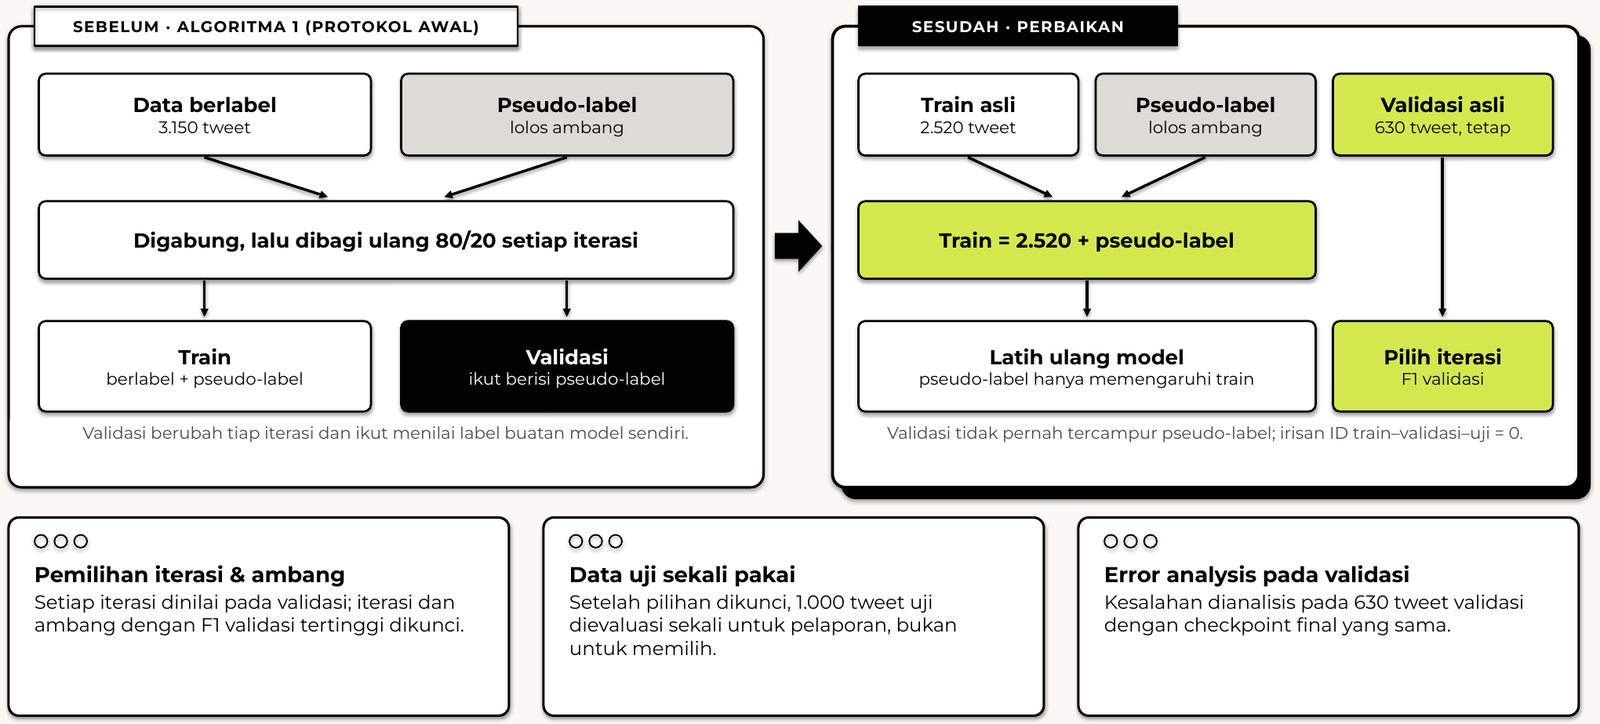

<p style="text-align: center;"><i>Gambar 9.1. Protokol awal (Algorithm 1) dan protokol perbaikan: pseudo-label hanya ditambahkan ke data latih.</i></p>

<ul style="text-align: justify;">
<li><b>Pseudo-label hanya ke data latih.</b> Data latih = 2.520 tweet asli + pseudo-label yang lolos ambang, tanpa pembagian ulang.</li>
<li><b>Validasi tetap.</b> 630 tweet berlabel asli dipakai pada semua iterasi dan ambang, sehingga loss dan F1 validasi sebanding antar-iterasi; irisan ID latih, validasi, dan uji = 0.</li>
<li><b>Pemilihan berdasarkan validasi.</b> Epoch dipilih dari loss validasi; iterasi dan ambang dipilih dari F1 validasi tertinggi, bukan iterasi terakhir.</li>
<li><b>Data uji sekali pakai.</b> 1.000 tweet uji dievaluasi satu kali setelah pilihan dikunci; error analysis untuk pengembangan memakai validasi.</li>
</ul>


<a id="bab-10"></a>
## 10. Hasil Eksperimen dan Analisis
### 10.1 Rekap seluruh model

<p style="text-align: justify;">
Rekap menyajikan hasil seluruh model, perbandingan setiap ambang dengan Tabel 7 paper, dan F1 per label dari Gambar 7–8.
</p>


In [67]:
from pathlib import Path
import json

OUT_DIR = str(
    Path(r"C:\Users\HP Victus\Documents\Probation KC"
         r"\SRL_FALSE-EVENT_Checkpoint1\outputs")
)

def load_results():
    folder = Path(OUT_DIR) / "results"
    hasil = {}
    for path in sorted(folder.glob("*.json")):
        r = json.loads(path.read_text(encoding="utf-8-sig"))
        hasil[r["key"]] = r

    if not hasil:
        raise FileNotFoundError(f"JSON hasil tidak ditemukan: {folder}")
    return hasil

RES = load_results()
print(f"{len(RES)} hasil eksperimen terbaca.")

26 hasil eksperimen terbaca.


In [68]:
ORDER = ["Mayoritas", "CRF", "BiLSTM", "IndoBERT", "IndoRoBERTa", "GPT2-Indonesian", "Komodo-7B", "BiLSTM (Adam lr 1e-3)"]
RES = load_results()


def sort_key(k):
    fam = RES[k]["family"]
    th = RES[k].get("threshold")
    return (ORDER.index(fam) if fam in ORDER else 99, -th if th else -1)


main_keys = [k for k in sorted(RES, key=sort_key) if RES[k]["family"] != "BiLSTM (Adam lr 1e-3)"]
rows = []
for k in main_keys:
    r, m, th = RES[k], RES[k]["metrics"], RES[k].get("threshold")
    pp = PAPER_T7.get(r["family"], {}).get(th) if th else None
    rows.append({"model": k, "accuracy": m["accuracy"], "precision": m["precision_w"], "recall": m["recall_w"],
                 "F1 berbobot (cara paper)": m["f1_w"], "F1 paper": pp[3] if pp else np.nan,
                 "selisih vs paper": m["f1_w"] - pp[3] if pp else np.nan,
                 "macro-F1 tanpa O": m["f1_macro_noO"], "F1 span": m["f1_span"], "F1 FALSE-EVENT": m["f1_FALSE"],
                 "F1 FLOOD-EVENT": m["f1_FLOOD"], "device": r["device"]})
results_df = pd.DataFrame(rows).set_index("model")
results_df.to_csv(os.path.join(OUT_DIR, "hasil_semua_model.csv"))
num_cols = [c for c in results_df.columns if c != "device"]
display(results_df.style.format("{:.3f}", na_rep="–", subset=num_cols)
        .background_gradient(subset=["F1 berbobot (cara paper)", "macro-F1 tanpa O", "F1 span"], cmap=SEQ_CMAP))

,accuracy,precision,recall,F1 berbobot (cara paper),F1 paper,selisih vs paper,macro-F1 tanpa O,F1 span,F1 FALSE-EVENT,F1 FLOOD-EVENT,device
model,,,,,,,,,,,
Mayoritas (semua O),0.691,0.477,0.691,0.564,–,–,0.000,0.000,0.000,0.000,cuda
CRF,0.883,0.878,0.883,0.878,–,–,0.672,0.696,0.807,0.418,cuda
BiLSTM | tanpa self-training,0.689,0.486,0.689,0.564,–,–,0.000,0.001,0.002,0.000,cuda
BiLSTM | self-training θ=0.9,0.689,0.486,0.689,0.564,0.590,-0.026,0.000,0.001,0.002,0.000,cuda
BiLSTM | self-training θ=0.8,0.689,0.486,0.689,0.564,0.590,-0.026,0.000,0.001,0.002,0.000,cuda
BiLSTM | self-training θ=0.7,0.709,0.654,0.709,0.605,0.560,0.045,0.073,0.113,0.328,0.000,cuda
IndoBERT | tanpa self-training,0.903,0.906,0.903,0.903,–,–,0.738,0.724,0.858,0.713,cuda
IndoBERT | self-training θ=0.9,0.905,0.910,0.905,0.907,0.863,0.044,0.756,0.743,0.864,0.710,cuda
IndoBERT | self-training θ=0.8,0.906,0.910,0.906,0.907,0.818,0.089,0.757,0.738,0.864,0.753,cuda


<p style="text-align: justify;">
Tabel rekap menunjukkan IndoBERT sebagai model terbaik (F1 berbobot 0,907 dan macro-F1 tanpa O hingga 0,757). IndoRoBERTa, GPT2-Indonesian, dan Komodo-7B berada pada F1 berbobot 0,868–0,882, setara dengan CRF (0,878), sedangkan BiLSTM dengan hyperparameter paper setara atau hanya sedikit di atas baseline mayoritas (0,564–0,605).
</p>

<p style="text-align: justify;">
<b>Perbandingan dengan Tabel 7 paper.</b> Tabel berikut menyandingkan metrik reproduksi dengan angka paper pada model dan ambang yang sama. Keduanya hasil data uji, tetapi tweet ujinya tidak identik, sehingga selisih kecil belum tentu bermakna.
</p>

In [69]:
FAM_PAPER = ["BiLSTM", "IndoBERT", "IndoRoBERTa", "GPT2-Indonesian", "Komodo-7B"]
PAPER_TH = [0.9, 0.8, 0.7]
METRIC_KEYS = [("Accuracy", "accuracy", 0), ("Precision", "precision_w", 1), ("Recall", "recall_w", 2), ("F1", "f1_w", 3)]
rows = []
for fam in FAM_PAPER:
    for th in PAPER_TH:
        key = f"{fam} | self-training θ={th}"
        r = RES.get(key)
        row = {("Model", ""): fam, ("θ", ""): fth(th), ("Status", ""): "dijalankan" if r else "belum dijalankan"}
        for name, mk, pi in METRIC_KEYS:
            rep, pap = (r["metrics"][mk] if r else np.nan), PAPER_T7[fam][th][pi]
            row[(name, "reproduksi")] = rep
            row[(name, "paper")] = pap
            row[(name, "selisih")] = rep - pap
        rows.append(row)
CMP_T7 = pd.DataFrame(rows)
CMP_T7.columns = pd.MultiIndex.from_tuples(CMP_T7.columns)
CMP_T7.to_csv(os.path.join(OUT_DIR, "perbandingan_tabel7_paper.csv"), index=False)
num = [c for c in CMP_T7.columns if c[1] in ("reproduksi", "paper", "selisih")]
display(CMP_T7.style.format("{:.3f}", subset=num, na_rep="–").hide(axis="index")
        .map(lambda v: "" if pd.isna(v) else ("color: #2a7d6f" if v >= 0 else "color: #a1453a"),
             subset=[c for c in num if c[1] == "selisih"]))
n_run = int((CMP_T7[("Status", "")] == "dijalankan").sum())
print(f"Baris yang sudah memiliki angka reproduksi: {n_run} dari {len(CMP_T7)}")

Baris yang sudah memiliki angka reproduksi: 15 dari 15


<p style="text-align: justify;">
Seluruh 15 kombinasi model–ambang sudah memiliki angka reproduksi. F1 berbobot model transformer selalu di atas paper, terutama pada θ = 0,7 (hingga +0,186 untuk IndoBERT) karena skor paper turun pada ambang rendah. Pada BiLSTM, accuracy paper (0,950) jauh di atas recall-nya (0,50–0,55), sehingga metriknya kemungkinan dihitung dengan cara berbeda.
</p>

<p style="text-align: justify;">
<b>Perbandingan F1 per label.</b> Angka paper pada tabel berikut disalin dari Gambar 7–8; paper tidak menampilkan F1 per label untuk BiLSTM.
</p>

**IndoBERT** — F1 per label, reproduksi vs paper

**IndoRoBERTa** — F1 per label, reproduksi vs paper

**GPT2-Indonesian** — F1 per label, reproduksi vs paper

**Komodo-7B** — F1 per label, reproduksi vs paper

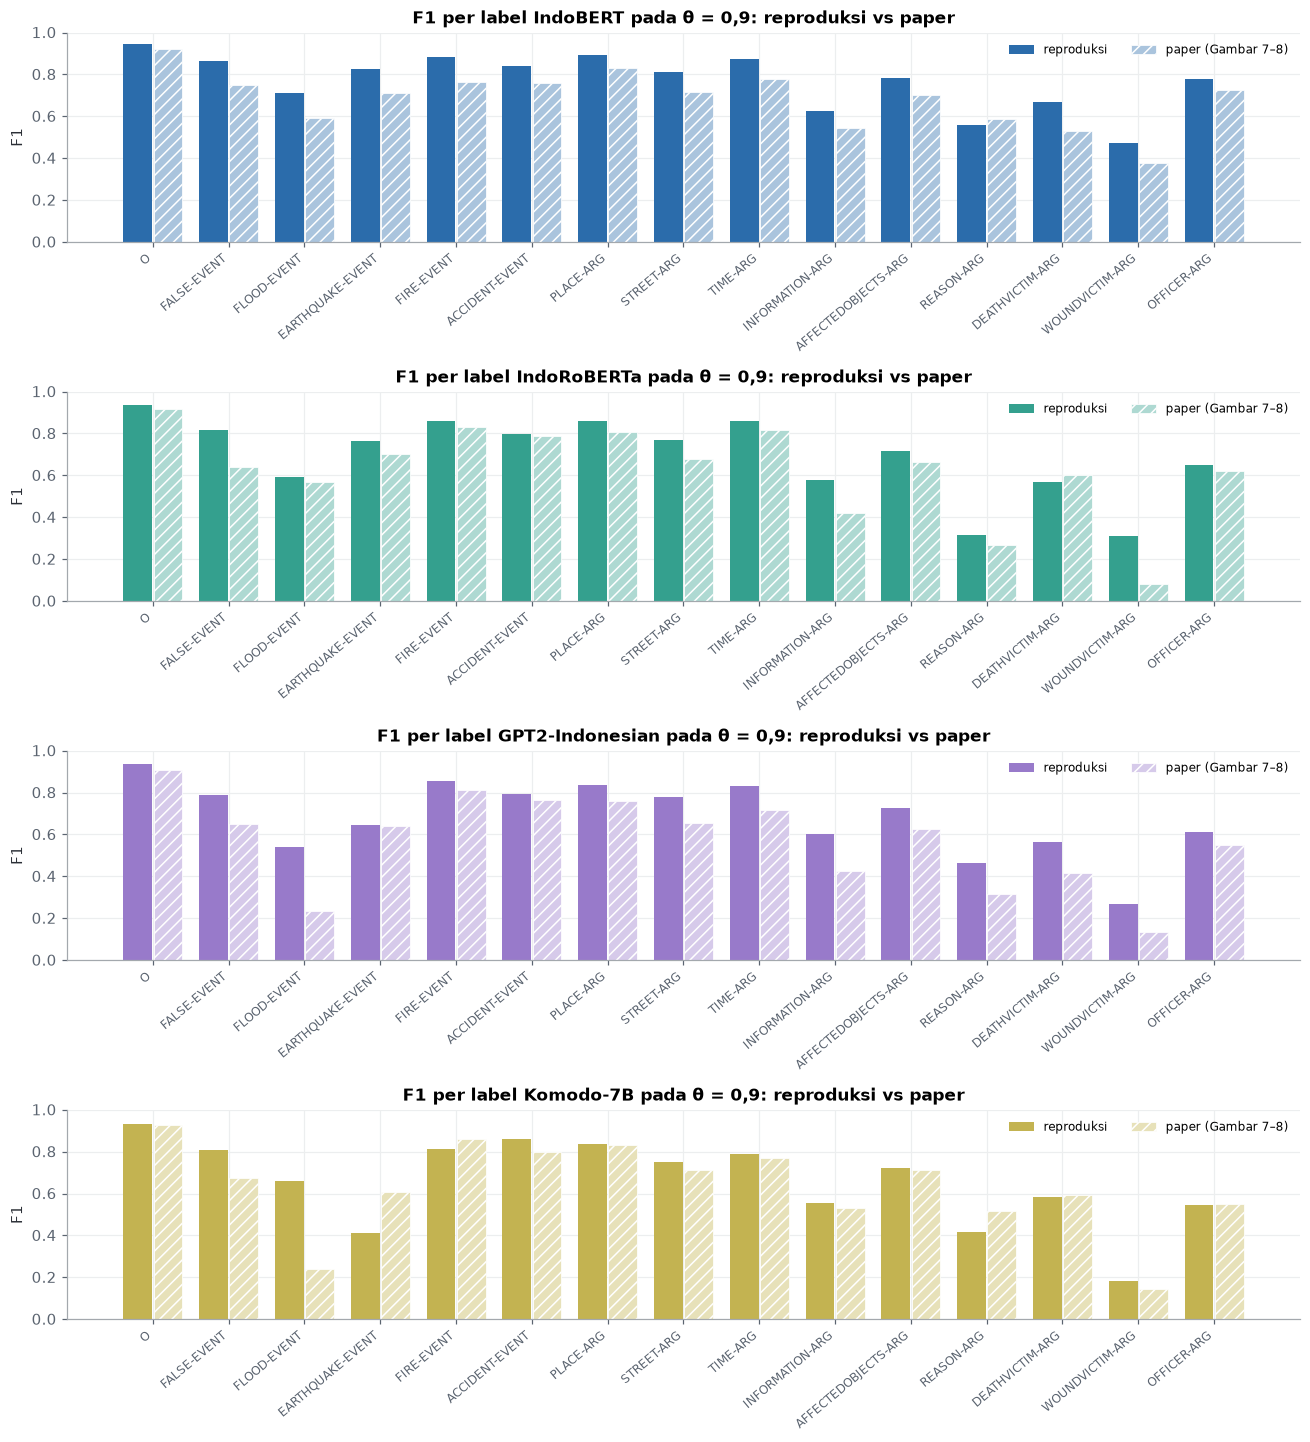

In [70]:
PAPER_F78 = {
    "IndoBERT": {
        "O": (0.855, 0.898, 0.922), "FALSE-EVENT": (0.534, 0.685, 0.750), "EARTHQUAKE-EVENT": (0.679, 0.679, 0.710),
        "ACCIDENT-EVENT": (0.480, 0.732, 0.760), "REASON-ARG": (0.385, 0.560, 0.588), "DEATHVICTIM-ARG": (0.160, 0.432, 0.530),
        "AFFECTEDOBJECTS-ARG": (0.334, 0.559, 0.702), "OFFICER-ARG": (0.454, 0.694, 0.724), "TIME-ARG": (0.429, 0.753, 0.778),
        "FIRE-EVENT": (0.081, 0.576, 0.763), "PLACE-ARG": (0.495, 0.713, 0.830), "FLOOD-EVENT": (0.416, 0.555, 0.593),
        "INFORMATION-ARG": (0.444, 0.510, 0.546), "WOUNDVICTIM-ARG": (0.310, 0.342, 0.377), "STREET-ARG": (0.405, 0.591, 0.717)},
    "IndoRoBERTa": {
        "O": (0.871, 0.879, 0.916), "FALSE-EVENT": (0.589, 0.576, 0.641), "EARTHQUAKE-EVENT": (0.411, 0.519, 0.701),
        "ACCIDENT-EVENT": (0.531, 0.576, 0.786), "REASON-ARG": (0.114, 0.156, 0.266), "DEATHVICTIM-ARG": (0.318, 0.305, 0.603),
        "AFFECTEDOBJECTS-ARG": (0.478, 0.515, 0.666), "OFFICER-ARG": (0.580, 0.571, 0.620), "TIME-ARG": (0.556, 0.688, 0.817),
        "FIRE-EVENT": (0.547, 0.637, 0.829), "PLACE-ARG": (0.609, 0.651, 0.807), "FLOOD-EVENT": (0.422, 0.404, 0.566),
        "INFORMATION-ARG": (0.320, 0.272, 0.418), "WOUNDVICTIM-ARG": (0.000, 0.019, 0.083), "STREET-ARG": (0.420, 0.596, 0.679)},
    "GPT2-Indonesian": {
        "O": (0.870, 0.893, 0.910), "FALSE-EVENT": (0.415, 0.591, 0.652), "EARTHQUAKE-EVENT": (0.299, 0.327, 0.639),
        "ACCIDENT-EVENT": (0.616, 0.661, 0.766), "REASON-ARG": (0.180, 0.361, 0.316), "DEATHVICTIM-ARG": (0.318, 0.445, 0.418),
        "AFFECTEDOBJECTS-ARG": (0.494, 0.639, 0.627), "OFFICER-ARG": (0.412, 0.510, 0.549), "TIME-ARG": (0.492, 0.635, 0.719),
        "FIRE-EVENT": (0.533, 0.816, 0.814), "PLACE-ARG": (0.641, 0.727, 0.758), "FLOOD-EVENT": (0.253, 0.528, 0.236),
        "INFORMATION-ARG": (0.446, 0.432, 0.426), "WOUNDVICTIM-ARG": (0.021, 0.109, 0.133), "STREET-ARG": (0.566, 0.623, 0.654)},
    "Komodo-7B": {
        "O": (0.863, 0.921, 0.926), "FALSE-EVENT": (0.417, 0.749, 0.673), "EARTHQUAKE-EVENT": (0.218, 0.461, 0.608),
        "ACCIDENT-EVENT": (0.393, 0.689, 0.799), "REASON-ARG": (0.185, 0.534, 0.515), "DEATHVICTIM-ARG": (0.139, 0.541, 0.595),
        "AFFECTEDOBJECTS-ARG": (0.509, 0.714, 0.710), "OFFICER-ARG": (0.310, 0.539, 0.548), "TIME-ARG": (0.379, 0.780, 0.770),
        "FIRE-EVENT": (0.750, 0.843, 0.859), "PLACE-ARG": (0.629, 0.833, 0.833), "FLOOD-EVENT": (0.194, 0.275, 0.238),
        "INFORMATION-ARG": (0.307, 0.550, 0.529), "WOUNDVICTIM-ARG": (0.000, 0.095, 0.142), "STREET-ARG": (0.534, 0.727, 0.711)},
}
TH_IDX = {0.7: 0, 0.8: 1, 0.9: 2}
LABEL_ORDER = ["O", "FALSE-EVENT", "FLOOD-EVENT", "EARTHQUAKE-EVENT", "FIRE-EVENT", "ACCIDENT-EVENT", "PLACE-ARG", "STREET-ARG",
               "TIME-ARG", "INFORMATION-ARG", "AFFECTEDOBJECTS-ARG", "REASON-ARG", "DEATHVICTIM-ARG", "WOUNDVICTIM-ARG", "OFFICER-ARG"]

CMP_LABEL = {}
for fam, per in PAPER_F78.items():
    cols = {}
    for th in PAPER_TH:
        r = RES.get(f"{fam} | self-training θ={th}")
        rep = r["metrics"].get("f1_per_label") if r else None
        pap = pd.Series({l: per[l][TH_IDX[th]] for l in LABEL_ORDER})
        cols[(f"θ = {fth(th)}", "paper")] = pap
        if rep:
            rep_s = pd.Series({l: rep.get(l, np.nan) for l in LABEL_ORDER})
            cols[(f"θ = {fth(th)}", "reproduksi")] = rep_s
            cols[(f"θ = {fth(th)}", "selisih")] = rep_s - pap
    tbl = pd.DataFrame(cols)
    tbl.columns = pd.MultiIndex.from_tuples(tbl.columns)
    CMP_LABEL[fam] = tbl
    tbl.to_csv(os.path.join(OUT_DIR, f"perbandingan_f1_per_label_{slug(fam)}.csv"))

fam_run = [f for f in PAPER_F78 if any(c[1] == "reproduksi" for c in CMP_LABEL[f].columns)]
if fam_run:
    for fam in fam_run:
        tbl = CMP_LABEL[fam]
        display(Markdown(f"**{fam}** — F1 per label, reproduksi vs paper"))
        display(tbl.style.format("{:.3f}", na_rep="–")
                .map(lambda v: "" if pd.isna(v) else ("color: #2a7d6f" if v >= 0 else "color: #a1453a"),
                     subset=[c for c in tbl.columns if c[1] == "selisih"]))
    fig, axs = plt.subplots(len(fam_run), 1, figsize=(12, 3.3 * len(fam_run)), squeeze=False)
    for a, fam in zip(axs[:, 0], fam_run):
        th = 0.9 if (f"θ = {fth(0.9)}", "reproduksi") in CMP_LABEL[fam].columns else max(
            t for t in PAPER_TH if (f"θ = {fth(t)}", "reproduksi") in CMP_LABEL[fam].columns)
        t = CMP_LABEL[fam][f"θ = {fth(th)}"]
        x = np.arange(len(LABEL_ORDER))
        a.bar(x - 0.2, t["reproduksi"].values, width=0.38, color=MODEL_COLORS[fam], label="reproduksi")
        a.bar(x + 0.2, t["paper"].values, width=0.38, color=tint(MODEL_COLORS[fam], 0.6), hatch="///",
              edgecolor="white", linewidth=0.5, label="paper (Gambar 7–8)")
        a.set_xticks(x)
        a.set_xticklabels(LABEL_ORDER, rotation=40, ha="right", fontsize=8)
        a.set_ylim(0, 1)
        a.set_ylabel("F1")
        a.set_title(f"F1 per label {fam} pada θ = {fth(th)}: reproduksi vs paper")
        a.legend(fontsize=8, ncol=2, loc="upper right")
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, "figures", "f1_per_label_vs_paper.png"), dpi=150)
    plt.show()
else:
    print("Model transformer belum dilatih pada sesi ini; tabel berikut berisi F1 per label paper pada θ = 0,9 sebagai acuan.")
    display(pd.DataFrame({fam: {l: PAPER_F78[fam][l][2] for l in LABEL_ORDER} for fam in PAPER_F78}).style.format("{:.3f}"))

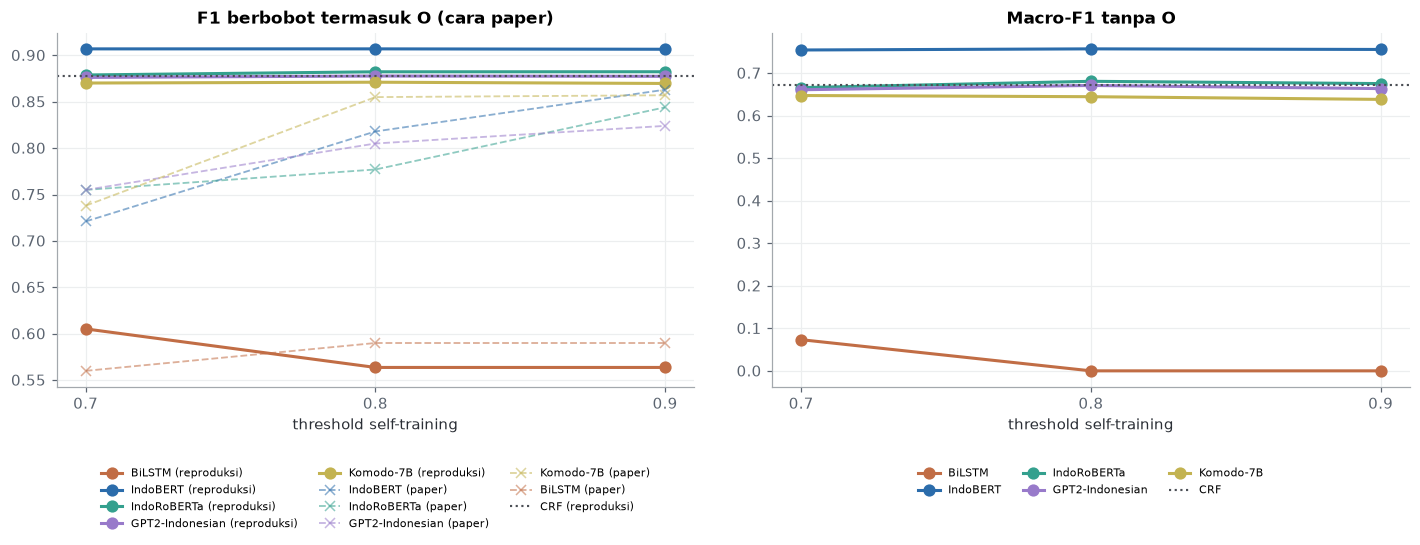

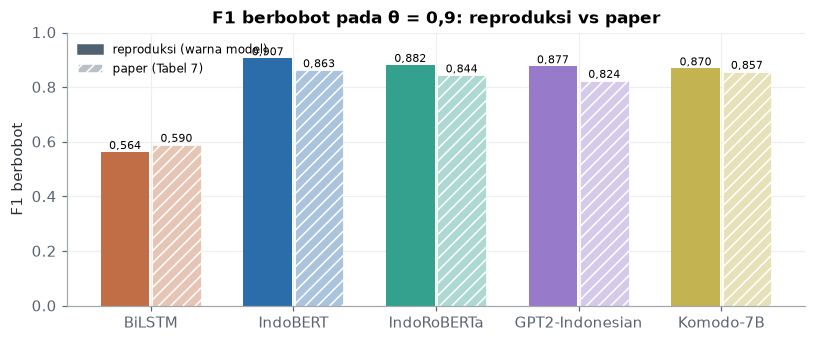

In [71]:
fams = [f for f in ["BiLSTM", "IndoBERT", "IndoRoBERTa", "GPT2-Indonesian", "Komodo-7B"] if any(RES[k]["family"] == f for k in RES)]
fig, ax = plt.subplots(1, 2, figsize=(13, 5.2))
for f in fams:
    pts = sorted((RES[k]["threshold"], RES[k]["metrics"]) for k in RES if RES[k]["family"] == f and RES[k].get("threshold"))
    if pts:
        ax[0].plot([p[0] for p in pts], [p[1]["f1_w"] for p in pts], "o-", lw=2, ms=7, color=MODEL_COLORS[f], label=f"{f} (reproduksi)")
        ax[1].plot([p[0] for p in pts], [p[1]["f1_macro_noO"] for p in pts], "o-", lw=2, ms=7, color=MODEL_COLORS[f], label=f)
for f, v in PAPER_T7.items():
    ax[0].plot(list(v), [x[3] for x in v.values()], "x--", lw=1.2, ms=6, color=MODEL_COLORS[f], alpha=0.55, label=f"{f} (paper)")
crf_r = RES.get("CRF")
if crf_r:
    ax[0].axhline(crf_r["metrics"]["f1_w"], color=MODEL_COLORS["CRF"], ls=":", lw=1.4, label="CRF (reproduksi)")
    ax[1].axhline(crf_r["metrics"]["f1_macro_noO"], color=MODEL_COLORS["CRF"], ls=":", lw=1.4, label="CRF")
    ax[0].set_ylim(top=max(ax[0].get_ylim()[1], crf_r["metrics"]["f1_w"] + 0.02))
    ax[1].set_ylim(top=max(ax[1].get_ylim()[1], crf_r["metrics"]["f1_macro_noO"] + 0.03))
ax[0].set_title("F1 berbobot termasuk O (cara paper)")
ax[1].set_title("Macro-F1 tanpa O")
for a in ax:
    a.set_xlabel("threshold self-training")
    a.set_xticks([0.7, 0.8, 0.9])
ax[0].legend(fontsize=7, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.2))
ax[1].legend(fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "figures", "f1_vs_threshold.png"), dpi=150, bbox_inches="tight")
plt.show()

cmp_rows = [(f, RES[f"{f} | self-training θ=0.9"]["metrics"]["f1_w"], PAPER_T7[f][0.9][3])
            for f in fams if f"{f} | self-training θ=0.9" in RES]
if cmp_rows:
    fig, ax = plt.subplots(figsize=(7.5, 3.2))
    x = np.arange(len(cmp_rows))
    ax.bar(x - 0.18, [c[1] for c in cmp_rows], width=0.34, color=[MODEL_COLORS[c[0]] for c in cmp_rows], label="reproduksi")
    ax.bar(x + 0.18, [c[2] for c in cmp_rows], width=0.34, color=[tint(MODEL_COLORS[c[0]], 0.6) for c in cmp_rows],
           hatch="///", edgecolor="white", linewidth=0.5, label="paper (Tabel 7)")
    for xi, c in zip(x, cmp_rows):
        ax.text(xi - 0.18, c[1] + 0.01, fmt(c[1]), ha="center", fontsize=7.5)
        ax.text(xi + 0.18, c[2] + 0.01, fmt(c[2]), ha="center", fontsize=7.5)
    ax.set_xticks(x)
    ax.set_xticklabels([c[0] for c in cmp_rows])
    ax.set_ylim(0, 1)
    ax.set_ylabel("F1 berbobot")
    ax.set_title("F1 berbobot pada θ = 0,9: reproduksi vs paper")
    ax.legend(handles=[Patch(color=C_SLATE, label="reproduksi (warna model)"),
                       Patch(facecolor=tint(C_SLATE, 0.6), hatch="///", edgecolor="white", label="paper (Tabel 7)")], fontsize=8)
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, "figures", "reproduksi_vs_paper.png"), dpi=150)
    plt.show()

### 10.2 Ablasi self-training dan kurva loss

,iterasi,pseudo-label diterima,F1 berbobot,Δ F1 berbobot,Δ macro-F1 tanpa O,Δ F1 FLOOD-EVENT
model,,,,,,
BiLSTM | self-training θ=0.9,1,0,0.564,0.000,0.000,0.000
BiLSTM | self-training θ=0.8,1,0,0.564,0.000,0.000,0.000
BiLSTM | self-training θ=0.7,6,5847,0.605,0.042,0.073,0.000
IndoBERT | self-training θ=0.9,9,5850,0.907,0.003,0.017,-0.003
IndoBERT | self-training θ=0.8,4,5850,0.907,0.004,0.019,0.039
IndoBERT | self-training θ=0.7,2,5850,0.907,0.004,0.016,0.020
IndoRoBERTa | self-training θ=0.9,14,5850,0.882,0.005,0.010,0.010
IndoRoBERTa | self-training θ=0.8,8,5849,0.882,0.005,0.015,0.074
IndoRoBERTa | self-training θ=0.7,2,5850,0.879,0.002,0.000,-0.009


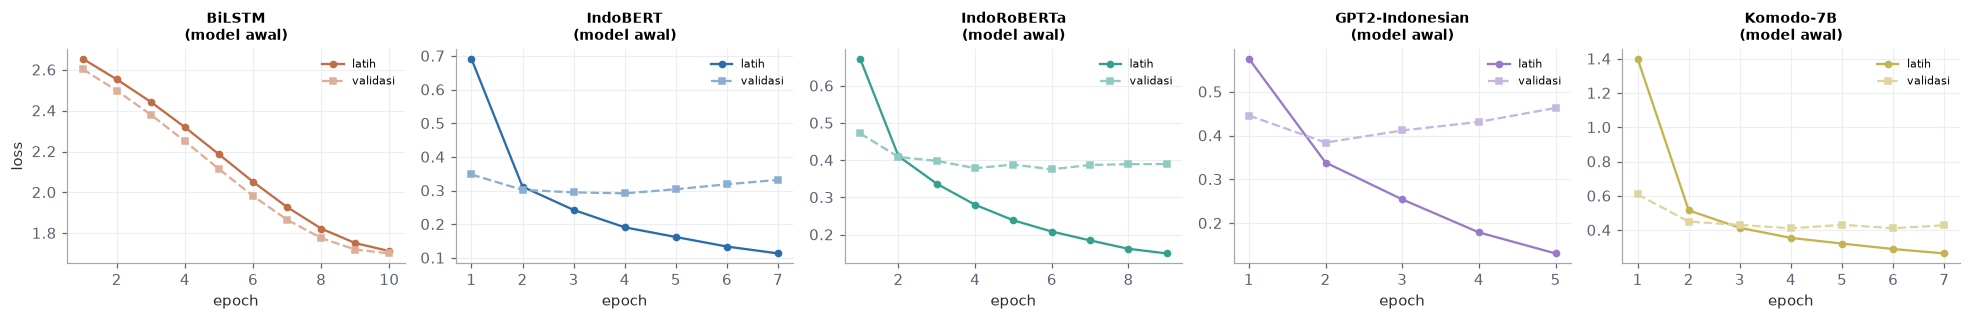

In [72]:
rows = []
for k in main_keys:
    r = RES[k]
    if r.get("st_log"):
        base = RES.get(f"{r['family']} | tanpa self-training")
        rows.append({"model": k, "iterasi": len(r["st_log"]), "pseudo-label diterima": sum(e["diterima"] for e in r["st_log"]),
                     "F1 berbobot": r["metrics"]["f1_w"],
                     "Δ F1 berbobot": r["metrics"]["f1_w"] - base["metrics"]["f1_w"] if base else np.nan,
                     "Δ macro-F1 tanpa O": r["metrics"]["f1_macro_noO"] - base["metrics"]["f1_macro_noO"] if base else np.nan,
                     "Δ F1 FLOOD-EVENT": r["metrics"]["f1_FLOOD"] - base["metrics"]["f1_FLOOD"] if base else np.nan})
if rows:
    ablation = pd.DataFrame(rows).set_index("model")
    display(ablation.style.format("{:.3f}", subset=["F1 berbobot", "Δ F1 berbobot", "Δ macro-F1 tanpa O", "Δ F1 FLOOD-EVENT"]))

with_hist = [k for k in main_keys if RES[k].get("hist")]
if with_hist:
    fig, axs = plt.subplots(1, len(with_hist), figsize=(3.6 * len(with_hist), 3.0), squeeze=False)
    for a, k in zip(axs[0], with_hist):
        h = pd.DataFrame(RES[k]["hist"])
        a.plot(h["epoch"], h["train_loss"], "o-", color=MODEL_COLORS.get(RES[k]["family"], C_SLATE), ms=4, label="latih")
        a.plot(h["epoch"], h["val_loss"], "s--", color=tint(MODEL_COLORS.get(RES[k]["family"], C_SLATE), 0.45), ms=4, label="validasi")
        a.set_title(k.replace(" | tanpa self-training", "\n(model awal)"), fontsize=9)
        a.set_xlabel("epoch")
        a.legend(fontsize=7)
    axs[0][0].set_ylabel("loss")
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, "figures", "kurva_loss.png"), dpi=150)
    plt.show()

<p style="text-align: justify;">
Ablasi membandingkan setiap ambang terhadap checkpoint awal yang sama.
</p>

<ul style="text-align: justify;">
<li><b>Ambang hampir tidak menyaring.</b> Pada IndoBERT, IndoRoBERTa, dan GPT2-Indonesian, 5.847–5.850 dari 5.850 tweet akhirnya diterima pada semua ambang; ambang hanya mengubah jumlah iterasi (IndoBERT 9/4/2, IndoRoBERTa 14/8/2, GPT2 17/6/3 untuk θ = 0,9/0,8/0,7). Hasil impor Komodo-7B hanya mencatat satu iterasi dengan 2.981/5.257/5.819 tweet.</li>
<li><b>Kenaikan F1 berbobot kecil.</b> Self-training menambah 0,002–0,008 pada semua transformer dan ambang, sedangkan paper melaporkan selisih besar antarambang (IndoBERT 0,721 → 0,863). Kenaikan macro-F1 tanpa O lebih terlihat pada IndoBERT (0,016–0,019).</li>
<li><b>F1 FLOOD-EVENT tidak konsisten.</b> Perubahannya −0,003 sampai +0,039 pada IndoBERT, −0,058 sampai −0,002 pada GPT2-Indonesian, dan +0,058 sampai +0,114 pada Komodo-7B. Self-training belum menyelesaikan ambiguitas kejadian nyata dan FALSE-EVENT.</li>
<li><b>BiLSTM (lr 2e-5).</b> θ = 0,9 dan 0,8 tidak menerima tweet; θ = 0,7 menerima 5.847 tweet dalam 6 iterasi dan menaikkan F1 berbobot 0,042 serta macro-F1 tanpa O 0,073.</li>
<li><b>Kurva loss model awal.</b> Loss validasi BiLSTM masih turun pada epoch 10 (belum konvergen). IndoBERT mencapai minimum pada epoch 4 dan GPT2-Indonesian pada epoch 2 sebelum naik kembali, sehingga early stopping mencegah pemakaian epoch yang overfit.</li>
</ul>


### 10.3 Analisis tambahan: pelatihan ulang BiLSTM

<p style="text-align: justify;">
<b>Mengapa dicoba.</b> Dengan hyperparameter Tabel 6 (AdamW, lr 2e-5), BiLSTM hanya menebak O (F1 berbobot 0,564, sama dengan baseline mayoritas), loss validasinya masih turun pada epoch ke-10, dan pada θ = 0,9 dan 0,8 tidak ada pseudo-label yang lolos (0 tweet) karena keyakinannya rendah. Learning rate 2e-5 lazim untuk fine-tuning Transformer, tetapi terlalu kecil untuk BiLSTM yang dilatih dari awal. BiLSTM karena itu dilatih ulang dengan Adam learning rate 1e-3 tanpa weight decay untuk menguji apakah lemahnya BiLSTM disebabkan arsitektur atau hyperparameter. Eksperimen diagnostik ini terpisah dari reproduksi.
</p>

In [73]:
def fit_bilstm_adam(model, items, desc="BiLSTM lr 1e-3"):
    return fit(model, items, collate_bilstm, amp=False, desc=desc, lr=1e-3, weight_decay=0.0)


run_family("BiLSTM (Adam lr 1e-3)", build_bilstm, fit_bilstm_adam, predict_bilstm, save_torch)
show_family("BiLSTM (Adam lr 1e-3)")
RES = load_results()

BiLSTM (Adam lr 1e-3) | tanpa self-training: hasil tersimpan digunakan.
BiLSTM (Adam lr 1e-3) | self-training θ=0.9: hasil tersimpan digunakan.
BiLSTM (Adam lr 1e-3) | self-training θ=0.8: hasil tersimpan digunakan.
BiLSTM (Adam lr 1e-3) | self-training θ=0.7: hasil tersimpan digunakan.


,accuracy,precision,recall,F1 berbobot,F1 paper,selisih vs paper,macro-F1 tanpa O,F1 span,pseudo-label,iterasi,waktu (menit)
setting,,,,,,,,,,,
self-training θ=0.9,0.875,0.869,0.875,0.868,–,–,0.656,0.632,5846,26,4.9
self-training θ=0.8,0.873,0.868,0.873,0.865,–,–,0.632,0.619,5847,13,1.6
self-training θ=0.7,0.872,0.865,0.872,0.863,–,–,0.623,0.612,5849,7,0.8
tanpa self-training,0.863,0.858,0.863,0.851,–,–,0.592,0.594,–,–,0.2


**BiLSTM (Adam lr 1e-3).** Model awal: F1 berbobot 0,851. Terbaik pada self-training θ = 0,9: F1 berbobot 0,868, macro-F1 tanpa O 0,656, F1 span 0,632; selisih terhadap model awal 0,017.

In [74]:
validasi_bilstm_adam = tampilkan_validasi_awal('BiLSTM (Adam lr 1e-3)')


,model,checkpoint,epoch,tweet validasi,token validasi,val accuracy,val precision berbobot,val recall berbobot,val F1 berbobot,val loss
0,BiLSTM (Adam lr 1e-3),"awal, tanpa self-training",9,630,14824,"0,8596","0,8505","0,8596","0,8487","0,4580"


Precision, recall, dan F1 dihitung per token dengan bobot jumlah token setiap label, termasuk O.
Kata yang terpotong: 0. Tidak ada pembaruan bobot model.


,konfigurasi,epoch checkpoint,loss validasi tersimpan,cakupan validasi
0,tanpa self-training,9,"0,4580",Validasi awal: data berlabel
1,self-training ambang 0.7,1,"0,1550",Validasi gabungan pada pelatihan terakhir
2,self-training ambang 0.8,1,"0,1234",Validasi gabungan pada pelatihan terakhir
3,self-training ambang 0.9,1,"0,0632",Validasi gabungan pada pelatihan terakhir


Untuk konfigurasi yang dilatih ulang, loss self-training berasal dari validasi gabungan pada pelatihan terakhir.


<ul style="text-align: justify;">
<li><b>Hasil.</b> F1 uji naik dari 0,564 menjadi 0,851 tanpa self-training dan 0,868 dengan self-training θ = 0,9; macro-F1 tanpa O naik dari 0,592 menjadi 0,656, dan F1 validasi model awal dari 0,5590 menjadi 0,8487.</li>
<li><b>Makna.</b> Selisih BiLSTM terhadap IndoBERT (0,907) menyusut dari 0,302 menjadi 0,039, dan BiLSTM kini mendekati CRF (0,878). Klaim paper bahwa Transformer jauh lebih unggul daripada BiLSTM sebagian besar disebabkan hyperparameter, bukan arsitektur.</li>
<li><b>Self-training.</b> Pada BiLSTM yang sudah belajar, self-training menambah 0,017 F1 berbobot, lebih besar daripada pada Transformer (0,003–0,008).</li>
<li><b>Batasan.</b> Learning rate dan weight decay berubah bersamaan, sehingga pengaruh keduanya belum terpisah.</li>
</ul>


In [75]:
def M(key):
    return RES[key]["metrics"] if key in RES else None


def best_st(fam):
    ks = [k for k in RES if RES[k]["family"] == fam and RES[k].get("threshold")]
    return max(ks, key=lambda k: RES[k]["metrics"]["f1_w"]) if ks else None


lines = []
maj, crf_m = M("Mayoritas (semua O)"), M("CRF")
lines.append(f"- **Baseline mayoritas:** F1 berbobot {fmt(maj['f1_w'])}, tetapi macro-F1 tanpa O dan F1 span bernilai 0; F1 berbobot tidak dapat dibaca sendirian.")
lines.append(f"- **CRF:** F1 berbobot {fmt(crf_m['f1_w'])}, macro-F1 tanpa O {fmt(crf_m['f1_macro_noO'])}, F1 span {fmt(crf_m['f1_span'])}, training {RES['CRF']['train_time_s']:.0f} detik.")
for fam in ["IndoBERT", "IndoRoBERTa", "GPT2-Indonesian", "Komodo-7B"]:
    kb = best_st(fam)
    if not kb:
        continue
    m, th = RES[kb]["metrics"], RES[kb]["threshold"]
    base = M(f"{fam} | tanpa self-training")
    ths = sorted(((RES[k]["threshold"], RES[k]["metrics"]["f1_w"]) for k in RES if RES[k]["family"] == fam and RES[k].get("threshold")), key=lambda x: -x[1])
    trend = " ≥ ".join(f"θ = {fth(t)} ({fmt(v)})" for t, v in ths)
    pv = PAPER_T7.get(fam, {}).get(th)
    ref = f" (paper {fmt(pv[3])})" if pv else ""
    txt = f"- **{fam}:** F1 berbobot terbaik {fmt(m['f1_w'])} pada θ = {fth(th)}{ref}; per ambang: {trend}."
    if base:
        txt += f" Selisih terhadap model awal ({fmt(base['f1_w'])}): F1 berbobot {fmt(m['f1_w'] - base['f1_w'])}, F1 FLOOD-EVENT {fmt(m['f1_FLOOD'] - base['f1_FLOOD'])}."
    txt += f" Selisih terhadap CRF: F1 berbobot {fmt(m['f1_w'] - crf_m['f1_w'])}, macro-F1 tanpa O {fmt(m['f1_macro_noO'] - crf_m['f1_macro_noO'])}."
    lines.append(txt)
fam_keys = lambda fam: sorted([k for k in RES if RES[k]["family"] == fam], key=lambda k: RES[k].get("threshold") or 0)
bl_keys, alt_keys = fam_keys("BiLSTM"), fam_keys("BiLSTM (Adam lr 1e-3)")
if bl_keys:
    fw_bl = [RES[k]["metrics"]["f1_w"] for k in bl_keys]
    fm_bl = [RES[k]["metrics"]["f1_macro_noO"] for k in bl_keys]
    st_parts, zero_th, pos_th = [], [], []
    for k in bl_keys:
        log = RES[k].get("st_log")
        if log:
            n_acc = sum(l["diterima"] for l in log)
            st_parts.append(f"θ = {fth(RES[k]['threshold'])}: " + f"{n_acc:,}".replace(",", ".") + f" tweet dalam {len(log)} iterasi")
            (pos_th if n_acc else zero_th).append((RES[k]["threshold"], log))
    b0 = M("BiLSTM | tanpa self-training")
    h0 = (RES.get("BiLSTM | tanpa self-training") or {}).get("hist") or []
    txt = (f"- **BiLSTM (hyperparameter Tabel 6):** model awal F1 berbobot {fmt(b0['f1_w'])} (baseline mayoritas {fmt(maj['f1_w'])}); "
           f"seluruh setting {fmt(min(fw_bl))}–{fmt(max(fw_bl))} (paper 0,56–0,59), macro-F1 tanpa O {fmt(min(fm_bl))}–{fmt(max(fm_bl))}.")
    if len(h0) >= 2 and h0[-1]["val_loss"] < h0[-2]["val_loss"]:
        txt += f" Loss validasi masih turun pada epoch ke-{len(h0)}; learning rate 2e-5 terlalu kecil untuk model yang dilatih dari awal."
    if st_parts:
        txt += " Pseudo-label diterima: " + "; ".join(st_parts) + "."
        if zero_th:
            txt += f" Pada θ = {' dan '.join(fth(t) for t, _ in zero_th)} tidak ada tweet yang lolos."
        late = [(t, lg) for t, lg in pos_th if lg[0]["diterima"] < 0.01 * N_UNLABELED]
        if late:
            txt += (f" Pada θ = {' dan '.join(fth(t) for t, _ in late)} hampir tidak ada tweet yang lolos di iterasi pertama, "
                    "sehingga kenaikan skor kemungkinan berasal dari tambahan epoch, bukan dari pseudo-label.")
    lines.append(txt)
if bl_keys and alt_keys:
    alt = best_st("BiLSTM (Adam lr 1e-3)") or alt_keys[0]
    lines.append(f"- **Learning rate BiLSTM:** dengan Adam 1e-3 tanpa weight decay, F1 berbobot {fmt(M('BiLSTM (Adam lr 1e-3) | tanpa self-training')['f1_w'])} tanpa self-training dan {fmt(RES[alt]['metrics']['f1_w'])} dengan self-training; keunggulan transformer atas BiLSTM pada paper perlu dibaca hati-hati.")
n_run = int((CMP_T7[("Status", "")] == "dijalankan").sum())
lines.append(f"- **Tabel 7:** {n_run} dari {len(CMP_T7)} kombinasi model–ambang sudah direproduksi."
             + (" Model transformer belum dilatih pada sesi ini." if not fam_run else ""))
for fam in fam_run:
    col = (f"θ = {fth(0.9)}", "selisih")
    if col in CMP_LABEL[fam].columns:
        d = CMP_LABEL[fam][col].drop("O").sort_values()
        lines.append(f"- **F1 per label {fam} (θ = 0,9) vs Gambar 7–8:** selisih rata-rata {fmt(d.mean())}; selisih terkecil "
                     + ", ".join(f"{l} ({fmt(v)})" for l, v in d.head(3).items())
                     + "; selisih terbesar " + ", ".join(f"{l} ({fmt(v)})" for l, v in d.tail(3)[::-1].items()) + ".")
display(Markdown("**Perbandingan antarmodel dan terhadap paper.**\n\n" + "\n".join(lines)))

**Perbandingan antarmodel dan terhadap paper.**

- **Baseline mayoritas:** F1 berbobot 0,564, tetapi macro-F1 tanpa O dan F1 span bernilai 0; F1 berbobot tidak dapat dibaca sendirian.
- **CRF:** F1 berbobot 0,878, macro-F1 tanpa O 0,672, F1 span 0,696, training 14 detik.
- **IndoBERT:** F1 berbobot terbaik 0,907 pada θ = 0,8 (paper 0,818); per ambang: θ = 0,8 (0,907) ≥ θ = 0,7 (0,907) ≥ θ = 0,9 (0,907). Selisih terhadap model awal (0,903): F1 berbobot 0,004, F1 FLOOD-EVENT 0,039. Selisih terhadap CRF: F1 berbobot 0,029, macro-F1 tanpa O 0,085.
- **IndoRoBERTa:** F1 berbobot terbaik 0,882 pada θ = 0,9 (paper 0,844); per ambang: θ = 0,9 (0,882) ≥ θ = 0,8 (0,882) ≥ θ = 0,7 (0,879). Selisih terhadap model awal (0,877): F1 berbobot 0,005, F1 FLOOD-EVENT 0,010. Selisih terhadap CRF: F1 berbobot 0,004, macro-F1 tanpa O 0,003.
- **GPT2-Indonesian:** F1 berbobot terbaik 0,878 pada θ = 0,8 (paper 0,805); per ambang: θ = 0,8 (0,878) ≥ θ = 0,9 (0,877) ≥ θ = 0,7 (0,876). Selisih terhadap model awal (0,870): F1 berbobot 0,008, F1 FLOOD-EVENT -0,002. Selisih terhadap CRF: F1 berbobot -0,000, macro-F1 tanpa O -0,001.
- **Komodo-7B:** F1 berbobot terbaik 0,871 pada θ = 0,8 (paper 0,855); per ambang: θ = 0,8 (0,871) ≥ θ = 0,7 (0,870) ≥ θ = 0,9 (0,870). Selisih terhadap model awal (0,868): F1 berbobot 0,003, F1 FLOOD-EVENT 0,082. Selisih terhadap CRF: F1 berbobot -0,007, macro-F1 tanpa O -0,027.
- **BiLSTM (hyperparameter Tabel 6):** model awal F1 berbobot 0,564 (baseline mayoritas 0,564); seluruh setting 0,564–0,605 (paper 0,56–0,59), macro-F1 tanpa O 0,000–0,073. Loss validasi masih turun pada epoch ke-10; learning rate 2e-5 terlalu kecil untuk model yang dilatih dari awal. Pseudo-label diterima: θ = 0,7: 5.847 tweet dalam 6 iterasi; θ = 0,8: 0 tweet dalam 1 iterasi; θ = 0,9: 0 tweet dalam 1 iterasi. Pada θ = 0,8 dan 0,9 tidak ada tweet yang lolos. Pada θ = 0,7 hampir tidak ada tweet yang lolos di iterasi pertama, sehingga kenaikan skor kemungkinan berasal dari tambahan epoch, bukan dari pseudo-label.
- **Learning rate BiLSTM:** dengan Adam 1e-3 tanpa weight decay, F1 berbobot 0,851 tanpa self-training dan 0,868 dengan self-training; keunggulan transformer atas BiLSTM pada paper perlu dibaca hati-hati.
- **Tabel 7:** 15 dari 15 kombinasi model–ambang sudah direproduksi.
- **F1 per label IndoBERT (θ = 0,9) vs Gambar 7–8:** selisih rata-rata 0,087; selisih terkecil REASON-ARG (-0,030), OFFICER-ARG (0,052), PLACE-ARG (0,061); selisih terbesar DEATHVICTIM-ARG (0,137), FIRE-EVENT (0,120), EARTHQUAKE-EVENT (0,118).
- **F1 per label IndoRoBERTa (θ = 0,9) vs Gambar 7–8:** selisih rata-rata 0,070; selisih terkecil DEATHVICTIM-ARG (-0,033), ACCIDENT-EVENT (0,011), FLOOD-EVENT (0,026); selisih terbesar WOUNDVICTIM-ARG (0,227), FALSE-EVENT (0,176), INFORMATION-ARG (0,159).
- **F1 per label GPT2-Indonesian (θ = 0,9) vs Gambar 7–8:** selisih rata-rata 0,113; selisih terkecil EARTHQUAKE-EVENT (0,005), ACCIDENT-EVENT (0,025), FIRE-EVENT (0,042); selisih terbesar FLOOD-EVENT (0,305), INFORMATION-ARG (0,176), REASON-ARG (0,146).
- **F1 per label Komodo-7B (θ = 0,9) vs Gambar 7–8:** selisih rata-rata 0,029; selisih terkecil EARTHQUAKE-EVENT (-0,197), REASON-ARG (-0,097), FIRE-EVENT (-0,046); selisih terbesar FLOOD-EVENT (0,422), FALSE-EVENT (0,134), ACCIDENT-EVENT (0,060).

<p style="text-align: justify;">
<b>Catatan tambahan.</b>
</p>

<ul style="text-align: justify;">
<li><b>Perbandingan dengan paper bersifat indikatif</b> karena tweet uji berbeda dan proporsi FLOOD-EVENT pada data uji reproduksi hanya sekitar separuh proporsi paper. Perbandingan yang adil adalah antarmodel pada pembagian data yang sama.</li>
<li><b>F1 per label paper dibaca dari grafik</b> (Gambar 7–8) dengan presisi tiga desimal karena paper tidak menyediakan tabelnya.</li>
<li><b>Loss validasi selama self-training</b> cenderung turun karena data validasi ikut berisi pseudo-label buatan model sendiri, sehingga tidak mencerminkan kualitas pada data uji (9.2).</li>
</ul>

<a id="bab-11"></a>
## 11. Interpretabilitas / Error Analysis

<p style="text-align: justify;">
Analisis CRF dan model neural terbaik membandingkan pertukaran label, contoh kesalahan, konsistensi status kejadian, dan keyakinan token untuk menilai penyaringan pseudo-label.
</p>


Model yang dianalisis: ['CRF', 'IndoBERT | self-training θ=0.8']


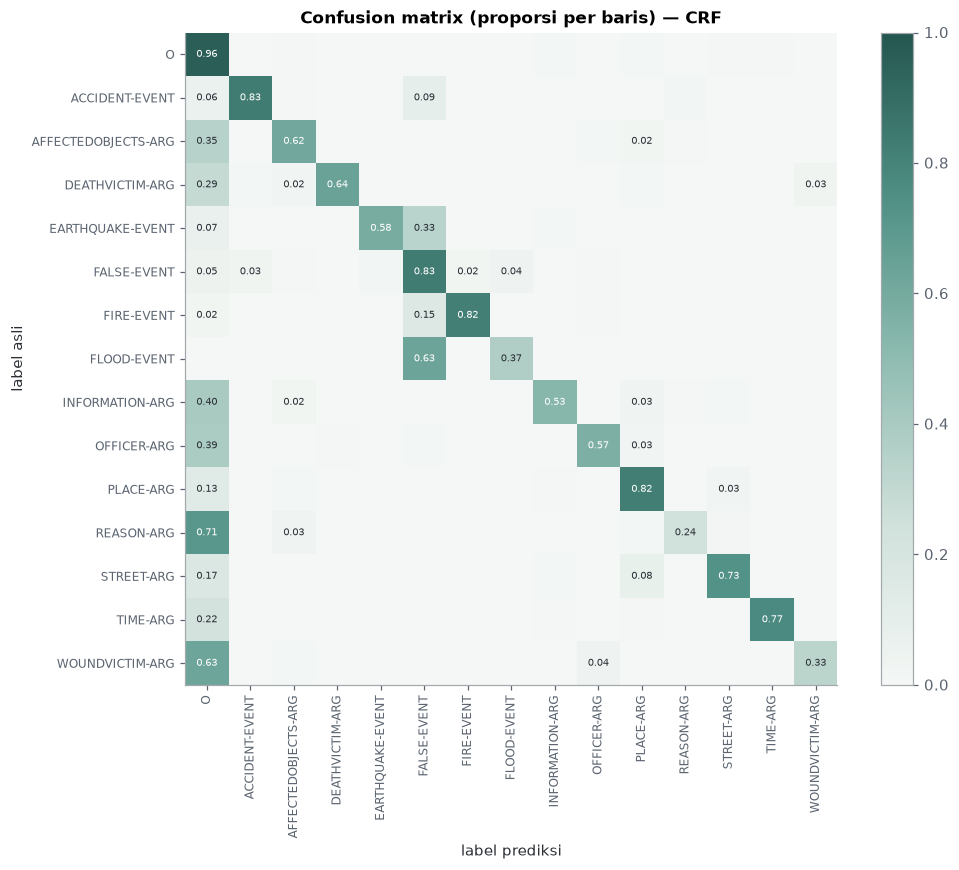

,precision,recall,F1,jumlah token
REASON-ARG,0.625,0.237,0.344,211
FLOOD-EVENT,0.485,0.368,0.418,87
WOUNDVICTIM-ARG,0.692,0.327,0.444,110
INFORMATION-ARG,0.642,0.531,0.581,580
AFFECTEDOBJECTS-ARG,0.729,0.616,0.668,625
OFFICER-ARG,0.811,0.569,0.669,476
EARTHQUAKE-EVENT,0.862,0.583,0.696,192
DEATHVICTIM-ARG,0.774,0.641,0.701,128
STREET-ARG,0.794,0.734,0.763,835
FALSE-EVENT,0.784,0.831,0.807,862


,label asli,diprediksi sebagai,jumlah token
0,PLACE-ARG,O,324
1,INFORMATION-ARG,O,232
2,AFFECTEDOBJECTS-ARG,O,216
3,OFFICER-ARG,O,185
4,O,PLACE-ARG,162
5,REASON-ARG,O,150
6,STREET-ARG,O,146
7,O,INFORMATION-ARG,141
8,TIME-ARG,O,132
9,O,AFFECTEDOBJECTS-ARG,90


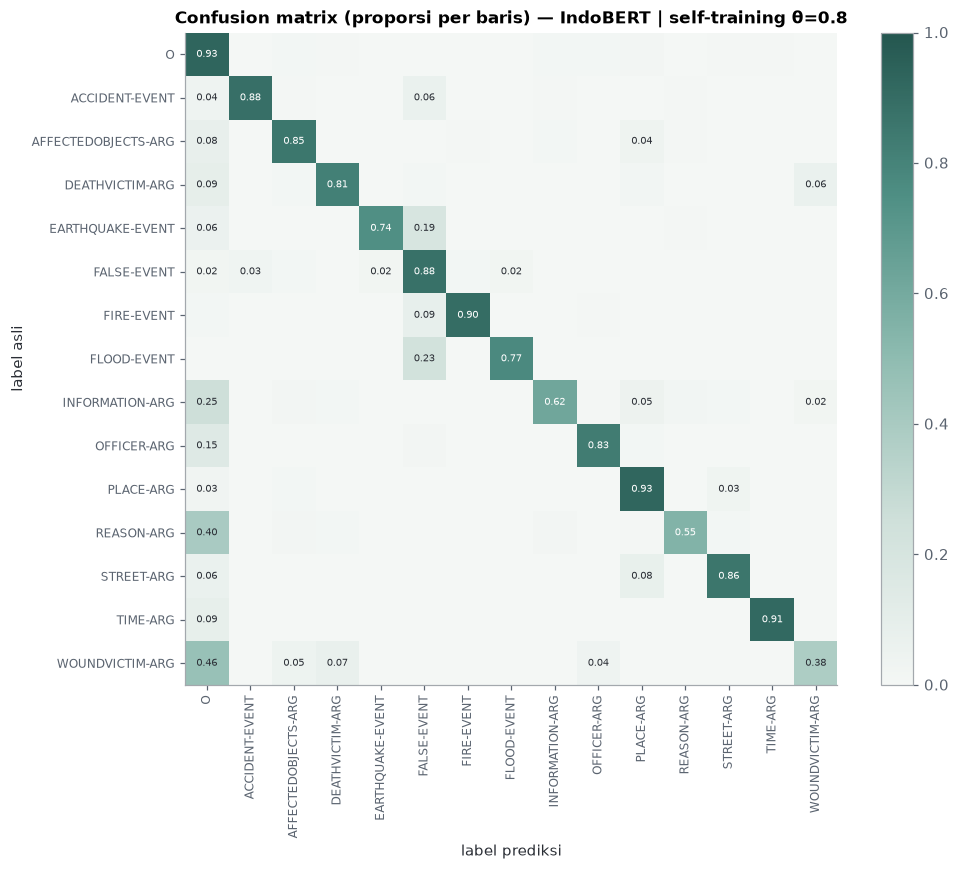

,precision,recall,F1,jumlah token
WOUNDVICTIM-ARG,0.592,0.382,0.464,110
REASON-ARG,0.614,0.550,0.580,211
INFORMATION-ARG,0.656,0.617,0.636,580
DEATHVICTIM-ARG,0.525,0.812,0.638,128
FLOOD-EVENT,0.736,0.770,0.753,87
OFFICER-ARG,0.719,0.830,0.771,476
AFFECTEDOBJECTS-ARG,0.723,0.853,0.783,625
EARTHQUAKE-EVENT,0.851,0.745,0.794,192
STREET-ARG,0.773,0.856,0.812,835
ACCIDENT-EVENT,0.784,0.884,0.831,189


,label asli,diprediksi sebagai,jumlah token
0,O,PLACE-ARG,240
1,O,INFORMATION-ARG,170
2,O,AFFECTEDOBJECTS-ARG,155
3,INFORMATION-ARG,O,145
4,O,OFFICER-ARG,135
5,O,STREET-ARG,120
6,O,TIME-ARG,88
7,REASON-ARG,O,84
8,PLACE-ARG,STREET-ARG,80
9,O,DEATHVICTIM-ARG,78


In [76]:
gold = [t["labels"] for t in test]
neural_keys = [k for k in RES if RES[k]["family"] in ("IndoBERT", "IndoRoBERTa", "GPT2-Indonesian", "Komodo-7B", "BiLSTM", "BiLSTM (Adam lr 1e-3)")]
ANALYSIS_KEYS = ["CRF"] + ([max(neural_keys, key=lambda k: RES[k]["metrics"]["f1_w"])] if neural_keys else [])
print("Model yang dianalisis:", ANALYSIS_KEYS)


def plot_confusion(key):
    pred = RES[key]["pred"]
    g_flat, p_flat = sum(gold, []), sum(pred, [])
    cm = confusion_matrix(g_flat, p_flat, labels=LABELS)
    cmn = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
    fig, ax = plt.subplots(figsize=(9.5, 8))
    im = ax.imshow(cmn, cmap=SEQ_CMAP, vmin=0, vmax=1)
    ax.set_xticks(range(len(LABELS)))
    ax.set_xticklabels(LABELS, rotation=90, fontsize=8)
    ax.set_yticks(range(len(LABELS)))
    ax.set_yticklabels(LABELS, fontsize=8)
    ax.grid(False)
    for i in range(len(LABELS)):
        for j in range(len(LABELS)):
            if cmn[i, j] >= 0.02:
                ax.text(j, i, f"{cmn[i, j]:.2f}", ha="center", va="center", fontsize=6.5, color="white" if cmn[i, j] > 0.5 else C_INK)
    ax.set_xlabel("label prediksi")
    ax.set_ylabel("label asli")
    ax.set_title(f"Confusion matrix (proporsi per baris) — {key}")
    plt.colorbar(im, fraction=0.04)
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, "figures", f"confusion_{slug(key)}.png"), dpi=150)
    plt.show()
    pr, rc, f1, sup = precision_recall_fscore_support(g_flat, p_flat, labels=LABELS, zero_division=0)
    per = pd.DataFrame({"precision": pr, "recall": rc, "F1": f1, "jumlah token": sup}, index=LABELS).sort_values("F1")
    display(per.round(3))
    pairs = [(LABELS[i], LABELS[j], int(cm[i, j])) for i in range(len(LABELS)) for j in range(len(LABELS)) if i != j]
    top = pd.DataFrame(sorted(pairs, key=lambda x: -x[2])[:10], columns=["label asli", "diprediksi sebagai", "jumlah token"])
    display(top)
    return per, top


ERR = {k: plot_confusion(k) for k in ANALYSIS_KEYS}

In [77]:
def show_errors(key, g_lab, p_lab, n=3):
    shown = 0
    for t, gp, pp in zip(test, gold, RES[key]["pred"]):
        hit = [i for i, (a, b) in enumerate(zip(gp, pp)) if a == g_lab and b == p_lab]
        if hit:
            words = [f"[{w}]" if i in hit else w for i, w in enumerate(t["tokens"])]
            print(f"  {t['text_id']}: " + " ".join(words)[:220])
            shown += 1
            if shown >= n:
                break
    if shown == 0:
        print("  (tidak ditemukan)")


for k in ANALYSIS_KEYS:
    print(f"\n================ {k} ================")
    for g_lab, p_lab in [("FLOOD-EVENT", "FALSE-EVENT"), ("FALSE-EVENT", "FLOOD-EVENT"), ("WOUNDVICTIM-ARG", "DEATHVICTIM-ARG"),
                         ("PLACE-ARG", "STREET-ARG"), ("AFFECTEDOBJECTS-ARG", "PLACE-ARG")]:
        print(f"\n{g_lab} diprediksi {p_lab} (kata dalam [ ] adalah kata yang salah):")
        show_errors(k, g_lab, p_lab)


================ CRF ================

FLOOD-EVENT diprediksi FALSE-EVENT (kata dalam [ ] adalah kata yang salah):
  BAN-01091: video [banjir] [bandang] di wonosoco undaan ( 4/12 ) tidak ada korban jiwa sudah ditangani petugas gabungan sumber : ig
  BAN-00158: waduh ! tinjau lokasi [banjir] di jaktim teriakan wanita ini bikin anies ngacir
  BAN-01104: habis diguncang gempa 5 3 sr pada 6/12/2018 pagi sorenya diterjang [banjir] di kecamatan kempo kabupaten dompu ntb 9 rumah rusak dan 120 rumah terendam [banjir] hutan makin rusak saat [banjir] sungai berisi kayu & sampah

FALSE-EVENT diprediksi FLOOD-EVENT (kata dalam [ ] adalah kata yang salah):
  BAN-01123: [banjir] di jakarta ternyata telah terjadi sejak zaman belanda tercatat beberapa banjir besar terjadi pada tahun 1621 1654 1876 dan 1932 bahkan setelah indonesia merdeka yaitu pada tahun 1976 1984 1994 1996 1997 1999 200
  BAN-01193: banjir ? [banjir] air kok di salahkan ? kan air hanya mengikuti sunah allah
  BAN-01623: dahlan tinj

In [78]:
def ada_bertentangan(labels):
    s_ = set(labels)
    return bool(s_ & REAL_EVENTS) and "FALSE-EVENT" in s_


g_conf = sum(ada_bertentangan(x) for x in gold)
CONSIST = {}
for k in ANALYSIS_KEYS:
    pred = RES[k]["pred"]
    r2f = sum(1 for gp, pp in zip(gold, pred) for a, b in zip(gp, pp) if a in REAL_EVENTS and b == "FALSE-EVENT")
    f2r = sum(1 for gp, pp in zip(gold, pred) for a, b in zip(gp, pp) if a == "FALSE-EVENT" and b in REAL_EVENTS)
    n_real = sum(1 for gp in gold for a in gp if a in REAL_EVENTS)
    n_false = sum(1 for gp in gold for a in gp if a == "FALSE-EVENT")
    CONSIST[k] = {"token kejadian nyata → FALSE-EVENT": r2f, "dari total token kejadian nyata": n_real,
                  "token FALSE-EVENT → kejadian nyata": f2r, "dari total token FALSE-EVENT": n_false,
                  "tweet dengan label kejadian bertentangan (prediksi)": sum(ada_bertentangan(x) for x in pred),
                  "tweet dengan label kejadian bertentangan (label asli)": g_conf}
display(pd.DataFrame(CONSIST))
for k in ANALYSIS_KEYS:
    print(f"\n{k}: contoh tweet yang prediksinya memuat label kejadian nyata dan FALSE-EVENT sekaligus")
    c = 0
    for t, gp, pp in zip(test, gold, RES[k]["pred"]):
        if ada_bertentangan(pp) and not ada_bertentangan(gp):
            print("  " + t["text_id"] + ": " + " ".join(f"{w}/{l}" if l in REAL_EVENTS or l == "FALSE-EVENT" else w
                                                        for w, l in zip(t["tokens"], pp))[:200])
            c += 1
            if c >= 3:
                break

,CRF,IndoBERT | self-training θ=0.8
token kejadian nyata → FALSE-EVENT,163,84
dari total token kejadian nyata,644,644
token FALSE-EVENT → kejadian nyata,93,73
dari total token FALSE-EVENT,862,862
tweet dengan label kejadian bertentangan (prediksi),38,20
tweet dengan label kejadian bertentangan (label asli),3,3



CRF: contoh tweet yang prediksinya memuat label kejadian nyata dan FALSE-EVENT sekaligus
  BAN-01123: banjir/FLOOD-EVENT di jakarta ternyata telah terjadi sejak zaman belanda tercatat beberapa banjir/FALSE-EVENT besar terjadi pada tahun 1621 1654 1876 dan 1932 bahkan setelah indonesia merdeka yaitu pa
  BAN-01104: habis diguncang gempa/EARTHQUAKE-EVENT 5 3 sr pada 6/12/2018 pagi sorenya diterjang banjir/FALSE-EVENT di kecamatan kempo kabupaten dompu ntb 9 rumah rusak dan 120 rumah terendam banjir/FALSE-EVENT hu
  BAN-01193: banjir/FALSE-EVENT ? banjir/FLOOD-EVENT air kok di salahkan ? kan air hanya mengikuti sunah allah

IndoBERT | self-training θ=0.8: contoh tweet yang prediksinya memuat label kejadian nyata dan FALSE-EVENT sekaligus
  BAN-01588: sati orang meninggal dunia dan satu luka akibat sepeda motor jatuh dan terseret banjir/FLOOD-EVENT di kabupaten semarang saat banjir/FALSE-EVENT seperti ini apalagi di jalan naik/turun jangan memaksak
  BAN-01100: usai didera hujan lebat emp

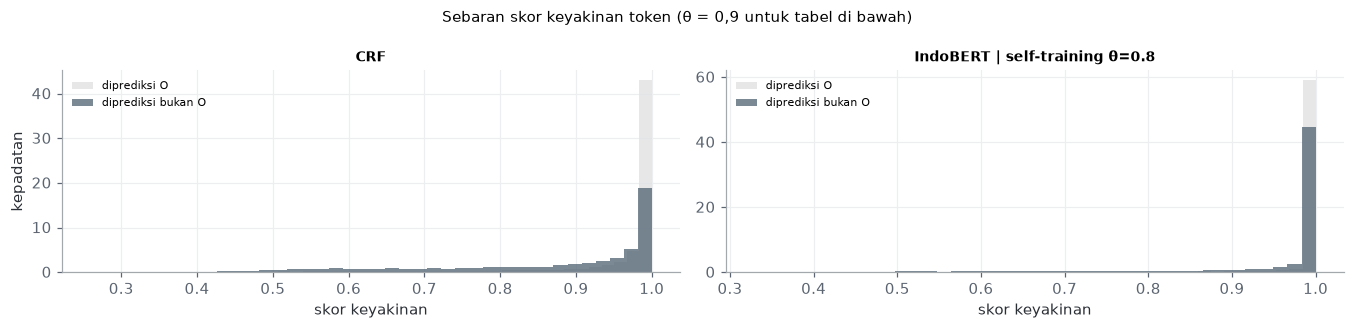

model,CRF,IndoBERT | self-training θ=0.8
keyakinan token O,0.957,0.988
keyakinan token bukan O,0.871,0.955
tweet lolos cara paper,753.000,969.000
lolos tetapi token penting < θ,362.000,116.000
salah token penting (lolos kedua cara),0.094,0.175
salah token penting (hanya lolos cara paper),0.229,0.363


In [79]:
T = 0.9
rows = []
fig, axs = plt.subplots(1, len(ANALYSIS_KEYS), figsize=(6.2 * len(ANALYSIS_KEYS), 3.0), squeeze=False)
for a, k in zip(axs[0], ANALYSIS_KEYS):
    pred, conf = RES[k]["pred"], RES[k]["conf"]
    recs, tok_o, tok_n = [], [], []
    for gp, pp, cf in zip(gold, pred, conf):
        if len(cf) != len(pp):
            continue
        non_o = [i for i, l in enumerate(pp) if l != "O"]
        tok_o += [cf[i] for i, l in enumerate(pp) if l == "O"]
        tok_n += [cf[i] for i in non_o]
        recs.append({"avg_semua": float(np.mean(cf)),
                     "avg_nonO": float(np.mean([cf[i] for i in non_o])) if non_o else np.nan,
                     "salah_nonO": float(np.mean([gp[i] != pp[i] for i in non_o])) if non_o else np.nan})
    cdf = pd.DataFrame(recs)
    lolos = cdf["avg_semua"] >= T
    dua = lolos & (cdf["avg_nonO"] >= T)
    hanya = lolos & ~(cdf["avg_nonO"] >= T)
    rows.append({"model": k, "keyakinan token O": np.mean(tok_o), "keyakinan token bukan O": np.mean(tok_n),
                 "tweet lolos cara paper": int(lolos.sum()), "lolos tetapi token penting < θ": int(hanya.sum()),
                 "salah token penting (lolos kedua cara)": cdf.loc[dua, "salah_nonO"].mean(),
                 "salah token penting (hanya lolos cara paper)": cdf.loc[hanya, "salah_nonO"].mean()})
    a.hist(tok_o, bins=40, alpha=0.8, density=True, color=C_O, label="diprediksi O")
    a.hist(tok_n, bins=40, alpha=0.75, density=True, color=C_SLATE, label="diprediksi bukan O")
    a.set_xlabel("skor keyakinan")
    a.set_title(k, fontsize=9)
    a.legend(fontsize=7)
axs[0][0].set_ylabel("kepadatan")
plt.suptitle(f"Sebaran skor keyakinan token (θ = {fth(T)} untuk tabel di bawah)", fontsize=10)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "figures", "keyakinan_token.png"), dpi=150)
plt.show()
CONF = pd.DataFrame(rows).set_index("model")
display(CONF.round(3).T)

In [80]:
lines = []
for k in ANALYSIS_KEYS:
    per, top = ERR[k]
    low = per.drop("O").head(3)
    cs = CONSIST[k]
    c = CONF.loc[k]
    lines.append(
        f"- **{k}.** Kesalahan terbanyak: " + "; ".join(f"{r['label asli']} → {r['diprediksi sebagai']} ({r['jumlah token']} token)" for _, r in top.head(3).iterrows())
        + ". F1 terendah: " + ", ".join(f"{l} ({fmt(v)})" for l, v in low["F1"].items())
        + f". Kejadian nyata → FALSE-EVENT: {cs['token kejadian nyata → FALSE-EVENT']} dari {cs['dari total token kejadian nyata']} token; FALSE-EVENT → kejadian nyata: {cs['token FALSE-EVENT → kejadian nyata']} dari {cs['dari total token FALSE-EVENT']} token;"
        + f" tweet dengan kedua status: {cs['tweet dengan label kejadian bertentangan (prediksi)']} (label asli {cs['tweet dengan label kejadian bertentangan (label asli)']})."
        + f" Keyakinan rata-rata token O {fmt(c['keyakinan token O'])} vs bukan O {fmt(c['keyakinan token bukan O'])}."
        + f" Pada θ = 0,9, {int(c['lolos tetapi token penting < θ'])} dari {int(c['tweet lolos cara paper'])} tweet yang lolos cara paper memiliki keyakinan token penting < θ;"
        + f" kesalahan token penting pada tweet tersebut {fmt(c['salah token penting (hanya lolos cara paper)'])} vs {fmt(c['salah token penting (lolos kedua cara)'])} pada tweet yang lolos kedua cara."
    )
display(Markdown("**Pola kesalahan per model.**\n\n" + "\n".join(lines)))

**Pola kesalahan per model.**

- **CRF.** Kesalahan terbanyak: PLACE-ARG → O (324 token); INFORMATION-ARG → O (232 token); AFFECTEDOBJECTS-ARG → O (216 token). F1 terendah: REASON-ARG (0,344), FLOOD-EVENT (0,418), WOUNDVICTIM-ARG (0,444). Kejadian nyata → FALSE-EVENT: 163 dari 644 token; FALSE-EVENT → kejadian nyata: 93 dari 862 token; tweet dengan kedua status: 38 (label asli 3). Keyakinan rata-rata token O 0,957 vs bukan O 0,871. Pada θ = 0,9, 362 dari 753 tweet yang lolos cara paper memiliki keyakinan token penting < θ; kesalahan token penting pada tweet tersebut 0,229 vs 0,094 pada tweet yang lolos kedua cara.
- **IndoBERT | self-training θ=0.8.** Kesalahan terbanyak: O → PLACE-ARG (240 token); O → INFORMATION-ARG (170 token); O → AFFECTEDOBJECTS-ARG (155 token). F1 terendah: WOUNDVICTIM-ARG (0,464), REASON-ARG (0,580), INFORMATION-ARG (0,636). Kejadian nyata → FALSE-EVENT: 84 dari 644 token; FALSE-EVENT → kejadian nyata: 73 dari 862 token; tweet dengan kedua status: 20 (label asli 3). Keyakinan rata-rata token O 0,988 vs bukan O 0,955. Pada θ = 0,9, 116 dari 969 tweet yang lolos cara paper memiliki keyakinan token penting < θ; kesalahan token penting pada tweet tersebut 0,363 vs 0,175 pada tweet yang lolos kedua cara.

<p style="text-align: justify;">
<b>Pola kesalahan CRF dan IndoBERT.</b>
</p>

<ul style="text-align: justify;">
<li><b>FLOOD-EVENT dan FALSE-EVENT tertukar karena konteks.</b> CRF memprediksi “banjir bandang … tidak ada korban jiwa” (BAN-01091) sebagai FALSE-EVENT dan sejarah banjir Jakarta (BAN-01123) sebagai kejadian nyata. IndoBERT mengurangi pertukaran ini (84 token kejadian nyata menjadi FALSE-EVENT, dibanding 163 pada CRF), tetapi belum menghilangkannya; 20 tweet uji juga memperoleh kedua status sekaligus (label asli 3).</li>
<li><b>Arah kesalahan berbeda.</b> CRF paling sering melewatkan label peran (PLACE-ARG → O, 324 token), sedangkan IndoBERT lebih sering memberi label peran pada token O (O → PLACE-ARG, 240 token). Nama tempat juga tertukar antara PLACE-ARG, STREET-ARG, dan AFFECTEDOBJECTS-ARG, misalnya “tol ngawi-kertosono”.</li>
<li><b>Penyaringan cara paper meloloskan token penting yang ragu.</b> Rata-rata seluruh token dapat melewati θ karena token O sangat yakin (IndoBERT 0,988 vs 0,955 untuk token bukan O). Pada tweet seperti ini, kesalahan token penting lebih tinggi (CRF 22,9% vs 9,4%; IndoBERT 36,3% vs 17,5%), sesuai temuan bahwa keyakinan tinggi belum tentu benar [19], [20]. Temuan ini menjadi dasar Novelty 2.</li>
</ul>


<a id="bab-12"></a>
## 12. Biaya Komputasi

In [81]:
rows = []
for k in sorted(RES, key=sort_key):
    r = RES[k]
    if r["family"] == "Mayoritas":
        continue
    rows.append({"model": k, "parameter": r.get("params"), "waktu training total (menit)": r["train_time_s"] / 60,
                 "inferensi per 1.000 tweet (detik)": r["infer_s_per_1000"], "puncak memori GPU (GB)": r.get("peak_mem_gb"),
                 "device": r["device"]})
display(pd.DataFrame(rows).set_index("model").style.format(
    {"waktu training total (menit)": "{:.1f}", "inferensi per 1.000 tweet (detik)": "{:.2f}", "parameter": "{:,.0f}"}, na_rep="–"))

,parameter,waktu training total (menit),inferensi per 1.000 tweet (detik),puncak memori GPU (GB),device
model,,,,,
CRF,"54,983",0.2,0.50,0.010000,cuda
BiLSTM | tanpa self-training,"1,444,623",0.2,0.14,0.100000,cuda
BiLSTM | self-training θ=0.9,"1,444,623",0.0,0.12,0.090000,cuda
BiLSTM | self-training θ=0.8,"1,444,623",0.0,0.12,0.090000,cuda
BiLSTM | self-training θ=0.7,"1,444,623",1.8,0.10,0.100000,cuda
IndoBERT | tanpa self-training,"109,979,151",4.4,7.67,3.700000,cuda
IndoBERT | self-training θ=0.9,"109,979,151",60.1,5.71,3.700000,cuda
IndoBERT | self-training θ=0.8,"109,979,151",61.5,7.58,3.700000,cuda
IndoBERT | self-training θ=0.7,"109,979,151",18.5,7.65,3.700000,cuda


<p style="text-align: justify;">
Waktu self-training mencakup seluruh iterasi (prediksi data tanpa label dan pelatihan ulang); untuk CRF, kolom parameter berisi jumlah fitur state dan transisi. CRF hanya membutuhkan sekitar 0,2 menit, sedangkan self-training IndoBERT 18,5–61,5 menit dan Komodo-7B 191,7–281,5 menit.
</p>

<a id="bab-13"></a>
## 13. Model Final / Inferensi

<p style="text-align: justify;">
Model final memuat bobot dengan F1 berbobot tertinggi sesuai protokol notebook ini (dipilih dengan F1 uji; versi validasi di 9.2). Fungsi <code>ekstrak_informasi</code> mengubah tweet menjadi daftar frasa per label. Tiga contoh berikut dibuat di luar dataset.
</p>


In [82]:
cands = [k for k in RES if RES[k]["family"] not in ("Mayoritas", "Komodo-7B")]
final_key = max(cands, key=lambda k: RES[k]["metrics"]["f1_w"])
final_fam = RES[final_key]["family"]
print("Model final:", final_key)

if final_fam in TRANSFORMER_MODELS:
    path = os.path.join(OUT_DIR, "models", slug(final_fam) + "_best")
    _, _, final_predict, _ = tf_funcs(path)
    final_model = AutoModelForTokenClassification.from_pretrained(path).to(DEVICE)
elif final_fam.startswith("BiLSTM"):
    final_model = build_bilstm()
    final_model.load_state_dict(torch.load(os.path.join(OUT_DIR, "models", slug(final_fam) + "_best.pt"), map_location=DEVICE))
    final_predict = predict_bilstm
else:
    with open(os.path.join(OUT_DIR, "models", "CRF_best.pkl"), "rb") as f:
        final_model = pickle.load(f)
    final_predict = predict_crf


def ekstrak_informasi(teks):
    toks = simple_tokenize(teks)
    labs = final_predict(final_model, [{"tokens": toks}])[0][0]
    hasil = {}
    for a, b, lab in spans(labs):
        hasil.setdefault(lab, []).append(" ".join(toks[a:b]))
    return hasil


contoh_tweet = [
    "banjir setinggi 1 meter rendam puluhan rumah di kelurahan sewu solo sejak minggu malam 2 warga hanyut",
    "warga diimbau waspada potensi banjir rob di pesisir semarang selama sepekan ke depan",
    "kecelakaan beruntun di tol cipularang km 92 tadi pagi 3 orang luka-luka",
]
for tw in contoh_tweet:
    print(tw)
    print("  →", json.dumps(ekstrak_informasi(tw), ensure_ascii=False))

Model final: IndoBERT | self-training θ=0.8


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

banjir setinggi 1 meter rendam puluhan rumah di kelurahan sewu solo sejak minggu malam 2 warga hanyut
  → {"FLOOD-EVENT": ["banjir"], "INFORMATION-ARG": ["setinggi 1 meter"], "AFFECTEDOBJECTS-ARG": ["puluhan rumah"], "PLACE-ARG": ["kelurahan sewu solo"], "TIME-ARG": ["minggu"], "DEATHVICTIM-ARG": ["2 warga"]}
warga diimbau waspada potensi banjir rob di pesisir semarang selama sepekan ke depan
  → {"FLOOD-EVENT": ["banjir rob"], "PLACE-ARG": ["pesisir semarang"]}
kecelakaan beruntun di tol cipularang km 92 tadi pagi 3 orang luka-luka
  → {"ACCIDENT-EVENT": ["kecelakaan beruntun"], "STREET-ARG": ["tol cipularang km 92"], "WOUNDVICTIM-ARG": ["3 orang luka-luka"]}


<p style="text-align: justify;">
Model final (IndoBERT θ = 0,8) mengekstrak kejadian, lokasi, korban, dan objek terdampak pada tweet pertama dan ketiga. Tiga kesalahan berikut sejalan dengan Bab 11:
</p>

<ul style="text-align: justify;">
<li><b>Status kejadian.</b> Pada tweet kedua, “banjir rob” dalam kalimat imbauan diberi FLOOD-EVENT, padahal menurut definisi paper peringatan termasuk FALSE-EVENT. Kesalahan ini menjadi sasaran Novelty 1.</li>
<li><b>Jenis korban.</b> “2 warga” pada “2 warga hanyut” diberi DEATHVICTIM-ARG walaupun status korban tidak eksplisit, mirip pertukaran WOUNDVICTIM-ARG dan DEATHVICTIM-ARG pada paper.</li>
<li><b>Batas span.</b> TIME-ARG hanya mengambil “minggu” dari “sejak minggu malam”, sedangkan “tadi pagi” dan “selama sepekan ke depan” tidak terdeteksi.</li>
</ul>


<a id="bab-14"></a>
## 14. Pembahasan

### 14.1 Eksperimen Tambahan di Luar Paper

<p style="text-align: justify;">
Tiga eksperimen ditambahkan karena paper tidak menyediakan pembanding yang memadai untuk menilai klaimnya.
</p>

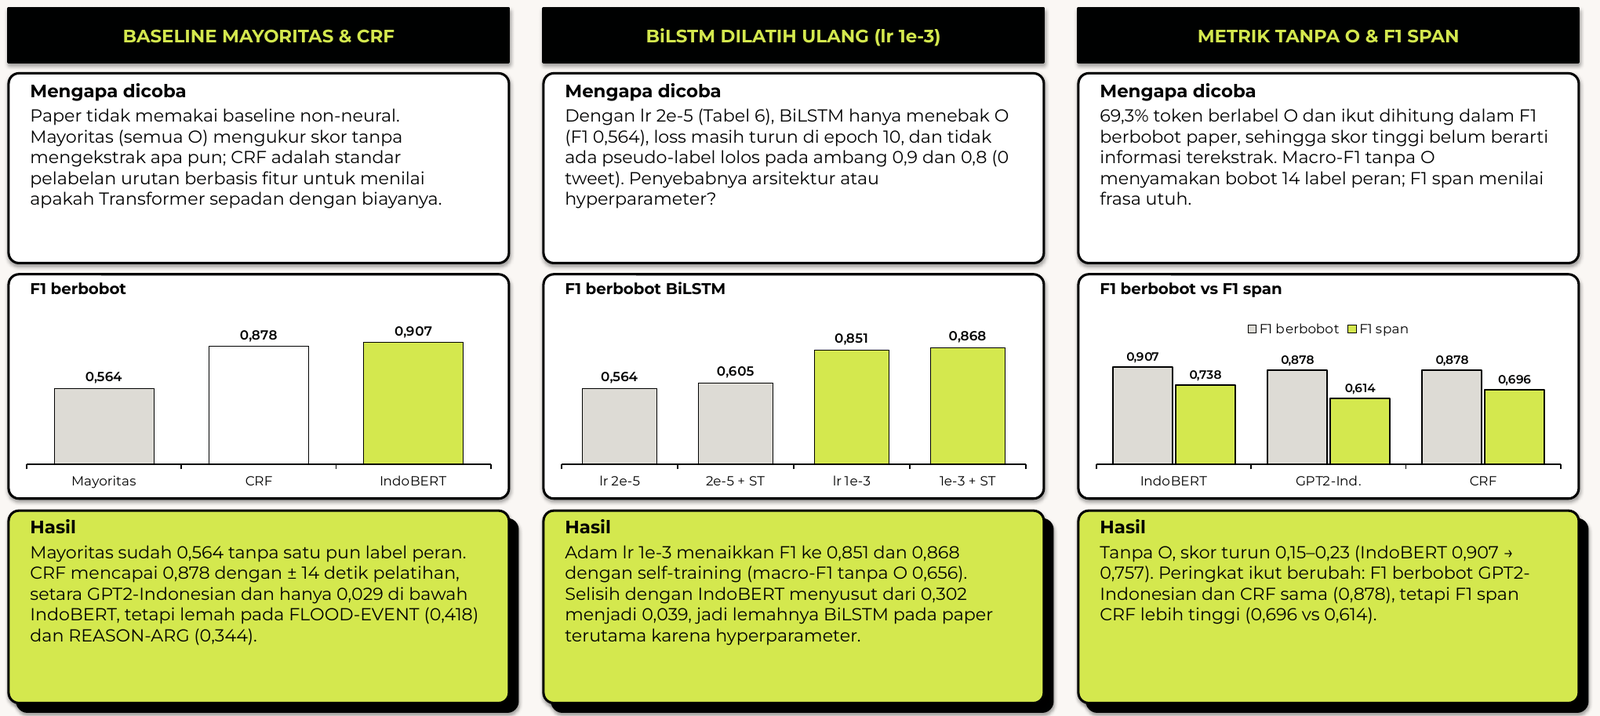

<p style="text-align: center;"><i>Gambar 14.1. Alasan dan hasil eksperimen tambahan.</i></p>

| Eksperimen | Mengapa dicoba | Hasil | Makna |
|---|---|---|---|
| Baseline mayoritas dan CRF (Bab 7) | Paper tanpa baseline non-neural; mengukur skor yang berasal dari label O dan keunggulan Transformer atas metode konvensional | Mayoritas 0,564 tanpa label peran; CRF 0,878 (± 14 detik), setara GPT2-Indonesian | Keunggulan Transformer pada F1 berbobot tipis (IndoBERT +0,029), tetapi jelas pada label berbasis konteks (macro-F1 tanpa O +0,085) |
| BiLSTM dilatih ulang dengan Adam lr 1e-3 (10.3) | Dengan lr 2e-5 BiLSTM hanya menebak O, belum konvergen, dan 0 pseudo-label lolos pada θ = 0,9 dan 0,8 | F1 0,851, dan 0,868 dengan self-training | Selisih dengan IndoBERT turun dari 0,302 menjadi 0,039; lemahnya BiLSTM pada paper terutama karena hyperparameter |
| Metrik tanpa O dan F1 span (9.1) | 69,3% token berlabel O dan ikut dihitung dalam F1 berbobot | Skor turun 0,15–0,23 tanpa O; F1 span CRF 0,696 vs GPT2-Indonesian 0,614 walaupun F1 berbobot keduanya 0,878 | Metrik ketat mengubah peringkat dan lebih mencerminkan informasi yang terekstrak |


### 14.2 Temuan Lain dan Trade-off

<p style="text-align: justify;">
<b>Temuan lain.</b>
</p>

<ul style="text-align: justify;">
<li>Tabel 5 paper memuat total yang tertukar (FALSE-EVENT dan STREET-ARG pada data uji).</li>
<li>Pernyataan paper bahwa lebih dari 90% token berlabel O tidak sesuai dengan data (69,3%).</li>
<li>Pada Tabel 7 paper, baris BiLSTM memiliki accuracy 0,95 tetapi recall 0,50–0,55, sedangkan pada baris transformer recall selalu sama dengan accuracy. Hal ini menunjukkan metrik BiLSTM di paper dihitung dengan cara yang berbeda, misalnya dengan menyertakan token padding.</li>
</ul>

<p style="text-align: justify;">
<b>Trade-off.</b>
</p>

<ul style="text-align: justify;">
<li>Threshold tinggi menghasilkan pseudo-label yang lebih bersih tetapi lebih sedikit dan membutuhkan lebih banyak iterasi; threshold rendah memasukkan hampir seluruh data sekaligus sehingga penyaringan nyaris tidak berfungsi.</li>
<li>CRF jauh lebih ringan dan cepat daripada transformer, sehingga keunggulan transformer perlu dinilai dari selisih kualitas terhadap biaya komputasinya (Bagian 12).</li>
<li>Satu hyperparameter yang sama untuk semua model, seperti dilakukan paper, memudahkan perbandingan tetapi dapat merugikan model yang dilatih dari awal seperti BiLSTM.</li>
</ul>

<a id="bab-15"></a>
## 15. Keterbatasan

<p style="text-align: justify;">
Keterbatasan mencakup pembagian sampel yang berbeda dari paper, rincian implementasi yang tidak lengkap, satu seed, dugaan kesalahan anotasi, dan tidak adanya uji lintas domain. Pemilihan model berdasarkan data uji dan validasi yang memuat pseudo-label sudah diperbaiki pada 9.2, tetapi protokol tersebut baru selesai untuk IndoBERT dan BiLSTM.
</p>


<a id="bab-16"></a>
## 16. Kesimpulan dan Rencana Checkpoint 2

### 16.1 Kesimpulan

<ol style="text-align: justify;">
<li><b>Reproduksi hasil paper.</b> Data dan split sesuai paper, tetapi anggota data uji berbeda (24.209 vs 22.908 token). IndoBERT tetap terbaik dengan F1 uji 0,907 (paper 0,863), juga saat dipilih melalui validasi (θ = 0,8, 9.2). Selisih dengan paper bersifat indikatif.</li>
<li><b>Kontribusi self-training.</b> Kecil: F1 berbobot Transformer naik 0,003–0,008 dan macro-F1 tanpa O IndoBERT 0,016–0,019. Ambang hampir tidak menyaring (± 5.850 tweet lolos di semua ambang), sehingga tren ambang paper (0,721 → 0,863) tidak terulang.</li>
<li><b>Metrik ketat dan baseline.</b> Tanpa O, skor turun 0,15–0,23. CRF (0,878) dan BiLSTM lr 1e-3 (0,868) mempersempit keunggulan Transformer. Kesalahan terpusat pada FLOOD-EVENT vs FALSE-EVENT, jenis korban, dan frasa panjang seperti REASON-ARG.</li>
<li><b>Laporan paper.</b> Total Tabel 5 tertukar, proporsi O 69,3% (bukan lebih dari 90%), dan metrik BiLSTM tidak konsisten antara accuracy dan recall.</li>
<li><b>Arah Checkpoint 2.</b> Temuan ini membentuk tiga research gap (16.2) dan dua novelty (16.3): joint tweet–token fact-aware SRL dan role-aware pseudo-label filtering, diuji dengan protokol perbaikan dan tiga seed.</li>
</ol>

<p style="text-align: justify;">
<b>Keterbatasan:</b> satu seed, protokol perbaikan baru diterapkan pada IndoBERT dan BiLSTM, data uji paper tidak identik, dan uji lintas domain berita belum direproduksi (Bab 15).
</p>

### 16.2 Research Gap

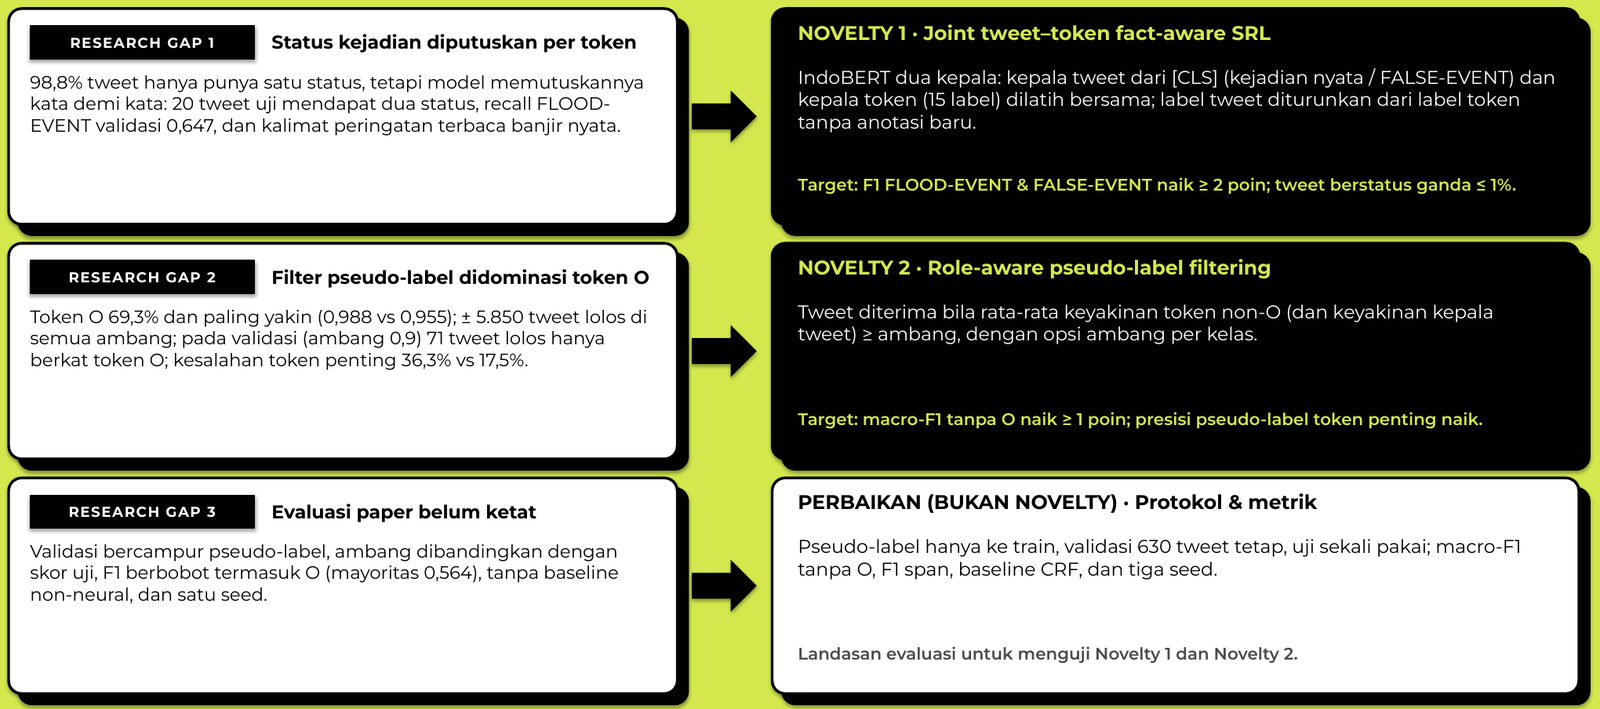

<p style="text-align: center;"><i>Gambar 16.1. Tiga research gap, dua novelty, dan satu perbaikan protokol.</i></p>

| Research gap | Bukti | Jawaban |
|---|---|---|
| **Gap 1. Status kejadian diputuskan per token** | 98,8% tweet hanya punya satu status, tetapi model memutuskannya kata demi kata: 20 tweet uji mendapat dua status (label asli 3), recall FLOOD-EVENT validasi 0,647, dan kalimat peringatan terbaca banjir nyata (Bab 11, 13) | Novelty 1 |
| **Gap 2. Filter pseudo-label didominasi token O** | Token O 69,3% dan paling yakin (0,988 vs 0,955); ± 5.850 tweet lolos di semua ambang; pada validasi (θ = 0,9) 71 tweet lolos hanya berkat token O; kesalahan token penting 36,3% vs 17,5% (Bab 11, 10.2) | Novelty 2 |
| **Gap 3. Evaluasi paper belum ketat** | Validasi bercampur pseudo-label, ambang dibandingkan dengan skor uji, F1 berbobot termasuk O (mayoritas 0,564), tanpa baseline non-neural, dan satu seed | Perbaikan protokol dan metrik (9.2), bukan novelty |

<p style="text-align: justify;">
Angka validasi (recall FLOOD-EVENT 0,647 dan 71 tweet) berasal dari notebook eksperimen perbaikan protokol (9.2).
</p>

### 16.3 Rencana Novelty Checkpoint 2

<ul style="text-align: justify;">
<li><b>Novelty 1 · Joint tweet–token fact-aware SRL.</b> IndoBERT dengan dua kepala: kepala tweet dari [CLS] (kejadian nyata / FALSE-EVENT) dan kepala token (15 label), dilatih bersama mengikuti pola intent–slot Chen dkk. [26]. Label tweet diturunkan dari label token tanpa anotasi baru; tweet campuran dan tweet tanpa label kejadian ditangani khusus. Target: F1 FLOOD-EVENT dan FALSE-EVENT naik ≥ 2 poin; tweet berstatus ganda ≤ 1%.</li>
<li><b>Novelty 2 · Role-aware pseudo-label filtering.</b> Tweet diterima bila rata-rata keyakinan token non-O (dan keyakinan kepala tweet) ≥ ambang, dengan opsi ambang per kelas seperti FlexMatch [31]. Target: macro-F1 tanpa O naik ≥ 1 poin dan presisi pseudo-label token penting naik.</li>
</ul>

<p style="text-align: justify;">
Pembandingnya adalah IndoBERT per token dan self-training cara paper, keduanya dengan protokol 9.2 (jawaban Gap 3). Evaluasi memakai tiga seed [23], F1 berbobot, macro-F1 tanpa O, F1 span, dan F1 per label. Uji kata isyarat dan subset sulit dipakai untuk memeriksa apakah model hanya mengandalkan pola kata permukaan [32].
</p>

<a id="bab-17"></a>
## 17. Referensi

<p style="text-align: justify;">
[1] A. D. P. Ariyanto, D. Purwitasari, C. Fatichah, S. D. Ravana, Andrian, dan A. A. Y. Parwata, "Transformer-Based Semantic Role Labeling for Crisis Events Using Semi-Supervised Learning on Low-Resource Language Twitter Texts," <i>IEEE Access</i>, vol. 13, 2025, doi: 10.1109/ACCESS.2025.3604068.<br>
[2] S. Vieweg, A. L. Hughes, K. Starbird, dan L. Palen, "Microblogging During Two Natural Hazards Events: What Twitter May Contribute to Situational Awareness," <i>Proc. CHI</i>, 2010, hlm. 1079–1088.<br>
[3] M. Imran, C. Castillo, F. Diaz, dan S. Vieweg, "Processing Social Media Messages in Mass Emergency: A Survey," <i>ACM Computing Surveys</i>, vol. 47, no. 4, art. 67, 2015, doi: 10.1145/2771588.<br>
[4] Semantic Role Labeling Datasets for Crisis Event, <i>Mendeley Data</i>, v2, CC BY 4.0. <a href="https://data.mendeley.com/datasets/r76v5sjyv2/2">https://data.mendeley.com/datasets/r76v5sjyv2/2</a><br>
[5] D. Gildea dan D. Jurafsky, "Automatic Labeling of Semantic Roles," <i>Computational Linguistics</i>, vol. 28, no. 3, hlm. 245–288, 2002.<br>
[6] M. Palmer, D. Gildea, dan P. Kingsbury, "The Proposition Bank: An Annotated Corpus of Semantic Roles," <i>Computational Linguistics</i>, vol. 31, no. 1, hlm. 71–106, 2005.<br>
[7] L. He, K. Lee, M. Lewis, dan L. Zettlemoyer, "Deep Semantic Role Labeling: What Works and What's Next," <i>Proc. ACL</i>, 2017.<br>
[8] J. Lafferty, A. McCallum, dan F. Pereira, "Conditional Random Fields: Probabilistic Models for Segmenting and Labeling Sequence Data," <i>Proc. ICML</i>, 2001.<br>
[9] R. Saurí dan J. Pustejovsky, "FactBank: A Corpus Annotated with Event Factuality," <i>Language Resources and Evaluation</i>, vol. 43, no. 3, hlm. 227–268, 2009, doi: 10.1007/s10579-009-9089-9.<br>
[10] S. Soni, T. Mitra, E. Gilbert, dan J. Eisenstein, "Modeling Factuality Judgments in Social Media Text," <i>Proc. ACL (Short Papers)</i>, 2014, hlm. 415–420.<br>
[11] J. Devlin, M.-W. Chang, K. Lee, dan K. Toutanova, "BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding," <i>Proc. NAACL-HLT</i>, 2019.<br>
[12] F. Koto, A. Rahimi, J. H. Lau, dan T. Baldwin, "IndoLEM and IndoBERT: A Benchmark Dataset and Pre-trained Language Model for Indonesian NLP," <i>Proc. COLING</i>, 2020.<br>
[13] Y. Liu dkk., "RoBERTa: A Robustly Optimized BERT Pretraining Approach," arXiv:1907.11692, 2019.<br>
[14] A. Radford, J. Wu, R. Child, D. Luan, D. Amodei, dan I. Sutskever, "Language Models are Unsupervised Multitask Learners," OpenAI Technical Report, 2019.<br>
[15] L. Owen, V. Tripathi, A. Kumar, dan B. Ahmed, "Komodo: A Linguistic Expedition into Indonesia's Regional Languages," arXiv:2403.09362, 2024.<br>
[16] D. Yarowsky, "Unsupervised Word Sense Disambiguation Rivaling Supervised Methods," <i>Proc. ACL</i>, 1995.<br>
[17] D.-H. Lee, "Pseudo-Label: The Simple and Efficient Semi-Supervised Learning Method for Deep Neural Networks," <i>ICML Workshop on Challenges in Representation Learning</i>, 2013.<br>
[18] E. Arazo, D. Ortego, P. Albert, N. E. O'Connor, dan K. McGuinness, "Pseudo-Labeling and Confirmation Bias in Deep Semi-Supervised Learning," <i>Proc. IJCNN</i>, 2020.<br>
[19] C. Guo, G. Pleiss, Y. Sun, dan K. Q. Weinberger, "On Calibration of Modern Neural Networks," <i>Proc. ICML</i>, 2017.<br>
[20] M. N. Rizve, K. Duarte, Y. S. Rawat, dan M. Shah, "In Defense of Pseudo-Labeling: An Uncertainty-Aware Pseudo-label Selection Framework for Semi-Supervised Learning," <i>Proc. ICLR</i>, 2021.<br>
[21] X. Carreras dan L. Màrquez, "Introduction to the CoNLL-2005 Shared Task: Semantic Role Labeling," <i>Proc. CoNLL</i>, 2005.<br>
[22] K. Gorman dan S. Bedrick, "We Need to Talk about Standard Splits," <i>Proc. ACL</i>, 2019, hlm. 2786–2791.<br>
[23] N. Reimers dan I. Gurevych, "Reporting Score Distributions Makes a Difference: Performance Study of LSTM-networks for Sequence Tagging," <i>Proc. EMNLP</i>, 2017, hlm. 338–348.<br>
[24] A. Oliver, A. Odena, C. Raffel, E. D. Cubuk, dan I. Goodfellow, "Realistic Evaluation of Deep Semi-Supervised Learning Algorithms," <i>NeurIPS</i>, 2018.<br>
[25] G. C. Cawley dan N. L. C. Talbot, "On Over-fitting in Model Selection and Subsequent Selection Bias in Performance Evaluation," <i>Journal of Machine Learning Research</i>, vol. 11, hlm. 2079–2107, 2010.<br>
[26] Q. Chen, Z. Zhuo, dan W. Wang, "BERT for Joint Intent Classification and Slot Filling," arXiv:1902.10909, 2019.<br>
[27] P. Seeberger dan K. Riedhammer, "Enhancing Crisis-Related Tweet Classification with Entity-Masked Language Modeling and Multi-Task Learning," <i>NLP4PI Workshop</i>, 2022.<br>
[28] Y. Luo, F. Xiao, dan H. Zhao, "Hierarchical Contextualized Representation for Named Entity Recognition," <i>Proc. AAAI</i>, 2020.<br>
[29] Model Hugging Face: <code>indolem/indobert-base-uncased</code>, <code>w11wo/indo-roberta-small</code>, <code>cahya/gpt2-small-indonesian-522M</code>, <code>Yellow-AI-NLP/komodo-7b-base</code>.<br>
[30] T. Dettmers, A. Pagnoni, A. Holtzman, dan L. Zettlemoyer, "QLoRA: Efficient Finetuning of Quantized LLMs," <i>NeurIPS</i>, 2023.<br>
[31] B. Zhang dkk., "FlexMatch: Boosting Semi-Supervised Learning with Curriculum Pseudo Labeling," <i>NeurIPS</i>, 2021.<br>
[32] C. Clark, M. Yatskar, dan L. Zettlemoyer, "Don't Take the Easy Way Out: Ensemble Based Methods for Avoiding Known Dataset Biases," <i>Proc. EMNLP</i>, 2019.
</p>

### Lampiran: Audit Metodologi

| Aspek | Paper (Algorithm 1) | Run utama notebook | Protokol perbaikan (9.2) |
|---|---|---|---|
| Penempatan pseudo-label | Digabung dengan data berlabel, lalu dibagi ulang 80/20 | Sama dengan paper | Hanya ke data latih |
| Data validasi | Berubah tiap iterasi dan memuat pseudo-label | Sama dengan paper | 630 tweet berlabel asli, tetap |
| Pemilihan epoch | Early stopping (kriteria tidak dirinci) | Loss validasi terkecil | Loss validasi terkecil |
| Pemilihan ambang dan model | Dibandingkan dengan skor uji (Tabel 7) | F1 uji tertinggi, terkonfirmasi dari kode <code>record()</code> | F1 validasi tertinggi per iterasi |
| Error analysis | Data uji (Gambar 9, Tabel 8) | Data uji (Bab 11) | Data validasi |

<p style="text-align: justify;">
Pembagian ulang pada Algorithm 1 melemahkan independensi validasi, tetapi tidak membuktikan kebocoran data uji pada paper. Setelah checkpoint dibekukan, data uji hanya dipakai untuk pelaporan dan perbandingan dengan paper; perbaikan yang dipandu data uji memerlukan pengujian independen baru.
</p>